# Texture-Model PCA Configuration and Model-Fitting Analysis

This notebook compares the texture-model fitting results across:

- subjects;
- visual regions: V1, V2, V3, and hV4;
- PCA strategies: `pcaAll` and `pcaHL`;
- explained-variance thresholds;
- OLS and ridge regression, when both are available.

The analysis is organized around one tidy table. Each row represents one voxel from one completed model fit. All later summaries and figures are generated from this table, which prevents duplicated loading and plotting code.

## Main goal

The goal is to identify a PCA configuration that provides strong and consistent validation performance across subjects and cortical regions. Model performance is evaluated primarily using validation Pearson correlation (`val_cc`) and validation coefficient of determination (`val_r2`).

A more complex configuration should only be preferred when it produces a meaningful and consistent performance improvement.

## 1. Imports and display settings

Only standard scientific Python packages are required. The notebook uses Matplotlib directly so that all figure formatting is controlled in one place.

In [1]:
from __future__ import annotations

import json
import re
import warnings
from pathlib import Path
from typing import Any, Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display

try:
    from scipy import stats
except ImportError:
    stats = None
    warnings.warn("SciPy is not installed. Statistical-test cells will be skipped.")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.size": 11,
})

ROI_ORDER = ["V1", "V2", "V3", "hV4"]
PCA_ORDER = ["pcaHL", "pcaAll"]
METRIC_LABELS = {
    "val_cc": "Validation Pearson r",
    "val_r2": "Validation R²",
}

## 2. Analysis configuration

Set `FITS_ROOT` to the folder containing the model-fitting outputs. The loader searches recursively for `all_fit_params.npy`, so the exact timestamped subfolder structure does not need to be entered manually.

Set `PCA_ROOT` to the texture-feature folder when PCA summary CSV files should also be analyzed. This second path is optional.

The filters below can be changed without editing the analysis functions.

In [5]:
# Mount Google Drive first when running in Colab:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import nibabel as nib

FITS_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)

PCA_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture"
)

PRF_ROOT = Path(
    "/content/drive/MyDrive/V1_Drift/NSD"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SUBJECTS = list(range(1, 9))
ROIS = ROI_ORDER
PCA_TYPES = PCA_ORDER
THRESHOLDS = [0, 40, 60, 80, 95]

# Keep only the full model when partial/variance-partition models are present.
PARTIAL_MODEL_INDEX = 0

# Optional voxel-quality filtering.
APPLY_NCSNR_FILTER = False  # True
NCSNR_THRESHOLD = 0.01  # 0.1

# A result is treated as valid only when its metric is finite.
DROP_NONFINITE_METRICS = True

print("Fitting root:", FITS_ROOT)
print("PCA root:", PCA_ROOT)
print("Output directory:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fitting root: /content/drive/MyDrive/V2_drift/texturemodel/model_fits
PCA root: /content/drive/MyDrive/V2_drift/features/pyramid_texture
Output directory: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration


## 3. Helper functions

The following functions perform all reusable operations:

1. safely load a saved result dictionary;
2. extract scalar metadata from either the dictionary or its path;
3. convert voxel-level arrays into a tidy dataframe;
4. summarize model performance;
5. create consistent comparison plots.

Keeping these operations in functions ensures that every subject, ROI, threshold, and PCA strategy is processed in exactly the same way.

In [6]:
def load_npy_dict(path: Path) -> dict[str, Any]:
    """Load a dictionary saved with np.save(..., allow_pickle=True)."""
    obj = np.load(path, allow_pickle=True)

    if isinstance(obj, np.ndarray) and obj.shape == ():
        obj = obj.item()

    if not isinstance(obj, dict):
        raise TypeError(f"{path} does not contain a dictionary.")

    return obj


def load_prf_r2_for_fit(
    source_file: str | Path,
    subject: int,
    prf_root: str | Path,
) -> pd.DataFrame:
    """
    Load NSD pRF R² values in the same voxel order as one saved model fit.

    Returns one row per voxel with:
        voxel_index
        prf_r2
    """

    source_file = Path(source_file)
    prf_root = Path(prf_root)

    fit_params = np.load(
        source_file,
        allow_pickle=True,
    ).item()

    voxel_index = (
        np.asarray(fit_params["voxel_index"])
        .squeeze()
        .astype(int)
    )

    r2_path = (
        prf_root
        / f"subj{subject:02d}"
        / "func1pt8mm"
        / "prf_R2.nii.gz"
    )

    if not r2_path.exists():
        raise FileNotFoundError(
            f"Missing pRF R² file: {r2_path}"
        )

    r2_data = nib.load(r2_path).get_fdata()
    r2_flat = r2_data.reshape(-1)

    if voxel_index.max() >= r2_flat.size:
        raise IndexError(
            f"voxel_index maximum {voxel_index.max()} "
            f"exceeds flattened pRF map size {r2_flat.size}"
        )

    # NSD pRF R² is stored as percent variance explained
    prf_r2 = r2_flat[voxel_index].astype(float) / 100.0

    # Negative values indicate invalid or failed pRF fits
    prf_r2[prf_r2 < 0] = np.nan

    # Valid pRF R² should lie between zero and one
    prf_r2 = np.clip(prf_r2, 0, 1)

    return pd.DataFrame({
        "voxel_index": voxel_index,
        "prf_r2": prf_r2,
    })


def add_prf_r2_to_voxel_table(
    voxel_data: pd.DataFrame,
    prf_root: str | Path,
) -> pd.DataFrame:

    result_parts = []

    for (subject, roi), group in voxel_data.groupby(
        ["subject", "roi"],
        sort=False,
    ):
        representative_file = group["source_file"].iloc[0]

        prf_df = load_prf_r2_for_fit(
            source_file=representative_file,
            subject=int(subject),
            prf_root=prf_root,
        )

        group_with_prf = group.merge(
            prf_df,
            on="voxel_index",
            how="left",
            validate="many_to_one",
        )

        result_parts.append(group_with_prf)

    return pd.concat(
        result_parts,
        ignore_index=True,
    )


def first_scalar(value: Any, default=np.nan) -> Any:
    """Return a Python scalar from a scalar or length-one array."""
    if value is None:
        return default

    arr = np.asarray(value)
    if arr.size == 0:
        return default

    value = arr.reshape(-1)[0]
    return value.item() if hasattr(value, "item") else value


def normalize_roi_name(value: Any) -> str:
    """Map common ROI labels to V1, V2, V3, or hV4."""
    text = str(value)

    aliases = {
        "1": "V1",
        "2": "V2",
        "3": "V3",
        "4": "hV4",
        "V4": "hV4",
        "HV4": "hV4",
        "hV4": "hV4",
    }

    upper = text.upper()
    if upper in aliases:
        return aliases[upper]

    for roi in ROI_ORDER:
        if roi.upper() in upper:
            return roi

    return text


def infer_pca_type(path: Path, result: dict[str, Any]) -> str | None:
    """Infer pcaHL or pcaAll from saved metadata or the file path."""
    candidate_keys = [
        "pca_type",
        "pca_strategy",
        "pca_method",
        "feature_pca_type",
    ]

    for key in candidate_keys:
        if key in result:
            text = str(first_scalar(result[key], ""))
            if "pcaHL" in text:
                return "pcaHL"
            if "pcaAll" in text:
                return "pcaAll"

    path_text = str(path)
    if re.search(r"pca[_-]?hl", path_text, flags=re.IGNORECASE):
        return "pcaHL"
    if re.search(r"pca[_-]?all", path_text, flags=re.IGNORECASE):
        return "pcaAll"

    return None


def infer_threshold(path: Path, result: dict[str, Any]) -> int | None:
    """Infer the explained-variance threshold."""
    for key in ["pca_pct_var", "pca_pct", "pca_threshold", "threshold"]:
        if key in result:
            value = first_scalar(result[key], np.nan)
            if pd.notna(value):
                return int(value)

    text = str(path)

    patterns = [
        r"pca(?:HL|All)?[_-]?v(\d{1,3})",
        r"pca[_-]?pct[_-]?var[_-]?(\d{1,3})",
        r"(\d{1,3})pct",
    ]

    for pattern in patterns:
        match = re.search(pattern, text, flags=re.IGNORECASE)
        if match:
            return int(match.group(1))

    return None


def infer_subject(path: Path, result: dict[str, Any]) -> int | None:
    """Infer the NSD subject number."""
    if "subject" in result:
        value = first_scalar(result["subject"], np.nan)
        if pd.notna(value):
            return int(value)

    match = re.search(r"(?:^|[/_])S0?([1-8])(?:[/_]|$)", str(path))
    return int(match.group(1)) if match else None


def infer_roi(path: Path, result: dict[str, Any]) -> str | None:
    """Infer the fitted ROI."""
    for key in ["roi_name", "roi", "region"]:
        if key in result:
            return normalize_roi_name(first_scalar(result[key], ""))

    text = str(path)
    for roi in ROI_ORDER:
        if re.search(rf"(?:^|[/_]){re.escape(roi)}(?:[/_]|$)", text, re.IGNORECASE):
            return roi

    return None


def select_full_model(
    array,
    partial_index=0,
):
    """
    Extract one voxel-level validation vector.

    Expected common formats:
    - voxels
    - voxels × model partitions
    - voxels × model partitions × iterations
    """
    arr = np.asarray(array)

    if arr.ndim == 0:
        raise ValueError(
            f"Validation metric is scalar rather than voxel-level: {arr.shape}"
        )

    if arr.ndim == 1:
        return arr.astype(float)

    if arr.ndim == 2:
        # Standard format: voxels × partial models.
        if arr.shape[1] <= 10:
            if partial_index >= arr.shape[1]:
                raise IndexError(
                    f"partial_index={partial_index}, metric shape={arr.shape}"
                )

            return arr[:, partial_index].astype(float)

        # Possible transposed format: partial models × voxels.
        if arr.shape[0] <= 10:
            if partial_index >= arr.shape[0]:
                raise IndexError(
                    f"partial_index={partial_index}, metric shape={arr.shape}"
                )

            return arr[partial_index, :].astype(float)

        # If neither dimension resembles a model-partition dimension,
        # average the second dimension.
        return np.nanmean(arr.astype(float), axis=1)

    if arr.ndim == 3:
        # voxels × model partitions × repetitions
        if arr.shape[1] <= 10:
            if partial_index >= arr.shape[1]:
                raise IndexError(
                    f"partial_index={partial_index}, metric shape={arr.shape}"
                )

            return np.nanmean(
                arr[:, partial_index, :].astype(float),
                axis=-1,
            )

        raise ValueError(
            f"Unsupported three-dimensional metric shape: {arr.shape}"
        )

    raise ValueError(
        f"Unsupported validation metric shape: {arr.shape}"
    )


def safe_numeric_vector(
    value,
    n_voxels,
    fill=np.nan,
    column=None,
):
    """
    Convert a saved value into a numeric vector of length n_voxels.

    Handles:
    - regular numeric arrays;
    - object arrays;
    - nested lists;
    - scalar values;
    - two-dimensional arrays.
    """
    if value is None:
        return np.full(n_voxels, fill, dtype=float)

    try:
        arr = np.asarray(value)
    except (ValueError, TypeError):
        try:
            arr = np.asarray(value, dtype=object)
        except Exception:
            return np.full(n_voxels, fill, dtype=float)

    # Select a requested column from a voxel × parameter matrix.
    if column is not None:
        try:
            if arr.ndim >= 2 and arr.shape[0] == n_voxels:
                arr = arr[:, column]
            else:
                return np.full(n_voxels, fill, dtype=float)
        except Exception:
            return np.full(n_voxels, fill, dtype=float)

    # A scalar saved once for the entire fit.
    if arr.ndim == 0:
        try:
            return np.full(n_voxels, float(arr.item()), dtype=float)
        except Exception:
            return np.full(n_voxels, fill, dtype=float)

    # Flatten only after the optional column selection.
    try:
        arr = arr.reshape(-1)
    except Exception:
        return np.full(n_voxels, fill, dtype=float)

    if arr.size == 1:
        try:
            return np.full(n_voxels, float(arr[0]), dtype=float)
        except Exception:
            return np.full(n_voxels, fill, dtype=float)

    if arr.size != n_voxels:
        return np.full(n_voxels, fill, dtype=float)

    output = np.full(n_voxels, fill, dtype=float)

    for index, item in enumerate(arr):
        try:
            item_array = np.asarray(item)

            if item_array.size == 1:
                output[index] = float(item_array.reshape(-1)[0])
        except Exception:
            continue

    return output


def first_scalar(value, default=np.nan):
    """Safely extract one scalar without assuming a regular array shape."""
    if value is None:
        return default

    try:
        if np.isscalar(value):
            return value.item() if hasattr(value, "item") else value
    except Exception:
        pass

    try:
        arr = np.asarray(value, dtype=object).reshape(-1)

        if arr.size == 0:
            return default

        first = arr[0]

        if np.isscalar(first):
            return first.item() if hasattr(first, "item") else first

        nested = np.asarray(first, dtype=object).reshape(-1)

        if nested.size:
            value = nested[0]
            return value.item() if hasattr(value, "item") else value

    except Exception:
        return default

    return default

def extract_voxel_dataframe(
    path: Path,
    partial_index: int = 0,
) -> pd.DataFrame:
    """
    Convert one all_fit_params.npy file into one row per voxel.

    Only val_cc and val_r2 are required. Optional metadata fields are
    loaded safely and replaced with NaN when their structure is incompatible.
    """
    result = load_npy_dict(path)

    if "val_cc" not in result:
        raise KeyError("The result does not contain val_cc.")

    if "val_r2" not in result:
        raise KeyError("The result does not contain val_r2.")

    val_cc = select_full_model(
        result["val_cc"],
        partial_index=partial_index,
    )

    val_r2 = select_full_model(
        result["val_r2"],
        partial_index=partial_index,
    )

    val_cc = np.asarray(val_cc, dtype=float).reshape(-1)
    val_r2 = np.asarray(val_r2, dtype=float).reshape(-1)

    if len(val_cc) != len(val_r2):
        raise ValueError(
            f"val_cc contains {len(val_cc)} voxels, "
            f"but val_r2 contains {len(val_r2)} voxels."
        )

    n_voxels = len(val_cc)

    # Optional voxel metadata.
    voxel_index = safe_numeric_vector(
        result.get("voxel_index"),
        n_voxels,
    )

    voxel_ncsnr = safe_numeric_vector(
        result.get("voxel_ncsnr"),
        n_voxels,
    )

    # Optional pRF information.
    # best_params may be a heterogeneous object array, so only its
    # first column is requested when it has a compatible shape.
    best_prf = safe_numeric_vector(
        result.get("best_params"),
        n_voxels,
        column=0,
    )

    # Optional regularization values.
    best_lambda_1 = safe_numeric_vector(
        result.get("best_lambdas"),
        n_voxels,
        column=0,
    )

    best_lambda_2 = safe_numeric_vector(
        result.get("best_lambdas"),
        n_voxels,
        column=1,
    )

    ridge_value = first_scalar(
        result.get("ridge"),
        default=False,
    )

    lambda_group_value = first_scalar(
        result.get("set_lambda_per_group"),
        default=False,
    )

    dataframe = pd.DataFrame({
        "subject": infer_subject(path, result),
        "roi": infer_roi(path, result),
        "pca_type": infer_pca_type(path, result),
        "threshold": infer_threshold(path, result),

        "ridge": bool(ridge_value),
        "set_lambda_per_group": bool(lambda_group_value),

        "voxel": np.arange(n_voxels),
        "voxel_index": voxel_index,
        "ncsnr": voxel_ncsnr,

        "val_cc": val_cc,
        "val_r2": val_r2,

        "best_lambda_1": best_lambda_1,
        "best_lambda_2": best_lambda_2,
        "best_prf": best_prf,

        "source_file": str(path),
    })

    return dataframe


def discover_fit_files(root: Path) -> list[Path]:
    """Find all saved fitting-result dictionaries below root."""
    if not root.exists():
        raise FileNotFoundError(f"Fitting root does not exist: {root}")

    return sorted(root.rglob("all_fit_params.npy"))


def build_voxel_table(
    root: Path,
    partial_index: int = 0,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load all result files and return voxel data plus a loading report."""
    files = discover_fit_files(root)

    voxel_frames = []
    report_rows = []

    for path in files:
        try:
            frame = extract_voxel_dataframe(path, partial_index=partial_index)
            voxel_frames.append(frame)

            report_rows.append({
                "source_file": str(path),
                "status": "loaded",
                "n_voxels": len(frame),
                "error": "",
            })

        except Exception as exc:
            report_rows.append({
                "source_file": str(path),
                "status": "failed",
                "n_voxels": 0,
                "error": repr(exc),
            })

    if not voxel_frames:
        return pd.DataFrame(), pd.DataFrame(report_rows)

    return pd.concat(voxel_frames, ignore_index=True), pd.DataFrame(report_rows)


def filter_voxel_table(
    data: pd.DataFrame,
    subjects: Iterable[int] | None = None,
    rois: Iterable[str] | None = None,
    pca_types: Iterable[str] | None = None,
    thresholds: Iterable[int] | None = None,
    apply_ncsnr_filter: bool = False,
    ncsnr_threshold: float = 0.0,
) -> pd.DataFrame:
    """Apply all analysis filters in one place."""
    out = data.copy()

    if subjects is not None:
        out = out[out["subject"].isin(subjects)]

    if rois is not None:
        out = out[out["roi"].isin(rois)]

    if pca_types is not None:
        out = out[out["pca_type"].isin(pca_types)]

    if thresholds is not None:
        out = out[out["threshold"].isin(thresholds)]

    if apply_ncsnr_filter:
        out = out[out["ncsnr"] >= ncsnr_threshold]

    if DROP_NONFINITE_METRICS:
        out = out[
            np.isfinite(out["val_cc"]) &
            np.isfinite(out["val_r2"])
        ]

    return out.reset_index(drop=True)


def summarize_per_fit(data: pd.DataFrame) -> pd.DataFrame:
    """Summarize voxel performance separately for each completed fit."""
    group_cols = [
        "subject",
        "roi",
        "pca_type",
        "threshold",
        "ridge",
        "set_lambda_per_group",
        "source_file",
    ]

    summary = (
        data.groupby(group_cols, dropna=False)
        .agg(
            n_voxels=("voxel", "size"),
            median_r=("val_cc", "median"),
            mean_r=("val_cc", "mean"),
            median_r2=("val_r2", "median"),
            mean_r2=("val_r2", "mean"),
            positive_r2_fraction=("val_r2", lambda x: np.mean(np.asarray(x) > 0)),
            median_ncsnr=("ncsnr", "median"),
        )
        .reset_index()
    )

    return summary


def summarize_across_subjects(fit_summary: pd.DataFrame) -> pd.DataFrame:
    """Give every subject equal weight in configuration comparisons."""
    group_cols = ["roi", "pca_type", "threshold", "ridge"]

    return (
        fit_summary.groupby(group_cols, dropna=False)
        .agg(
            n_subjects=("subject", "nunique"),
            median_subject_r=("median_r", "median"),
            mean_subject_r=("median_r", "mean"),
            sem_subject_r=("median_r", "sem"),
            median_subject_r2=("median_r2", "median"),
            mean_subject_r2=("median_r2", "mean"),
            sem_subject_r2=("median_r2", "sem"),
            mean_positive_r2_fraction=("positive_r2_fraction", "mean"),
        )
        .reset_index()
    )

## 4. Load all fitting results

The cell below searches for every `all_fit_params.npy` file. A loading report is retained so that failed or incomplete files are visible rather than silently ignored.

In [10]:
all_voxels, load_report = build_voxel_table(
    FITS_ROOT,
    partial_index=PARTIAL_MODEL_INDEX,
)

print(f"Discovered files: {len(load_report)}")
print(
    "Successfully loaded:",
    (load_report["status"] == "loaded").sum()
    if len(load_report)
    else 0,
)
print(
    "Failed:",
    (load_report["status"] == "failed").sum()
    if len(load_report)
    else 0,
)

if len(load_report):
    display(
        load_report["status"]
        .value_counts()
        .rename("count")
        .to_frame()
    )

failed_files = load_report[
    load_report["status"] == "failed"
].copy()

if len(failed_files):
    display(
        failed_files[
            ["source_file", "error"]
        ]
    )

# Save loading information
load_report.to_csv(
    OUTPUT_DIR / "load_report.csv",
    index=False,
)

if len(failed_files):
    failed_files.to_csv(
        OUTPUT_DIR / "failed_files.csv",
        index=False,
    )

Discovered files: 526
Successfully loaded: 526
Failed: 0


,count
status,
loaded,526


In [11]:
# ------------------------------------------------------------
# 1. Filter voxel-level results
# ------------------------------------------------------------
voxel_df = filter_voxel_table(
    all_voxels,
    subjects=SUBJECTS,
    rois=ROIS,
    pca_types=PCA_TYPES,
    thresholds=THRESHOLDS,
    apply_ncsnr_filter=APPLY_NCSNR_FILTER,
    ncsnr_threshold=NCSNR_THRESHOLD,
)


# ------------------------------------------------------------
# 2. Summarize each saved fit
# ------------------------------------------------------------
fit_df_all = summarize_per_fit(voxel_df)

print("Voxel-level rows:", len(voxel_df))
print(
    "Saved-fit rows before deduplication:",
    len(fit_df_all),
)


# ------------------------------------------------------------
# 3. Extract timestamp from each result folder
# Example folder:
# Jul-14-2026_1546_07
# ------------------------------------------------------------
fit_df_all["result_time"] = pd.to_datetime(
    fit_df_all["source_file"].str.extract(
        r"/([A-Z][a-z]{2}-\d{2}-\d{4}_\d{4}_\d{2})/"
    )[0],
    format="%b-%d-%Y_%H%M_%S",
    errors="coerce",
)

missing_timestamp = fit_df_all[
    fit_df_all["result_time"].isna()
].copy()

print(
    "Fits with missing result timestamp:",
    len(missing_timestamp),
)

if len(missing_timestamp):
    display(
        missing_timestamp[
            [
                "subject",
                "roi",
                "pca_type",
                "threshold",
                "ridge",
                "source_file",
            ]
        ]
    )

    missing_timestamp.to_csv(
        OUTPUT_DIR / "fits_missing_timestamp.csv",
        index=False,
    )


# ------------------------------------------------------------
# 4. Keep only the newest saved run for each
# subject × ROI × PCA configuration
# ------------------------------------------------------------
fit_df = (
    fit_df_all
    .sort_values(
        ["result_time", "source_file"],
        na_position="first",
    )
    .drop_duplicates(
        subset=[
            "subject",
            "roi",
            "pca_type",
            "threshold",
            "ridge",
            "set_lambda_per_group",
        ],
        keep="last",
    )
    .reset_index(drop=True)
)

print(
    "Unique fit rows after keeping latest run:",
    len(fit_df),
)


Voxel-level rows: 701675
Saved-fit rows before deduplication: 498
Fits with missing result timestamp: 2


,subject,roi,pca_type,threshold,ridge,source_file
35,1,V2,pcaHL,40,False,/content/drive/MyDrive/V2_drift/texturemodel/m...
116,2,V2,pcaHL,40,False,/content/drive/MyDrive/V2_drift/texturemodel/m...


Unique fit rows after keeping latest run: 288


## 5. Quality-control checks

Before comparing performance, the notebook verifies which combinations were actually loaded. Missing configurations must not be interpreted as poor-performing configurations.

The coverage table reports the number of unique subjects available for each ROI, PCA strategy, threshold, and regression type.

In [12]:
# ------------------------------------------------------------
# 5. Coverage table
# ------------------------------------------------------------
coverage = (
    fit_df.groupby(
        [
            "roi",
            "pca_type",
            "threshold",
            "ridge",
        ],
        dropna=False,
    )
    .agg(
        n_subjects=("subject", "nunique"),
        subjects=(
            "subject",
            lambda x: tuple(sorted(set(x))),
        ),
        n_fits=("source_file", "nunique"),
        total_voxels=("n_voxels", "sum"),
    )
    .reset_index()
    .sort_values(
        [
            "roi",
            "pca_type",
            "threshold",
            "ridge",
        ]
    )
    .reset_index(drop=True)
)

coverage["complete_8_subjects"] = (
    coverage["n_subjects"] == len(SUBJECTS)
)


# Display the entire coverage table
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", None,
    "display.max_colwidth", None,
):
    display(coverage)


# Save coverage table
coverage_for_csv = coverage.copy()

coverage_for_csv["subjects"] = (
    coverage_for_csv["subjects"]
    .apply(lambda x: ",".join(map(str, x)))
)

coverage_for_csv.to_csv(
    OUTPUT_DIR / "coverage_table.csv",
    index=False,
)


# Save incomplete configurations separately
incomplete_coverage = coverage[
    ~coverage["complete_8_subjects"]
].copy()

incomplete_coverage_for_csv = incomplete_coverage.copy()

incomplete_coverage_for_csv["subjects"] = (
    incomplete_coverage_for_csv["subjects"]
    .apply(lambda x: ",".join(map(str, x)))
)

incomplete_coverage_for_csv.to_csv(
    OUTPUT_DIR / "incomplete_configurations.csv",
    index=False,
)


# ------------------------------------------------------------
# 6. Keep only configurations completed for all subjects
# for across-subject PCA comparisons
# ------------------------------------------------------------
complete_configs = coverage.loc[
    coverage["complete_8_subjects"],
    [
        "roi",
        "pca_type",
        "threshold",
        "ridge",
    ],
].copy()

fit_df_complete = fit_df.merge(
    complete_configs,
    on=[
        "roi",
        "pca_type",
        "threshold",
        "ridge",
    ],
    how="inner",
)

config_df = summarize_across_subjects(
    fit_df_complete
)

print(
    "Complete configurations:",
    len(complete_configs),
)
print(
    "Fits from complete configurations:",
    len(fit_df_complete),
)
print(
    "Configuration-summary rows:",
    len(config_df),
)


# Display full tables
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", None,
    "display.max_colwidth", None,
):
    print("Latest fit per subject and configuration:")
    display(fit_df)

    print("Across-subject configuration summary:")
    display(config_df)


# ------------------------------------------------------------
# 7. Save relevant summary tables
# ------------------------------------------------------------
fit_df_all.to_csv(
    OUTPUT_DIR / "all_saved_fits_before_deduplication.csv",
    index=False,
)

fit_df.to_csv(
    OUTPUT_DIR / "latest_fit_per_subject_configuration.csv",
    index=False,
)

complete_configs.to_csv(
    OUTPUT_DIR / "complete_configurations.csv",
    index=False,
)

fit_df_complete.to_csv(
    OUTPUT_DIR / "fits_complete_subject_configurations.csv",
    index=False,
)

config_df.to_csv(
    OUTPUT_DIR / "configuration_summary.csv",
    index=False,
)


print("\nSaved CSV files to:")
print(OUTPUT_DIR)

for csv_path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", csv_path.name)

,roi,pca_type,threshold,ridge,n_subjects,subjects,n_fits,total_voxels,complete_8_subjects
0,V1,pcaAll,40,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,15016,True
1,V1,pcaAll,60,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,15016,True
2,V1,pcaAll,80,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,15016,True
3,V1,pcaAll,95,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,15016,True
4,V1,pcaHL,0,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,15016,True
5,V1,pcaHL,40,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,15016,True
6,V1,pcaHL,60,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,15016,True
7,V1,pcaHL,80,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,15016,True
8,V1,pcaHL,95,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,15016,True
9,V2,pcaAll,40,False,8,"(1, 2, 3, 4, 5, 6, 7, 8)",8,12801,True


Complete configurations: 36
Fits from complete configurations: 288
Configuration-summary rows: 36
Latest fit per subject and configuration:


,subject,roi,pca_type,threshold,ridge,set_lambda_per_group,source_file,n_voxels,median_r,mean_r,median_r2,mean_r2,positive_r2_fraction,median_ncsnr,result_time
0,1,V1,pcaAll,95,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaAll_V1_pca95_use_nsd_grid5_pRFs/Jul-11-2026_1839_09/all_fit_params.npy,2392,0.0451,0.0634,-0.0002,-0.0647,0.4473,0.3200,2026-07-11 18:39:09
1,1,V2,pcaAll,95,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaAll_V2_pca95_use_nsd_grid5_pRFs/Jul-11-2026_1901_25/all_fit_params.npy,2096,0.0464,0.0642,-0.0003,-0.2854,0.4327,0.3203,2026-07-11 19:01:25
2,1,V3,pcaAll,95,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaAll_V3_pca95_use_nsd_grid5_pRFs/Jul-11-2026_1919_42/all_fit_params.npy,1674,0.0669,0.0763,0.0001,-0.0002,0.5257,0.3977,2026-07-11 19:19:42
3,1,hV4,pcaAll,95,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaAll_hV4_pca95_use_nsd_grid5_pRFs/Jul-11-2026_1938_11/all_fit_params.npy,721,0.0592,0.0682,0.0001,-0.1941,0.5215,0.3608,2026-07-11 19:38:11
4,1,V1,pcaHL,95,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs/Jul-11-2026_2202_15/all_fit_params.npy,2392,0.2003,0.2433,0.0299,-0.2342,0.6501,0.3200,2026-07-11 22:02:15
5,1,V2,pcaHL,95,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca95_use_nsd_grid5_pRFs/Jul-11-2026_2223_07/all_fit_params.npy,2096,0.1882,0.2160,0.0288,-1.0060,0.6627,0.3203,2026-07-11 22:23:07
6,1,V3,pcaHL,95,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V3_pca95_use_nsd_grid5_pRFs/Jul-11-2026_2242_39/all_fit_params.npy,1674,0.2370,0.2265,0.0523,-0.2836,0.7718,0.3977,2026-07-11 22:42:39
7,1,hV4,pcaHL,95,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_hV4_pca95_use_nsd_grid5_pRFs/Jul-11-2026_2302_36/all_fit_params.npy,721,0.1837,0.1900,0.0298,-1.0363,0.8155,0.3608,2026-07-11 23:02:36
8,1,V1,pcaHL,80,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca80_use_nsd_grid5_pRFs/Jul-14-2026_0722_11/all_fit_params.npy,2392,0.2011,0.2431,0.0300,-0.2339,0.6497,0.3200,2026-07-14 07:22:11
9,1,V2,pcaHL,80,False,False,/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca80_use_nsd_grid5_pRFs/Jul-14-2026_0742_09/all_fit_params.npy,2096,0.1879,0.2158,0.0287,-1.0036,0.6670,0.3203,2026-07-14 07:42:09


Across-subject configuration summary:


,roi,pca_type,threshold,ridge,n_subjects,median_subject_r,mean_subject_r,sem_subject_r,median_subject_r2,mean_subject_r2,sem_subject_r2,mean_positive_r2_fraction
0,V1,pcaAll,40,False,8,0.0299,0.0299,0.0022,-0.0007,-0.0008,0.0001,0.2998
1,V1,pcaAll,60,False,8,0.0312,0.0320,0.0022,-0.0006,-0.0008,0.0001,0.3215
2,V1,pcaAll,80,False,8,0.0345,0.0356,0.0028,-0.0006,-0.0007,0.0001,0.3665
3,V1,pcaAll,95,False,8,0.0412,0.0426,0.0034,-0.0004,-0.0004,0.0001,0.4329
4,V1,pcaHL,0,False,8,0.1731,0.1714,0.0164,0.0232,0.0248,0.0054,0.6577
5,V1,pcaHL,40,False,8,0.1733,0.1721,0.0166,0.0233,0.0250,0.0055,0.6565
6,V1,pcaHL,60,False,8,0.1733,0.1721,0.0166,0.0233,0.0250,0.0055,0.6565
7,V1,pcaHL,80,False,8,0.1735,0.1722,0.0165,0.0235,0.0250,0.0055,0.6554
8,V1,pcaHL,95,False,8,0.1738,0.1722,0.0166,0.0236,0.0251,0.0054,0.6562
9,V2,pcaAll,40,False,8,0.0300,0.0290,0.0014,-0.0009,-0.0009,0.0001,0.2889



Saved CSV files to:
/content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration
 - all_saved_fits_before_deduplication.csv
 - complete_configurations.csv
 - configuration_summary.csv
 - coverage_table.csv
 - fits_complete_subject_configurations.csv
 - fits_missing_timestamp.csv
 - incomplete_configurations.csv
 - latest_fit_per_subject_configuration.csv
 - load_report.csv


## 6. Overall validation performance

The first performance view shows the distribution across voxels. This is useful for identifying outliers and checking whether differences in the mean are driven by a small number of voxels.

Because voxels within the same subject are not independent observations, final configuration comparisons are based on subject-level summaries rather than treating all voxels as independent.

In [25]:
import os

def plot_metric_histogram(
    data: pd.DataFrame,
    metric: str,
    bins: int = 80,
    xlim: tuple[float, float] | None = None,
    title_label: str = "All data",
    save_dir: str | None = None,
) -> None:

    values_all = data[metric].dropna().to_numpy()

    if xlim is None:
        if metric == "val_cc":
            xlim = (-0.5, 0.8)
        elif metric == "val_r2":
            xlim = (-1, 1)

    if xlim is not None:
        values_plot = values_all[
            (values_all >= xlim[0]) &
            (values_all <= xlim[1])
        ]
    else:
        values_plot = values_all

    median_all = np.median(values_all)

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.hist(
        values_plot,
        bins=bins,
        range=xlim,
    )

    ax.axvline(
        median_all,
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_xlabel(METRIC_LABELS.get(metric, metric))
    ax.set_ylabel("Number of voxel fits")

    ax.set_title(
        f"{title_label}: {METRIC_LABELS.get(metric, metric)} distribution\n"
        f"Median = {median_all:.4f}; "
    )

    if xlim is not None:
        ax.set_xlim(*xlim)

    plt.tight_layout()
    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)

        filename = (
            title_label.lower()
            .replace(" ", "_")
            .replace(":", "")
        )

        filepath = os.path.join(save_dir, f"{metric}_{filename}.png")

        plt.savefig(
            os.path.join(save_dir, f"{metric}_{filename}.png"),
            dpi=300,
            bbox_inches="tight",
        )
        print(f"Saved: {filepath}")

    plt.show()


def plot_metric_histograms_by_subject(
    data: pd.DataFrame,
    metric: str,
    bins: int = 80,
    xlim: tuple[float, float] | None = None,
    save_dir: str | None = None,
) -> None:

    # All subjects pooled
    plot_metric_histogram(
        data=data,
        metric=metric,
        bins=bins,
        xlim=xlim,
        title_label="All subjects pooled",
        save_dir=save_dir,
    )

    # One plot per subject
    for subject in sorted(data["subject"].dropna().unique()):
        plot_metric_histogram(
            data=data[data["subject"] == subject],
            metric=metric,
            bins=bins,
            xlim=xlim,
            title_label=f"Subject {subject}",
            save_dir=save_dir,
        )

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_cc_all_subjects_pooled.png


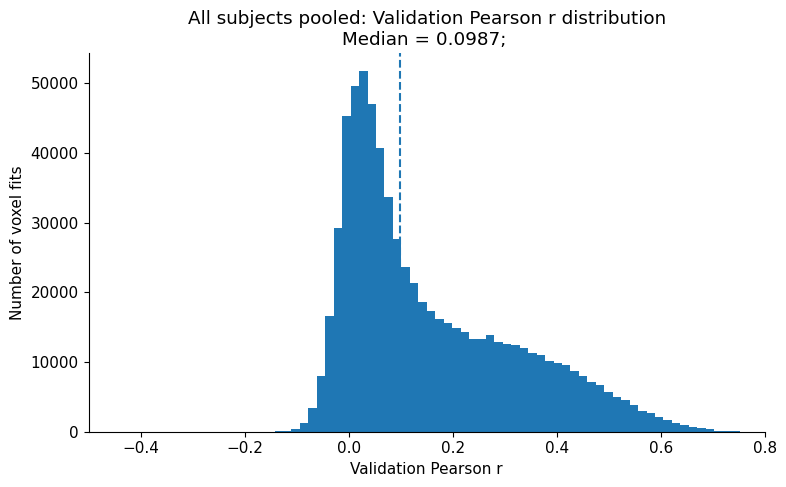

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_cc_subject_1.png


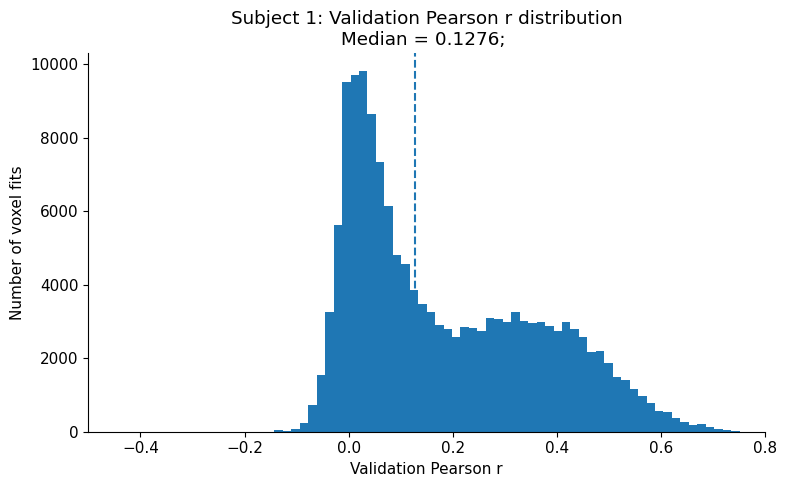

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_cc_subject_2.png


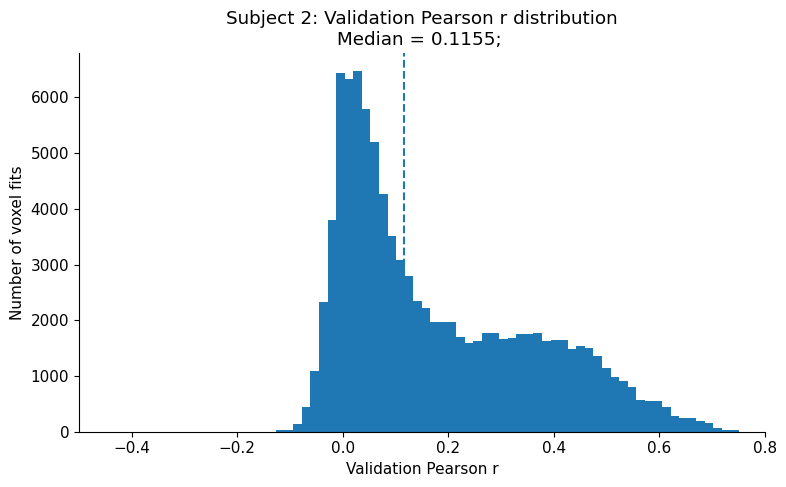

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_cc_subject_3.png


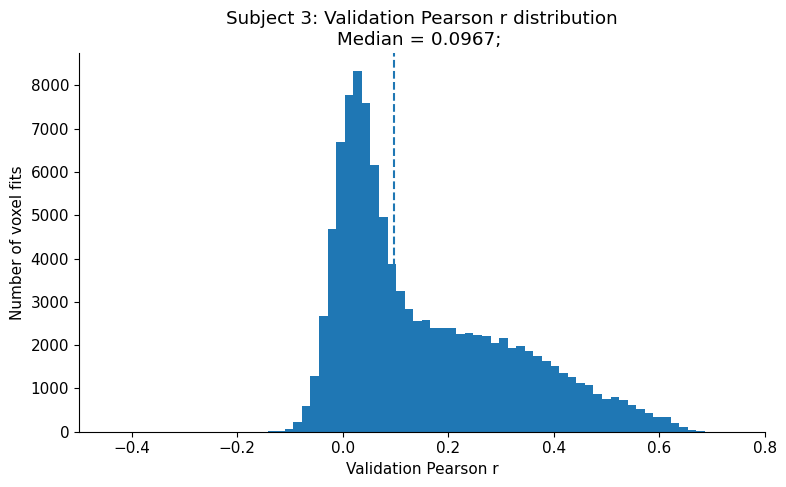

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_cc_subject_4.png


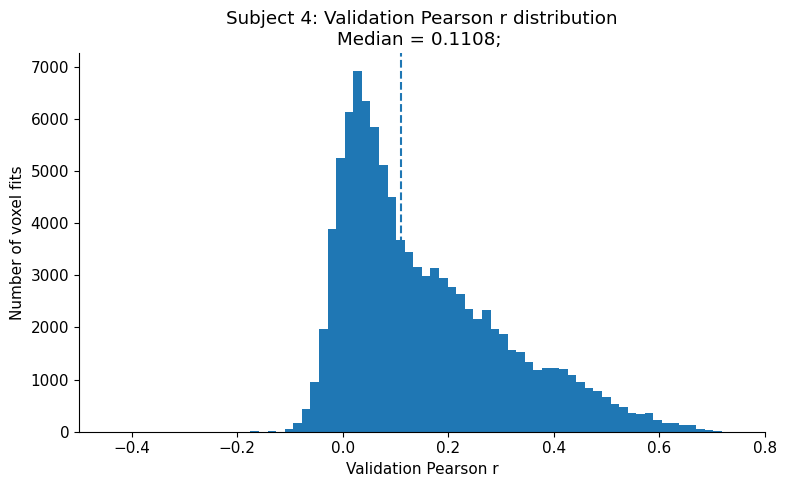

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_cc_subject_5.png


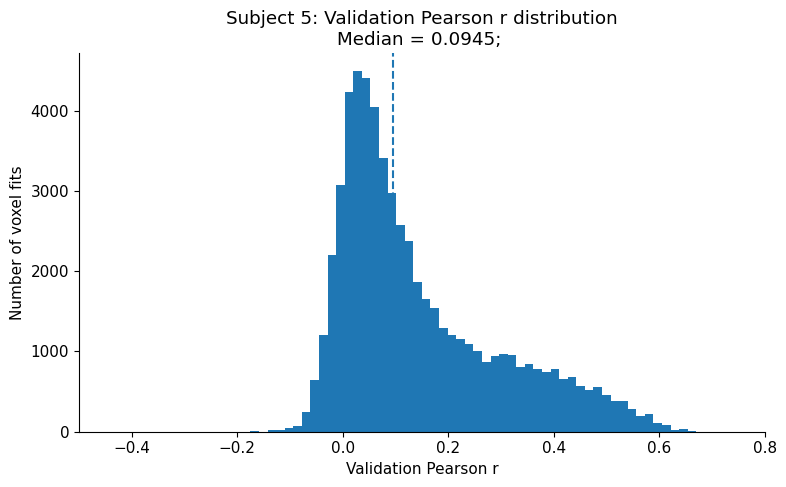

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_cc_subject_6.png


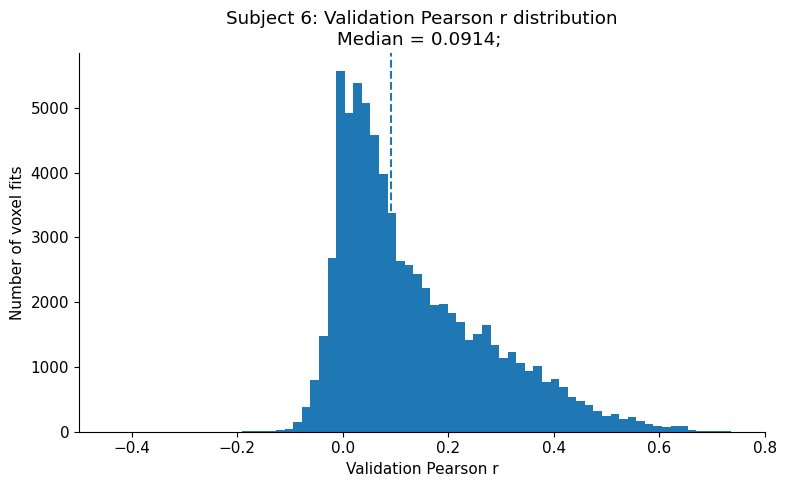

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_cc_subject_7.png


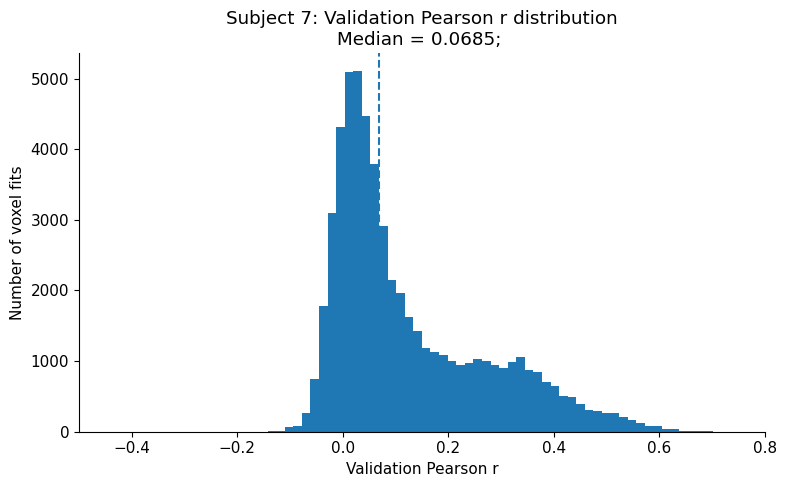

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_cc_subject_8.png


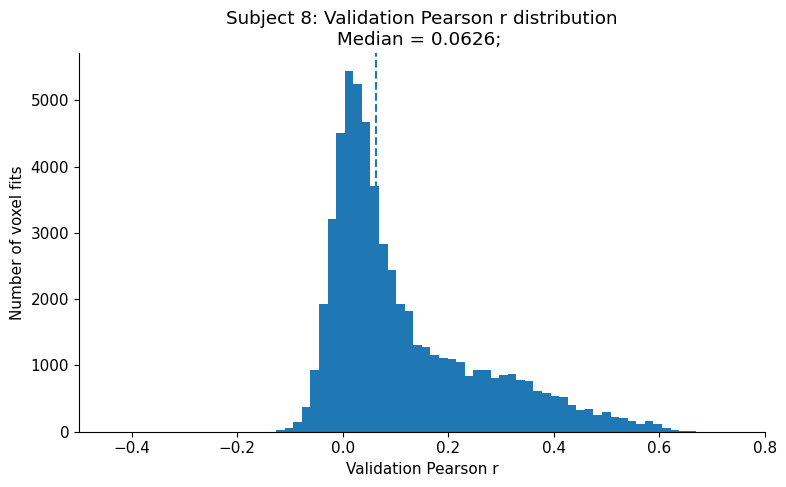

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_r2_all_subjects_pooled.png


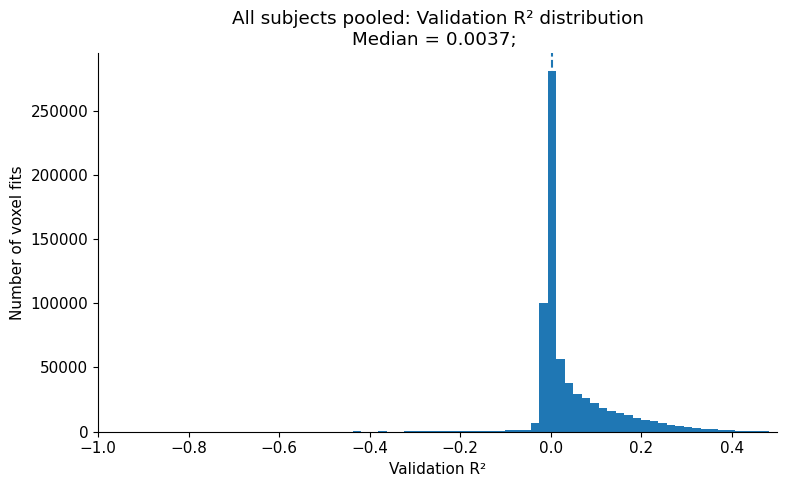

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_r2_subject_1.png


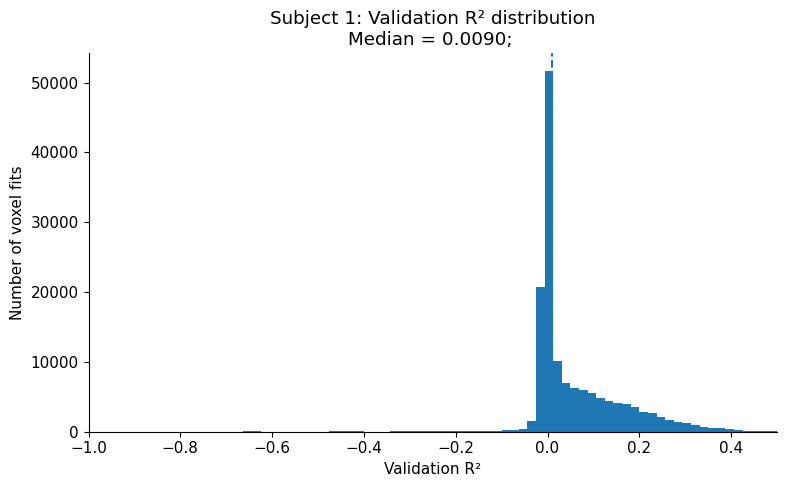

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_r2_subject_2.png


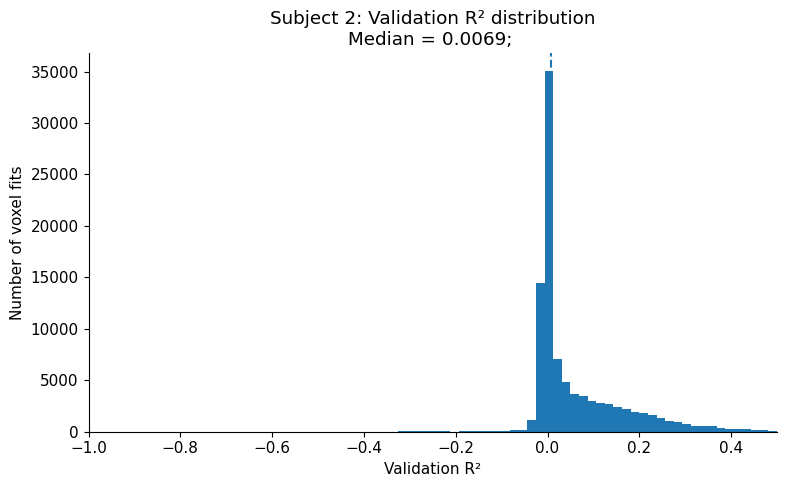

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_r2_subject_3.png


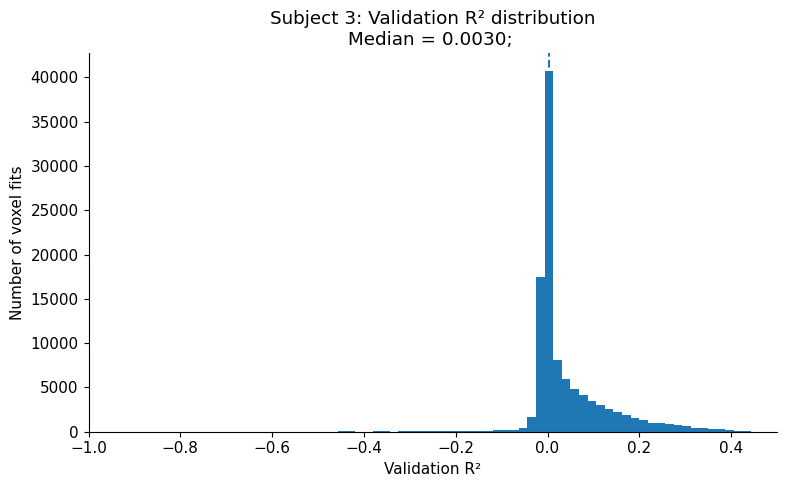

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_r2_subject_4.png


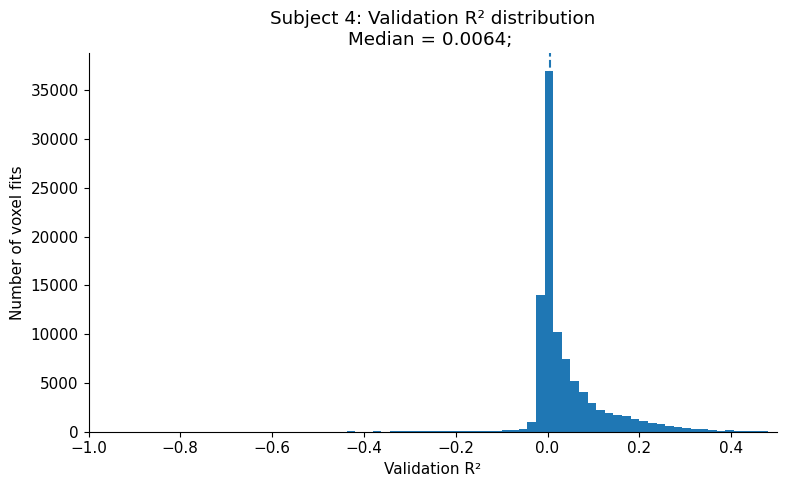

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_r2_subject_5.png


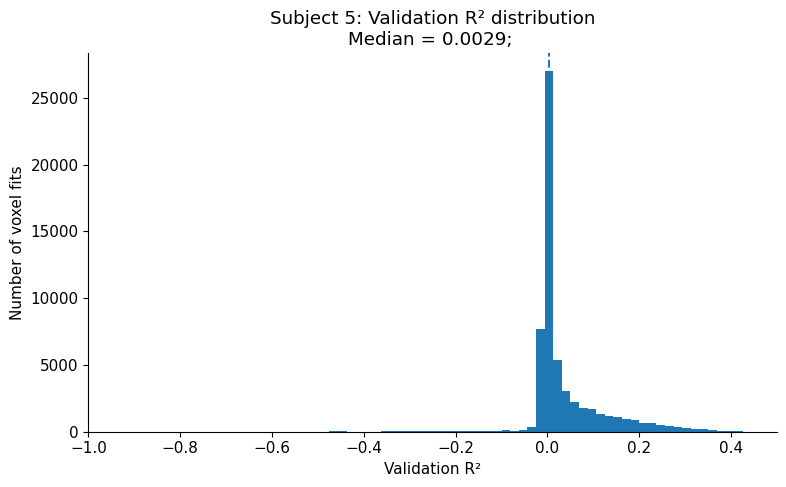

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_r2_subject_6.png


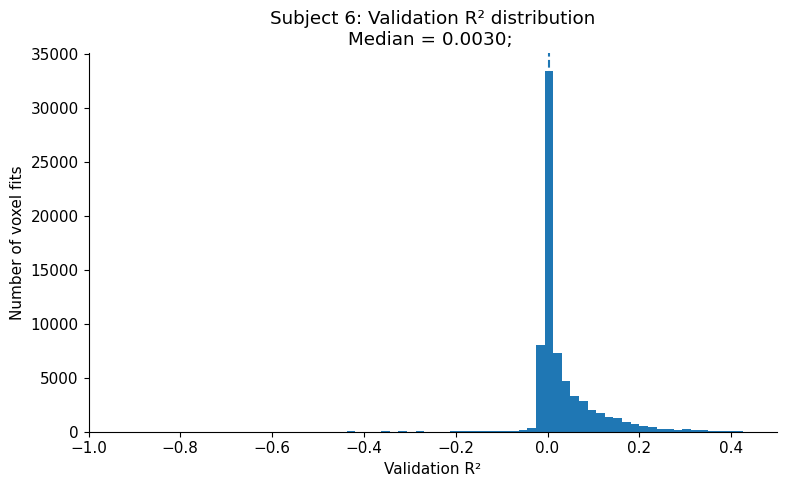

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_r2_subject_7.png


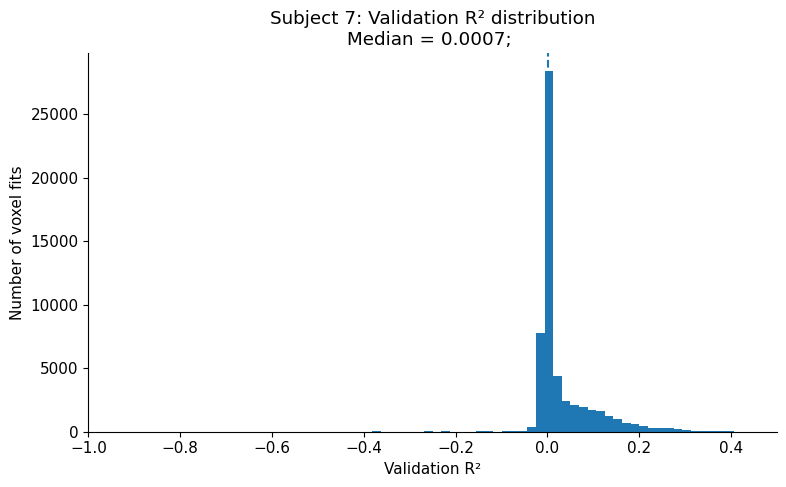

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/histograms/val_r2_subject_8.png


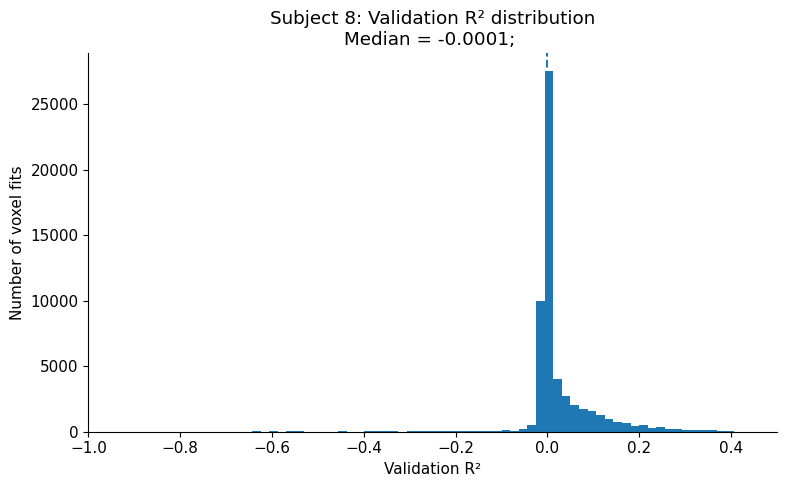

In [26]:
HIST_DIR = OUTPUT_DIR / "histograms"

plot_metric_histograms_by_subject(
    voxel_df,
    "val_cc",
    xlim=(-0.5, 0.8),
    save_dir=HIST_DIR,
)

plot_metric_histograms_by_subject(
    voxel_df,
    "val_r2",
    xlim=(-1, 0.5),
    save_dir=HIST_DIR,
)

## 7. Compare explained-variance thresholds

Each point in the following plots represents one subject's median voxel performance. Lines connect thresholds within the same subject, allowing us to distinguish a consistent threshold effect from a result driven by only one participant.

The thick group summary is intentionally not calculated by pooling all voxels. Instead, subjects contribute equally.

In [58]:
from matplotlib.lines import Line2D

def plot_threshold_comparison_both_pca(
    fit_summary: pd.DataFrame,
    metric: str = "median_r",
    roi: str | None = None,
    ridge: bool | None = None,
    save_dir: str | None = None,
) -> None:

    data = fit_summary[
        fit_summary["pca_type"].isin(["pcaHL", "pcaAll"])
    ].copy()

    if roi is not None:
        data = data[data["roi"] == roi]

    if ridge is not None:
        data = data[data["ridge"] == ridge]

    if data.empty:
        print("No matching data.")
        return

    subject_data = (
        data.groupby(
            ["subject", "threshold", "pca_type"],
            as_index=False,
        )[metric]
        .mean()
        .sort_values(
            ["subject", "pca_type", "threshold"]
        )
    )

    fig, ax = plt.subplots(figsize=(10, 5.5))

    subjects = sorted(subject_data["subject"].unique())
    colors = plt.cm.tab10(np.linspace(0, 1, len(subjects)))
    subject_colors = dict(zip(subjects, colors))

    line_styles = {
        "pcaHL": "-",
        "pcaAll": "--",
    }

    # Subject-level curves
    for subject in subjects:
        for pca_type in ["pcaHL", "pcaAll"]:

            sub = subject_data[
                (subject_data["subject"] == subject) &
                (subject_data["pca_type"] == pca_type)
            ].sort_values("threshold")

            if sub.empty:
                continue

            ax.plot(
                sub["threshold"],
                sub[metric],
                marker="o",
                linestyle=line_styles[pca_type],
                linewidth=1,
                alpha=0.45,
                color=subject_colors[subject],
                label=(
                    f"S{int(subject)}"
                    if pca_type == "pcaHL"
                    else None
                ),
            )

    # Across-subject mean ± SEM for each PCA type
    for pca_type in ["pcaHL", "pcaAll"]:

        group = (
            subject_data[
                subject_data["pca_type"] == pca_type
            ]
            .groupby("threshold")[metric]
            .agg(["mean", "sem"])
            .reset_index()
            .sort_values("threshold")
        )

        if group.empty:
            continue

        ax.errorbar(
            group["threshold"],
            group["mean"],
            yerr=group["sem"],
            marker="o",
            linestyle=line_styles[pca_type],
            linewidth=2.5,
            capsize=4,
            label=f"{pca_type} mean ± SEM",
        )

    title_parts = ["Threshold comparison: pcaHL vs pcaAll"]

    if roi is not None:
        title_parts.append(roi)

    # if ridge is not None:
    #     title_parts.append("Ridge" if ridge else "OLS")

    ax.set_title(" | ".join(title_parts))
    ax.set_xlabel("PCA explained-variance threshold (%)")
    ax.set_ylabel(metric.replace("_", " "))

    all_thresholds = sorted(
        subject_data["threshold"].dropna().unique()
    )
    ax.set_xticks(all_thresholds)

    handles, labels = ax.get_legend_handles_labels()

    # Keep only the subject entries from the automatic legend
    subject_handles = handles[:len(subjects)]

    style_handles = [
        Line2D(
            [0], [0],
            color="black",
            linestyle="-",
            linewidth=1.5,
            label="Solid: pcaHL",
        ),
        Line2D(
            [0], [0],
            color="black",
            linestyle=(0, (5, 3)),
            linewidth=1.5,
            label="Dashed: pcaAll",
        ),
    ]

    mean_handles = [
        Line2D(
            [0], [0],
            color="C0",
            marker="o",
            linestyle="-",
            linewidth=2.5,
            label="pcaHL mean ± SEM",
        ),
        Line2D(
            [0], [0],
            color="C1",
            marker="o",
            linestyle=(0, (5, 3)),
            linewidth=2.5,
            label="pcaAll mean ± SEM",
        ),
    ]

    ax.legend(
        handles=subject_handles + style_handles + mean_handles,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False,
        handlelength=3.5,
    )

    # Clean y-axis limits and ticks
    ymin = subject_data[metric].min()
    ymax = subject_data[metric].max()

    pad = 0.005

    tick_min = np.floor((ymin - pad) / 0.02) * 0.02
    tick_max = np.ceil((ymax + pad) / 0.02) * 0.02

    ax.set_ylim(tick_min, tick_max)
    ax.set_yticks(
        np.arange(
            tick_min,
            tick_max + 0.001,
            0.02,
        )
    )

    plt.tight_layout()

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)

        filename = "threshold_comparison_both_pca"

        if roi is not None:
            filename += f"_{roi}"

        if ridge is not None:
            filename += "_ridge" if ridge else "_ols"

        filename += f"_{metric}.png"

        filepath = os.path.join(save_dir, filename)

        plt.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight",
        )

        print(f"Saved: {filepath}")

    plt.show()
    plt.close(fig)

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/threshold_comparison_both_pca_V1_ols_median_r.png


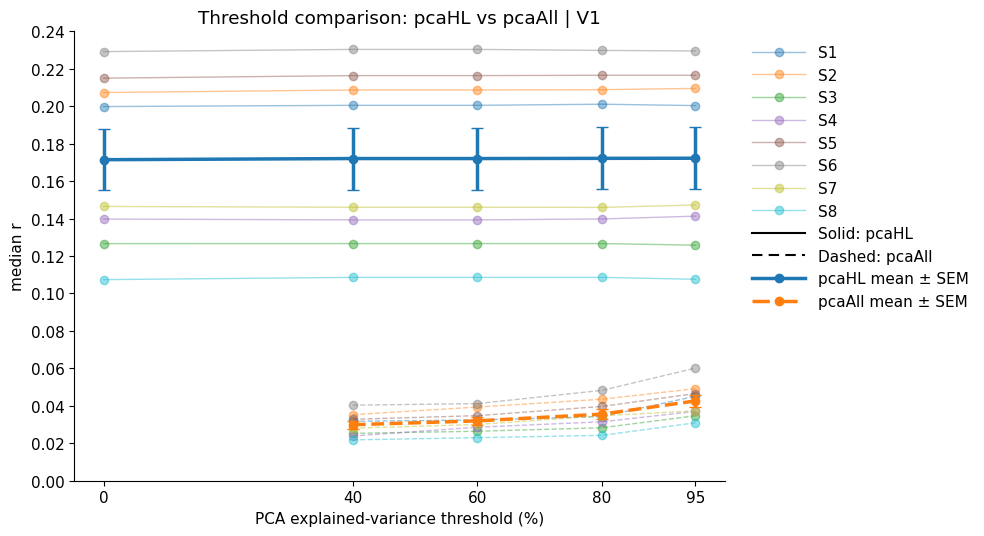

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/threshold_comparison_both_pca_V2_ols_median_r.png


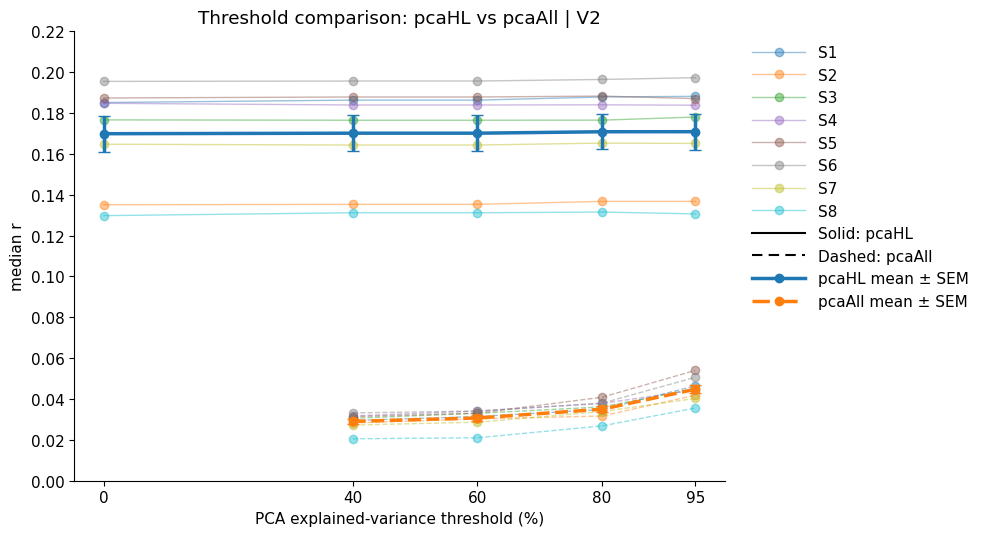

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/threshold_comparison_both_pca_V3_ols_median_r.png


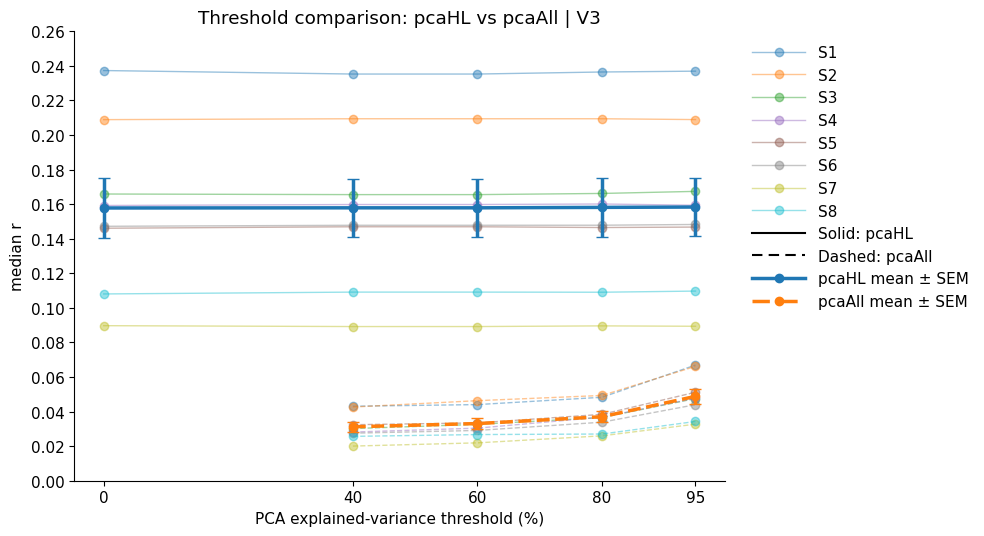

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/threshold_comparison_both_pca_hV4_ols_median_r.png


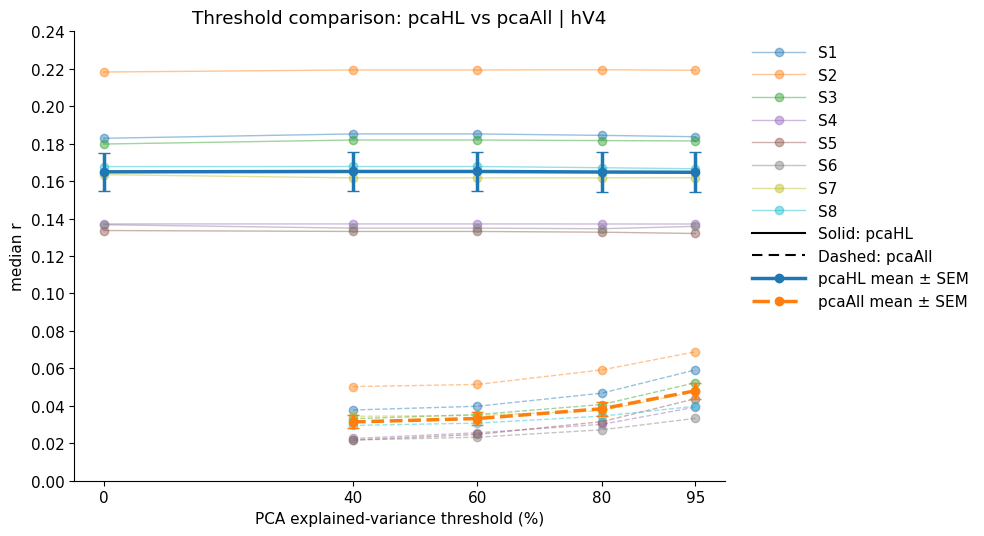

In [59]:
for roi in ROIS:
    plot_threshold_comparison_both_pca(
        fit_df,
        metric="median_r",
        roi=roi,
        ridge=False,
        save_dir=OUTPUT_DIR,
    )

## 8. Heatmaps across thresholds and ROIs

The heatmap summarizes the mean subject-level performance for every ROI and threshold. Separate panels are produced for each PCA strategy and regression type so that unavailable combinations remain visible as missing values.

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/configuration_heatmap_pcaHL_ols_median_r2.png


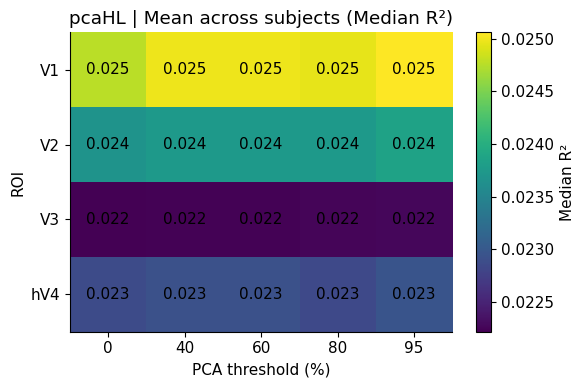

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/configuration_heatmap_pcaAll_ols_median_r2.png


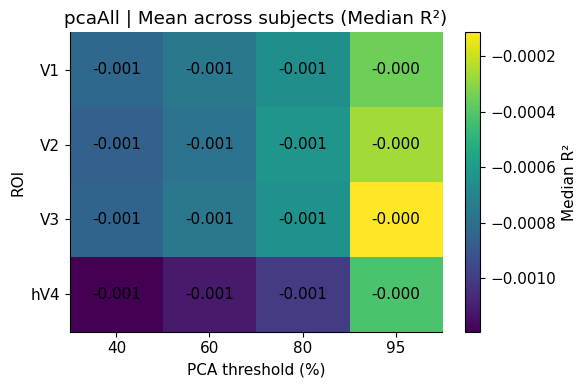

In [66]:
def plot_configuration_heatmap(
    fit_summary: pd.DataFrame,
    pca_type: str,
    metric: str = "median_r",
    ridge: bool = False,
    save_dir: str | None = None,
) -> pd.DataFrame:
    data = fit_summary[
        (fit_summary["pca_type"] == pca_type) &
        (fit_summary["ridge"] == ridge)
    ].copy()

    table = (
        data.groupby(["roi", "threshold"])[metric]
        .mean()
        .unstack("threshold")
        .reindex(ROI_ORDER)
    )

    if table.empty:
        print(f"No data for {pca_type}, ridge={ridge}.")
        return table

    fig, ax = plt.subplots(
        figsize=(1.2 * max(5, table.shape[1]), 1.0 * max(4, table.shape[0]))
    )

    image = ax.imshow(table.to_numpy(), aspect="auto")

    ax.set_xticks(np.arange(table.shape[1]))
    ax.set_xticklabels(table.columns)
    ax.set_yticks(np.arange(table.shape[0]))
    ax.set_yticklabels(table.index)

    ax.set_xlabel("PCA threshold (%)")
    ax.set_ylabel("ROI")
    metric_label = {
        "median_r": "Median Pearson r",
        "mean_r": "Mean Pearson r",
        "median_r2": "Median R²",
        "mean_r2": "Mean R²",
        "val_r2": "Validation R²",
        "val_cc": "Validation Pearson r",
    }.get(metric, metric.replace("_", " "))

    ax.set_title(
        f"{pca_type} | Mean across subjects ({metric_label})"
    )

    for row in range(table.shape[0]):
        for col in range(table.shape[1]):
            value = table.iloc[row, col]
            label = "NA" if pd.isna(value) else f"{value:.3f}"
            ax.text(col, row, label, ha="center", va="center")

    fig.colorbar(image, ax=ax, label=metric_label)
    plt.tight_layout()

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)

        filename = (
            f"configuration_heatmap_{pca_type}_"
            f"{'ridge' if ridge else 'ols'}_{metric}.png"
        )

        filepath = os.path.join(save_dir, filename)

        plt.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight",
        )

        print(f"Saved: {filepath}")

    plt.show()

    return table


heatmap_tables = {}
for pca_type in PCA_TYPES:
    heatmap_tables[(pca_type, "OLS")] = plot_configuration_heatmap(
        fit_df,
        pca_type=pca_type,
        metric="median_r2",  # "median_r2" or "median_r"
        ridge=False,
        save_dir=OUTPUT_DIR,
    )

## 9. Direct comparison of `pcaHL` and `pcaAll`

A fair PCA-strategy comparison requires matched subject, ROI, threshold, and regression settings. The next function performs this pairing explicitly.

A positive difference means that `pcaHL` outperformed `pcaAll`; a negative difference means that `pcaAll` performed better.

In [67]:
def paired_pca_type_table(
    fit_summary: pd.DataFrame,
    metric: str = "median_r",
    ridge: bool = False,
) -> pd.DataFrame:
    data = fit_summary[fit_summary["ridge"] == ridge].copy()

    paired = (
        data.pivot_table(
            index=["subject", "roi", "threshold"],
            columns="pca_type",
            values=metric,
            aggfunc="mean",
        )
        .reset_index()
    )

    if not {"pcaHL", "pcaAll"}.issubset(paired.columns):
        return pd.DataFrame()

    paired = paired.dropna(subset=["pcaHL", "pcaAll"]).copy()
    paired["pcaHL_minus_pcaAll"] = paired["pcaHL"] - paired["pcaAll"]

    return paired


paired_pca = paired_pca_type_table(
    fit_df,
    metric="median_r2",
    ridge=False,
)

display(paired_pca.head())
print("Matched comparisons:", len(paired_pca))

pca_type,subject,roi,threshold,pcaAll,pcaHL,pcaHL_minus_pcaAll
1,1,V1,40,-0.0006,0.0300,0.0306
2,1,V1,60,-0.0005,0.0300,0.0305
3,1,V1,80,-0.0005,0.0300,0.0305
4,1,V1,95,-0.0002,0.0299,0.0301
6,1,V2,40,-0.0009,0.0285,0.0294


Matched comparisons: 128


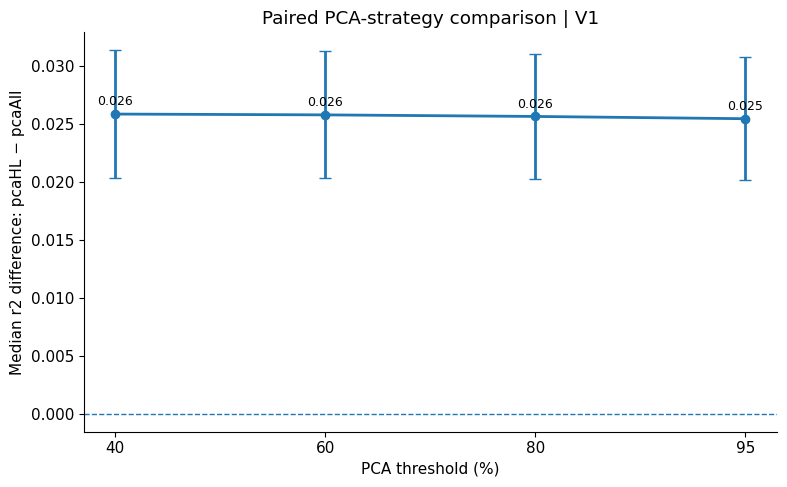

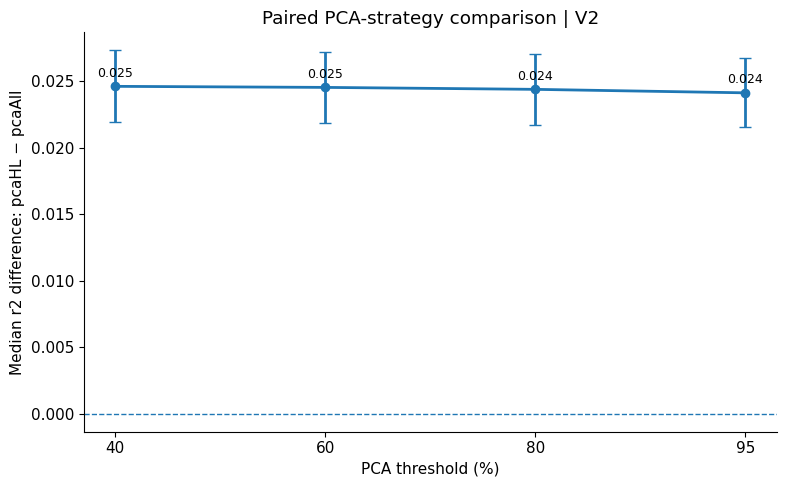

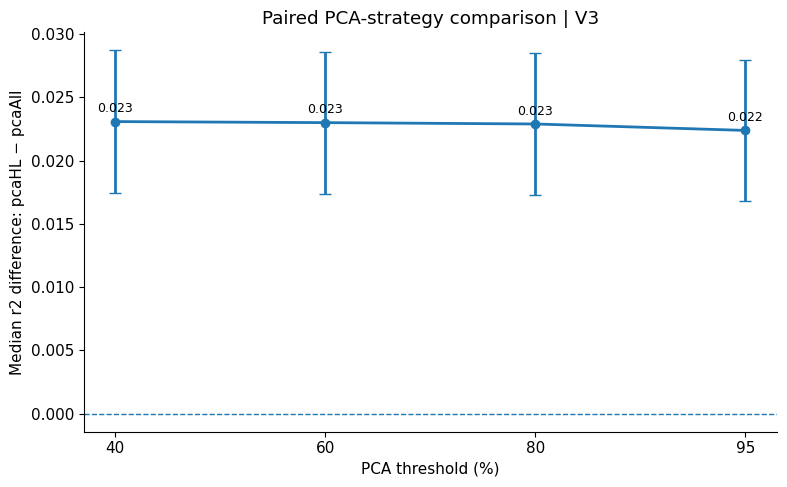

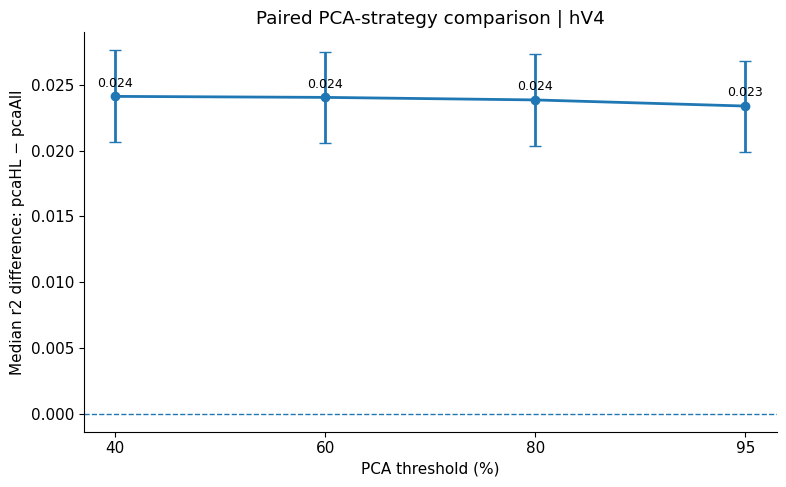

In [70]:
def plot_paired_pca_types(
    paired: pd.DataFrame,
    roi: str | None = None,
) -> None:
    data = paired.copy()

    if roi is not None:
        data = data[data["roi"] == roi]

    if data.empty:
        print("No matched PCA-type comparisons.")
        return

    thresholds = sorted(data["threshold"].unique())
    positions = np.arange(len(thresholds))

    mean_diff = (
        data.groupby("threshold")["pcaHL_minus_pcaAll"]
        .mean()
        .reindex(thresholds)
    )
    sem_diff = (
        data.groupby("threshold")["pcaHL_minus_pcaAll"]
        .sem()
        .reindex(thresholds)
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.errorbar(
        positions,
        mean_diff,
        yerr=sem_diff,
        marker="o",
        capsize=4,
        linewidth=2,
    )
    for x, y in zip(positions, mean_diff):
        ax.text(
            x,
            y + 0.0005,
            f"{y:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )
    ax.set_xticks(positions)
    ax.set_xticklabels(thresholds)
    ax.set_xlabel("PCA threshold (%)")
    ax.set_ylabel("Median r2 difference: pcaHL − pcaAll")
    ax.set_title(
        "Paired PCA-strategy comparison"
        + (f" | {roi}" if roi is not None else "")
    )
    plt.tight_layout()
    plt.show()


for roi in ROIS:
    plot_paired_pca_types(paired_pca, roi=roi)

# If performance is essentially the same, how many features does each threshold require?

Found 9 PCA summary files.
S5_4ori_4sf_PCA_high_level_grid5_summary.csv
S6_4ori_4sf_PCA_high_level_grid5_summary.csv
S7_4ori_4sf_PCA_high_level_grid5_summary.csv
S8_4ori_4sf_PCA_high_level_grid5_summary.csv
S4_4ori_4sf_PCA_all_features_grid5_summary.csv
S5_4ori_4sf_PCA_all_features_grid5_summary.csv
S6_4ori_4sf_PCA_all_features_grid5_summary.csv
S7_4ori_4sf_PCA_all_features_grid5_summary.csv
S8_4ori_4sf_PCA_all_features_grid5_summary.csv
Skipping 0% in S4_4ori_4sf_PCA_all_features_grid5_summary.csv: missing n_components_0
Skipping 0% in S5_4ori_4sf_PCA_all_features_grid5_summary.csv: missing n_components_0
Skipping 0% in S6_4ori_4sf_PCA_all_features_grid5_summary.csv: missing n_components_0
Skipping 0% in S7_4ori_4sf_PCA_all_features_grid5_summary.csv: missing n_components_0
Skipping 0% in S8_4ori_4sf_PCA_all_features_grid5_summary.csv: missing n_components_0

Example pRF-level feature counts:


,subject,pca_type,threshold,prf,n_retained_pcs,total_features
29120,4,pcaAll,40,0,1,1
29121,4,pcaAll,40,1,1,1
29122,4,pcaAll,40,2,1,1
29123,4,pcaAll,40,3,1,1
29124,4,pcaAll,40,4,1,1
29125,4,pcaAll,40,5,1,1
29126,4,pcaAll,40,6,1,1
29127,4,pcaAll,40,7,1,1
29128,4,pcaAll,40,8,1,1
29129,4,pcaAll,40,9,1,1



Feature-count summary by subject:


,subject,pca_type,threshold,n_prfs,mean_retained_pcs,median_retained_pcs,min_retained_pcs,max_retained_pcs,mean_total_features,median_total_features,min_total_features,max_total_features
0,4,pcaAll,40,1456,1.0000,1.0000,1,1,1.0000,1.0000,1,1
4,5,pcaAll,40,1456,1.0030,1.0000,1,2,1.0030,1.0000,1,2
13,6,pcaAll,40,1456,1.0010,1.0000,1,2,1.0010,1.0000,1,2
22,7,pcaAll,40,1456,1.0010,1.0000,1,2,1.0010,1.0000,1,2
31,8,pcaAll,40,1456,1.0030,1.0000,1,2,1.0030,1.0000,1,2
1,4,pcaAll,60,1456,1.0410,1.0000,1,2,1.0410,1.0000,1,2
5,5,pcaAll,60,1456,1.0480,1.0000,1,2,1.0480,1.0000,1,2
14,6,pcaAll,60,1456,1.0460,1.0000,1,2,1.0460,1.0000,1,2
23,7,pcaAll,60,1456,1.0440,1.0000,1,2,1.0440,1.0000,1,2
32,8,pcaAll,60,1456,1.0480,1.0000,1,2,1.0480,1.0000,1,2


,subject,roi,pca_type,threshold
28,1,V1,pcaAll,40
29,1,V2,pcaAll,40
30,1,V3,pcaAll,40
31,1,hV4,pcaAll,40
60,2,V1,pcaAll,40
...,...,...,...,...
75,3,hV4,pcaHL,95
108,4,V1,pcaHL,95
109,4,V2,pcaHL,95
110,4,V3,pcaHL,95



Performance and model-complexity summary:


,roi,pca_type,threshold,n_subjects,mean_median_r2,sem_median_r2,mean_total_features,sem_total_features,mean_retained_pcs
0,V1,pcaAll,40,8,-0.0008,0.0001,1.0016,0.0006,1.0016
1,V1,pcaAll,60,8,-0.0008,0.0001,1.0455,0.0013,1.0455
2,V1,pcaAll,80,8,-0.0007,0.0001,1.2261,0.0035,1.2261
3,V1,pcaAll,95,8,-0.0003,0.0001,1.8214,0.0141,1.8214
4,V1,pcaHL,0,8,0.0248,0.0054,49.0000,0.0000,0.0000
5,V1,pcaHL,40,8,0.0250,0.0055,50.0000,0.0000,1.0000
6,V1,pcaHL,60,8,0.0250,0.0055,50.0000,0.0000,1.0000
7,V1,pcaHL,80,8,0.0249,0.0055,50.2261,0.0029,1.2261
8,V1,pcaHL,95,8,0.0251,0.0054,50.7639,0.0033,1.7639
9,V2,pcaAll,40,8,-0.0009,0.0001,1.0016,0.0006,1.0016


Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/performance_and_complexity_V1_OLS_median_r2.png


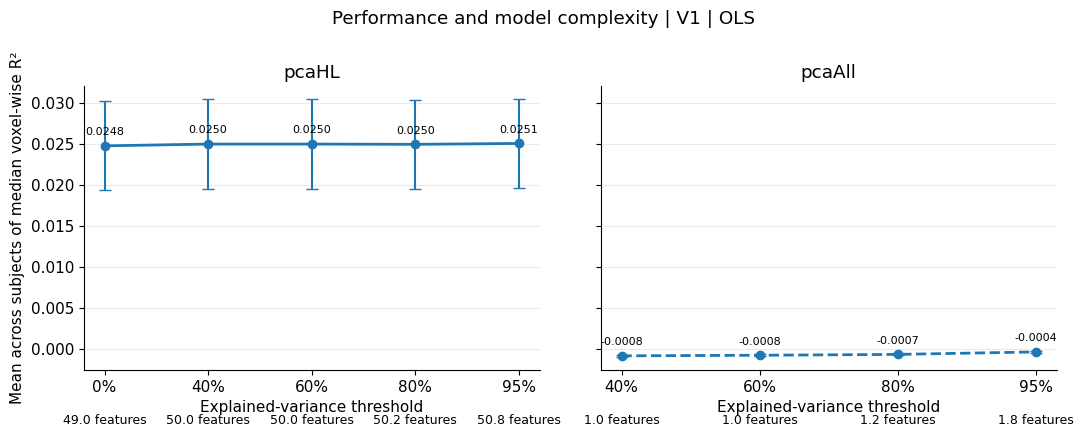

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/performance_and_complexity_V2_OLS_median_r2.png


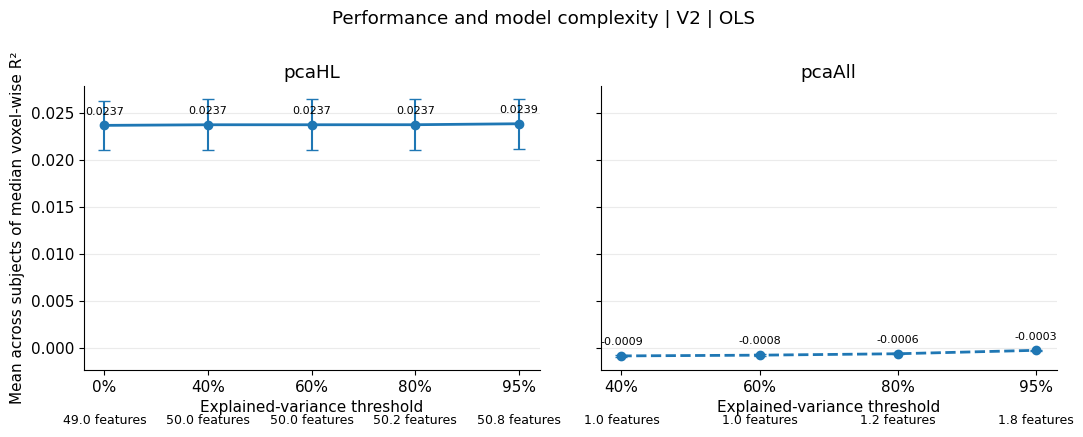

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/performance_and_complexity_V3_OLS_median_r2.png


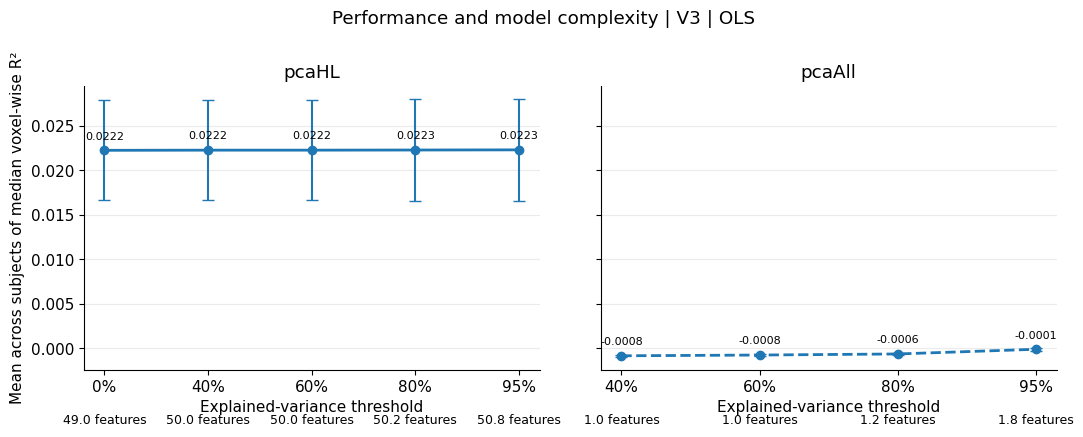

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/performance_and_complexity_hV4_OLS_median_r2.png


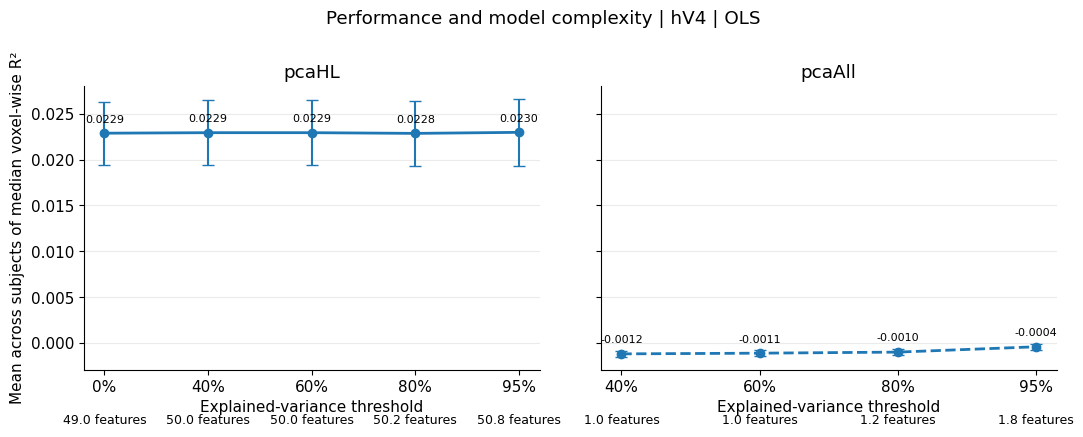

In [83]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Performance versus number of retained features
# ============================================================

PCA_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture"
)

THRESHOLDS_TO_COMPARE = [0, 40, 60, 80, 95]

# In pcaHL, the 49 low-level features remain uncompressed.
N_LOW_LEVEL_FEATURES = 49

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. Locate the per-subject PCA summary files
# ------------------------------------------------------------

summary_files = (
    sorted(
        (
            PCA_ROOT
            / "PCA_pcaHL_MULTI"
            / "checkpoints"
        ).glob("*_summary.csv")
    )
    +
    sorted(
        (
            PCA_ROOT
            / "PCA_pcaAll_MULTI"
            / "checkpoints"
        ).glob("*_summary.csv")
    )
)

if not summary_files:
    raise FileNotFoundError(
        "No PCA checkpoint summary CSV files were found."
    )

print(f"Found {len(summary_files)} PCA summary files.")

for path in summary_files:
    print(path.name)


# ------------------------------------------------------------
# 2. Load retained PCA-component counts for every pRF
# ------------------------------------------------------------

component_rows = []

for path in summary_files:
    table = pd.read_csv(path)

    required_metadata = {
        "subject",
        "pca_type",
        "prf",
    }

    missing_metadata = required_metadata - set(table.columns)

    if missing_metadata:
        print(
            f"Skipping {path.name}: missing columns "
            f"{sorted(missing_metadata)}"
        )
        continue

    for threshold in THRESHOLDS_TO_COMPARE:
        component_column = f"n_components_{threshold}"

        if component_column not in table.columns:
            print(
                f"Skipping {threshold}% in {path.name}: "
                f"missing {component_column}"
            )
            continue

        current = table[
            [
                "subject",
                "pca_type",
                "prf",
                component_column,
            ]
        ].copy()

        current = current.rename(
            columns={
                component_column: "n_retained_pcs",
            }
        )

        current["threshold"] = threshold
        current["source_file"] = str(path)

        component_rows.append(current)


if not component_rows:
    raise RuntimeError(
        "No retained PCA-component information could be loaded."
    )

prf_feature_df = pd.concat(
    component_rows,
    ignore_index=True,
)

# Normalize data types.
prf_feature_df["subject"] = pd.to_numeric(
    prf_feature_df["subject"],
    errors="coerce",
)

prf_feature_df["threshold"] = pd.to_numeric(
    prf_feature_df["threshold"],
    errors="coerce",
)

prf_feature_df["n_retained_pcs"] = pd.to_numeric(
    prf_feature_df["n_retained_pcs"],
    errors="coerce",
)

prf_feature_df = prf_feature_df.dropna(
    subset=[
        "subject",
        "pca_type",
        "threshold",
        "n_retained_pcs",
    ]
)

prf_feature_df["subject"] = (
    prf_feature_df["subject"].astype(int)
)

prf_feature_df["threshold"] = (
    prf_feature_df["threshold"].astype(int)
)


# ------------------------------------------------------------
# 3. Compute total features for every subject × pRF
# ------------------------------------------------------------

prf_feature_df["total_features"] = np.where(
    prf_feature_df["pca_type"].eq("pcaHL"),
    N_LOW_LEVEL_FEATURES
    + prf_feature_df["n_retained_pcs"],
    prf_feature_df["n_retained_pcs"],
)


print("\nExample pRF-level feature counts:")

display(
    prf_feature_df[
        [
            "subject",
            "pca_type",
            "threshold",
            "prf",
            "n_retained_pcs",
            "total_features",
        ]
    ]
    .sort_values(
        [
            "subject",
            "pca_type",
            "threshold",
            "prf",
        ]
    )
    .head(20)
)


# ------------------------------------------------------------
# 4. Summarize feature count per subject and configuration
# ------------------------------------------------------------

subject_feature_summary = (
    prf_feature_df
    .groupby(
        [
            "subject",
            "pca_type",
            "threshold",
        ],
        as_index=False,
    )
    .agg(
        n_prfs=("prf", "nunique"),

        mean_retained_pcs=(
            "n_retained_pcs",
            "mean",
        ),
        median_retained_pcs=(
            "n_retained_pcs",
            "median",
        ),
        min_retained_pcs=(
            "n_retained_pcs",
            "min",
        ),
        max_retained_pcs=(
            "n_retained_pcs",
            "max",
        ),

        mean_total_features=(
            "total_features",
            "mean",
        ),
        median_total_features=(
            "total_features",
            "median",
        ),
        min_total_features=(
            "total_features",
            "min",
        ),
        max_total_features=(
            "total_features",
            "max",
        ),
    )
)


print("\nFeature-count summary by subject:")

display(
    subject_feature_summary
    .sort_values(
        [
            "pca_type",
            "threshold",
            "subject",
        ]
    )
    .round(3)
)


# ------------------------------------------------------------
# 5. Merge feature counts with each completed model fit
# ------------------------------------------------------------

fit_with_features = fit_df.merge(
    subject_feature_summary,
    on=[
        "subject",
        "pca_type",
        "threshold",
    ],
    how="left",
    validate="many_to_one",
)


missing_features = (
    fit_with_features["mean_total_features"].isna()
)

if missing_features.any():
    print(
        "\nWarning: feature counts were not found for "
        f"{missing_features.sum()} fit rows."
    )

    display(
        fit_with_features.loc[
            missing_features,
            [
                "subject",
                "roi",
                "pca_type",
                "threshold",
            ],
        ]
        .drop_duplicates()
        .sort_values(
            [
                "pca_type",
                "threshold",
                "subject",
                "roi",
            ]
        )
    )


# ------------------------------------------------------------
# 6. Summarize performance across subjects
# ------------------------------------------------------------

performance_complexity_summary = (
    fit_with_features[
        (fit_with_features["ridge"] == False)
        &
        (
            fit_with_features["threshold"]
            .isin(THRESHOLDS_TO_COMPARE)
        )
    ]
    .groupby(
        [
            "roi",
            "pca_type",
            "threshold",
        ],
        as_index=False,
    )
    .agg(
        n_subjects=("subject", "nunique"),

        mean_median_r2=(
            "median_r2",
            "mean",
        ),
        sem_median_r2=(
            "median_r2",
            "sem",
        ),

        mean_total_features=(
            "mean_total_features",
            "mean",
        ),
        sem_total_features=(
            "mean_total_features",
            "sem",
        ),

        mean_retained_pcs=(
            "mean_retained_pcs",
            "mean",
        ),
    )
)


print("\nPerformance and model-complexity summary:")

display(
    performance_complexity_summary
    .sort_values(
        [
            "roi",
            "pca_type",
            "threshold",
        ]
    )
    .round(5)
)


# ------------------------------------------------------------
# 7. Plot performance versus threshold, with model complexity
#    shown separately for pcaHL and pcaAll
# ------------------------------------------------------------

for roi in ROI_ORDER:

    roi_data = performance_complexity_summary[
        performance_complexity_summary["roi"].eq(roi)
    ].copy()

    if roi_data.empty:
        continue

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11, 4.5),
        sharey=True,
    )

    for ax, pca_type, linestyle in zip(
        axes,
        ["pcaHL", "pcaAll"],
        ["-", "--"],
    ):

        sub = (
            roi_data[
                roi_data["pca_type"].eq(pca_type)
            ]
            .sort_values("threshold")
        )

        if sub.empty:
            ax.set_visible(False)
            continue

        x = np.arange(len(sub))

        # Mean performance line
        ax.plot(
            x,
            sub["mean_median_r2"],
            marker="o",
            linestyle=linestyle,
            linewidth=2,
            markersize=6,
        )

        # SEM across subjects
        ax.errorbar(
            x,
            sub["mean_median_r2"],
            yerr=sub["sem_median_r2"],
            fmt="none",
            capsize=4,
        )

        # Threshold labels on x-axis
        ax.set_xticks(x)
        ax.set_xticklabels(
            [f"{int(t)}%" for t in sub["threshold"]]
        )

        ax.set_xlabel("Explained-variance threshold")

        # Add feature count beneath each threshold
        for x_pos, (_, row) in zip(x, sub.iterrows()):

            ax.annotate(
                f"{row['mean_total_features']:.1f} features",
                xy=(x_pos, 0),
                xycoords=(
                    "data",
                    "axes fraction",
                ),
                xytext=(0, -32),
                textcoords="offset points",
                ha="center",
                va="top",
                fontsize=9,
            )

            # Optional value label above each point
            ax.annotate(
                f"{row['mean_median_r2']:.4f}",
                (
                    x_pos,
                    row["mean_median_r2"],
                ),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                fontsize=8,
            )

        ax.set_title(pca_type)
        ax.grid(
            axis="y",
            alpha=0.25,
        )

    axes[0].set_ylabel(
        "Mean across subjects of median voxel-wise R²"
    )

    fig.suptitle(
        f"Performance and model complexity | {roi} | OLS",
        y=1.02,
    )

    # Extra bottom space for feature-count labels
    plt.tight_layout()
    plt.subplots_adjust(
        bottom=0.22,
        top=0.85,
    )

    save_path = OUTPUT_DIR / (
        f"performance_and_complexity_"
        f"{roi}_OLS_median_r2.png"
    )

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
    )

    print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/pooled_feature_distribution_v0_both_pca_types.png


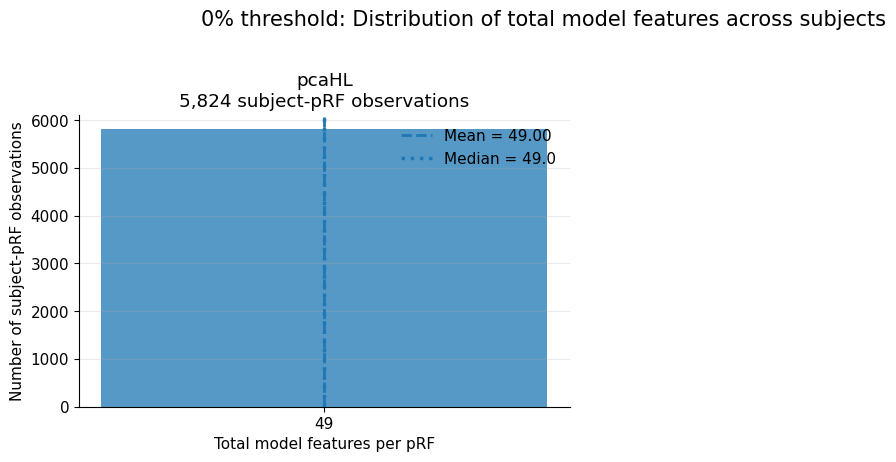

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/pooled_feature_distribution_v40_both_pca_types.png


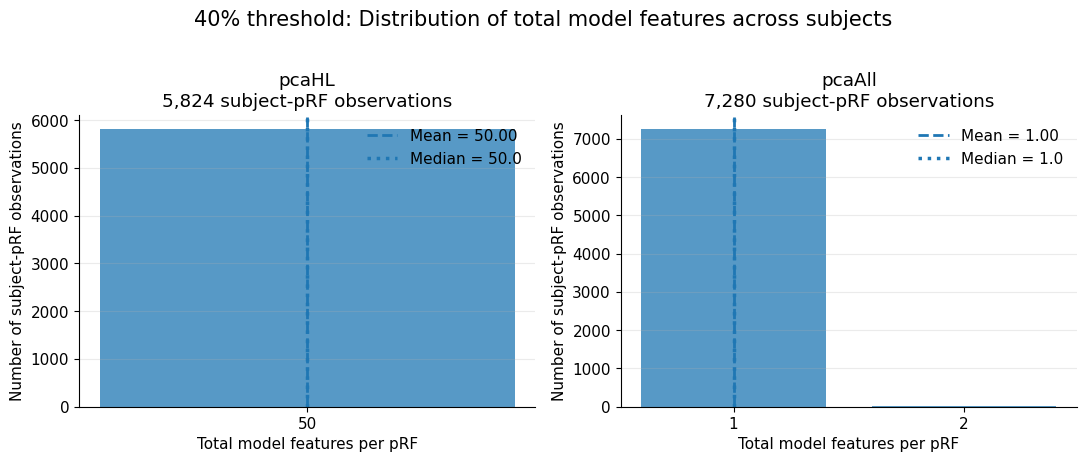

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/pooled_feature_distribution_v60_both_pca_types.png


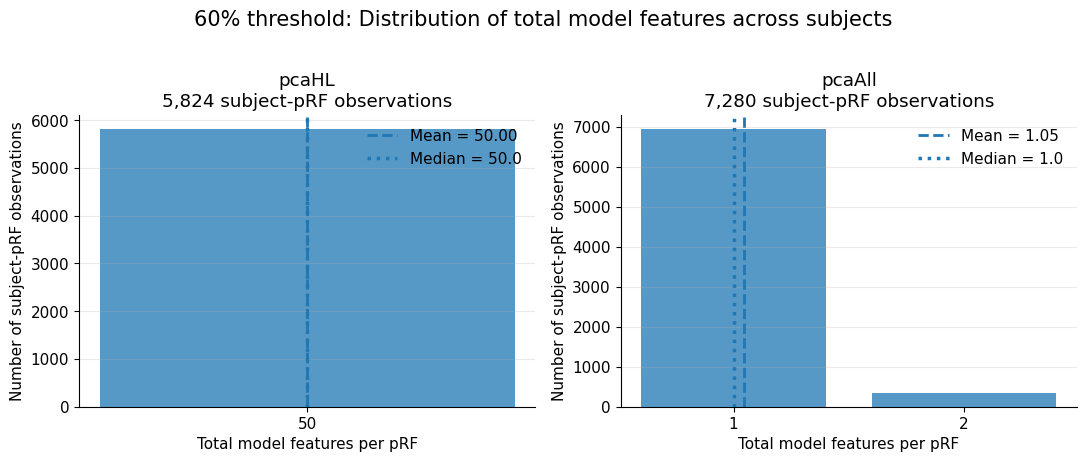

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/pooled_feature_distribution_v80_both_pca_types.png


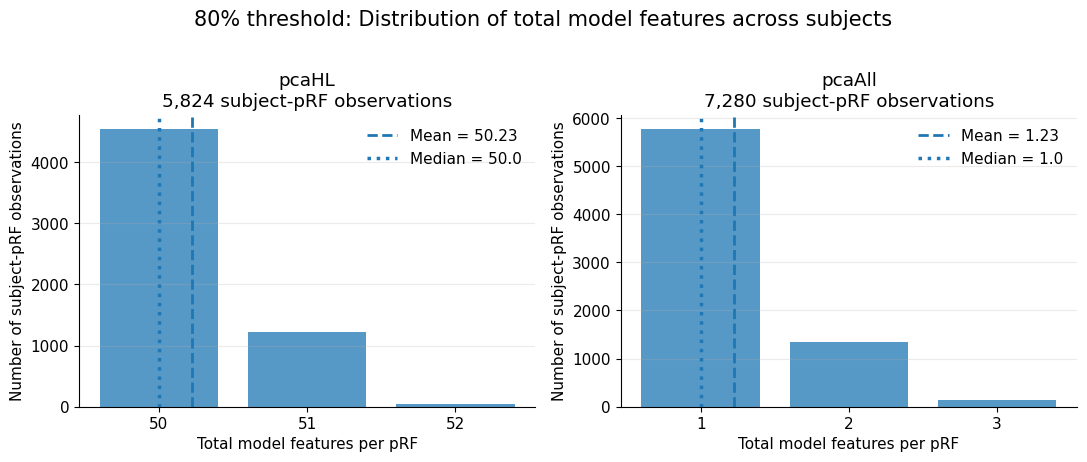

Saved: /content/drive/MyDrive/V2_drift/texturemodel/analysis/PCA_configuration/pooled_feature_distribution_v95_both_pca_types.png


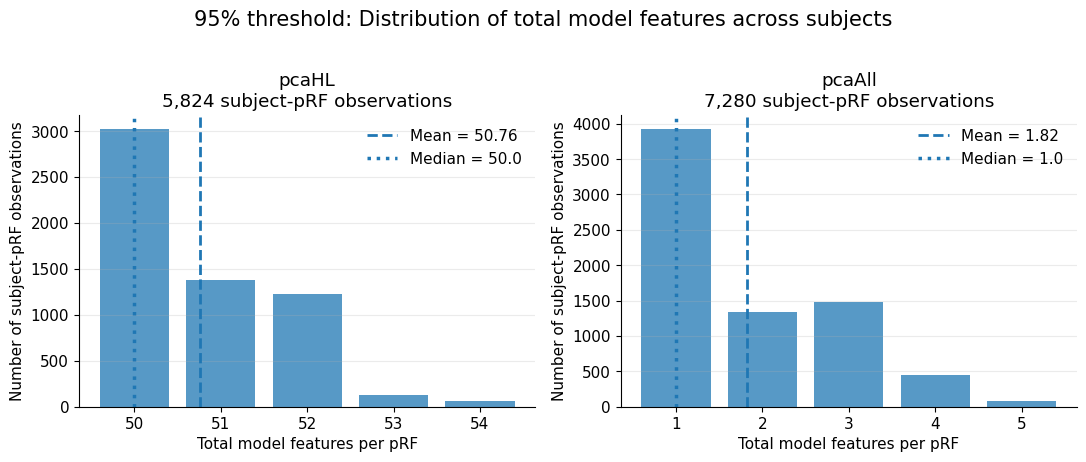

In [86]:
# ============================================================
# Pooled feature-count distributions across all subjects
# One figure per threshold, two panels: pcaHL and pcaAll
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


thresholds = sorted(
    prf_feature_df["threshold"].unique()
)

for threshold in thresholds:

    threshold_data = prf_feature_df[
        prf_feature_df["threshold"].eq(threshold)
    ].copy()

    if threshold_data.empty:
        continue

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11, 4.5),
        sharey=False,
    )

    for ax, pca_type in zip(
        axes,
        ["pcaHL", "pcaAll"],
    ):

        values = (
            threshold_data.loc[
                threshold_data["pca_type"].eq(pca_type),
                "total_features",
            ]
            .dropna()
            .astype(int)
        )

        if values.empty:
            ax.set_visible(False)
            continue

        counts = (
            values.value_counts()
            .sort_index()
        )

        mean_value = values.mean()
        median_value = values.median()

        n_subjects = threshold_data.loc[
            threshold_data["pca_type"].eq(pca_type),
            "subject",
        ].nunique()

        n_prfs_total = len(values)

        ax.bar(
            counts.index,
            counts.values,
            width=0.8,
            alpha=0.75,
        )

        ax.axvline(
            mean_value,
            linestyle="--",
            linewidth=2,
            label=f"Mean = {mean_value:.2f}",
        )

        ax.axvline(
            median_value,
            linestyle=":",
            linewidth=2.5,
            label=f"Median = {median_value:.1f}",
        )

        ax.set_title(
            f"{pca_type}\n"
            f"{n_prfs_total:,} subject-pRF observations"
        )

        ax.set_xlabel(
            "Total model features per pRF"
        )

        ax.set_ylabel(
            "Number of subject-pRF observations"
        )

        ax.set_xticks(
            np.arange(
                int(values.min()),
                int(values.max()) + 1,
            )
        )

        ax.grid(
            axis="y",
            alpha=0.25,
        )

        ax.legend(
            frameon=False,
        )

    fig.suptitle(
        f"{threshold}% threshold: "
        f"Distribution of total model features across subjects",
        fontsize=15,
        y=1.02,
    )

    plt.tight_layout()

    save_path = OUTPUT_DIR / (
        f"pooled_feature_distribution_"
        f"v{threshold}_both_pca_types.png"
    )

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
    )

    print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)

## 10. Compare subjects

The subject-level table makes it possible to assess whether one configuration performs well consistently or only for a subset of participants.

In [32]:
subject_table = (
    fit_df.pivot_table(
        index=["subject", "roi"],
        columns=["pca_type", "threshold"],
        values="median_r",
        aggfunc="mean",
    )
    .sort_index()
)

display(subject_table)

pca_type    pcaAll                       pcaHL                            
threshold       40     60     80     95     0      40     60     80     95
subject roi                                                               
1       V1  0.0317 0.0324 0.0343 0.0451 0.1998 0.2005 0.2005 0.2011 0.2003
        V2  0.0295 0.0314 0.0349 0.0464 0.1851 0.1863 0.1863 0.1879 0.1882
        V3  0.0431 0.0440 0.0483 0.0669 0.2373 0.2353 0.2353 0.2365 0.2370
        hV4 0.0378 0.0398 0.0468 0.0592 0.1829 0.1852 0.1852 0.1844 0.1837
2       V1  0.0353 0.0393 0.0435 0.0492 0.2073 0.2087 0.2087 0.2088 0.2095
        V2  0.0283 0.0303 0.0317 0.0419 0.1351 0.1353 0.1353 0.1368 0.1368
        V3  0.0426 0.0463 0.0493 0.0662 0.2089 0.2094 0.2094 0.2094 0.2089
        hV4 0.0503 0.0514 0.0592 0.0689 0.2183 0.2194 0.2194 0.2195 0.2192
3       V1  0.0253 0.0264 0.0283 0.0347 0.1266 0.1266 0.1266 0.1266 0.1258
        V2  0.0306 0.0330 0.0361 0.0451 0.1767 0.1765 0.1765 0.1765 0.1780
        V3  0.0302 0.0326 0.0366 0.0475 0.1659 0.1655 0.1655 0.1662 0.1674
        hV4 0.0331 0.0353 0.0407 0.0524 0.1798 0.1820 0.1820 0.1817 0.1815
4       V1  0.0239 0.0286 0.0315 0.0370 0.1397 0.1393 0.1393 0.1398 0.1413
        V2  0.0317 0.0341 0.0378 0.0445 0.1848 0.1839 0.1839 0.1840 0.1838
        V3  0.0281 0.0304 0.0368 0.0477 0.1592 0.1598 0.1598 0.1601 0.1594
        hV4 0.0226 0.0256 0.0301 0.0393 0.1371 0.1371 0.1371 0.1371 0.1371
5       V1  0.0328 0.0348 0.0397 0.0466 0.2150 0.2164 0.2164 0.2165 0.2165
        V2  0.0314 0.0331 0.0409 0.0540 0.1874 0.1879 0.1879 0.1883 0.1871
        V3  0.0324 0.0334 0.0384 0.0512 0.1461 0.1469 0.1469 0.1465 0.1468
        hV4 0.0217 0.0247 0.0316 0.0438 0.1336 0.1331 0.1331 0.1327 0.1320
6       V1  0.0403 0.0412 0.0483 0.0601 0.2292 0.2303 0.2303 0.2298 0.2295
        V2  0.0332 0.0341 0.0380 0.0506 0.1955 0.1957 0.1957 0.1964 0.1973
        V3  0.0275 0.0291 0.0339 0.0440 0.1472 0.1478 0.1478 0.1478 0.1483
        hV4 0.0217 0.0232 0.0272 0.0333 0.1367 0.1349 0.1349 0.1346 0.1358
7       V1  0.0281 0.0300 0.0347 0.0373 0.1465 0.1461 0.1461 0.1460 0.1473
        V2  0.0273 0.0286 0.0339 0.0403 0.1647 0.1643 0.1643 0.1653 0.1651
        V3  0.0200 0.0219 0.0260 0.0327 0.0897 0.0892 0.0892 0.0896 0.0894
        hV4 0.0344 0.0349 0.0374 0.0477 0.1635 0.1617 0.1617 0.1617 0.1619
8       V1  0.0218 0.0230 0.0242 0.0309 0.1074 0.1086 0.1086 0.1086 0.1076
        V2  0.0205 0.0210 0.0268 0.0356 0.1298 0.1312 0.1312 0.1315 0.1306
        V3  0.0257 0.0267 0.0270 0.0343 0.1081 0.1091 0.1091 0.1091 0.1097
        hV4 0.0295 0.0308 0.0345 0.0398 0.1678 0.1678 0.1678 0.1672 0.1666

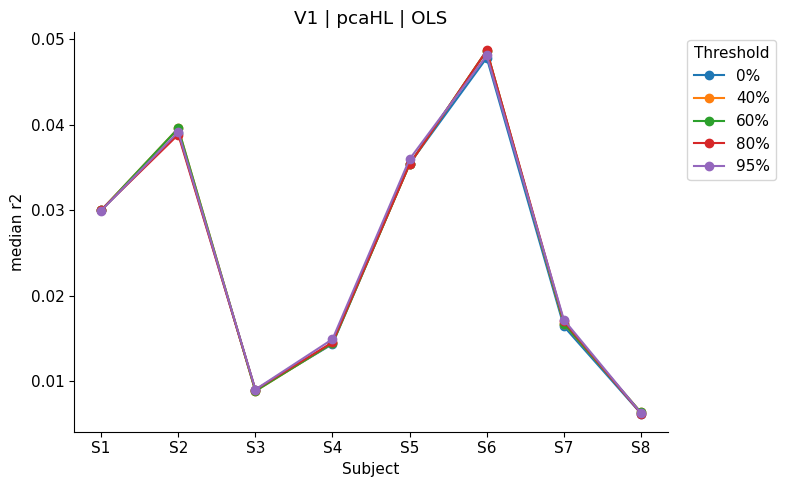

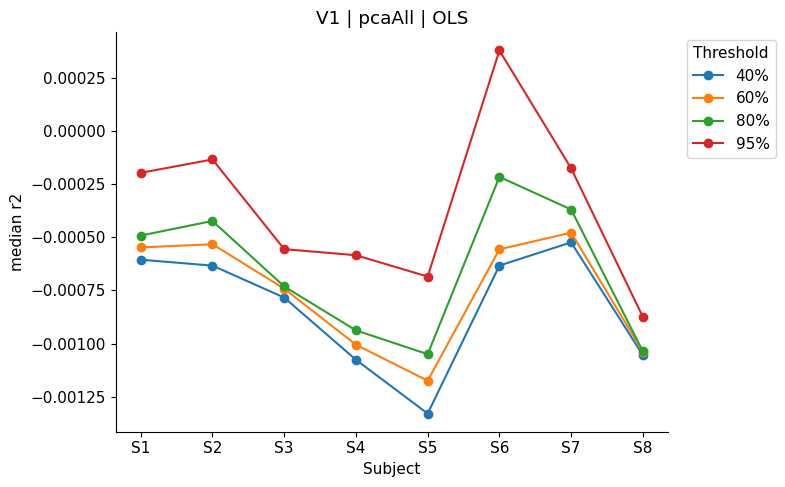

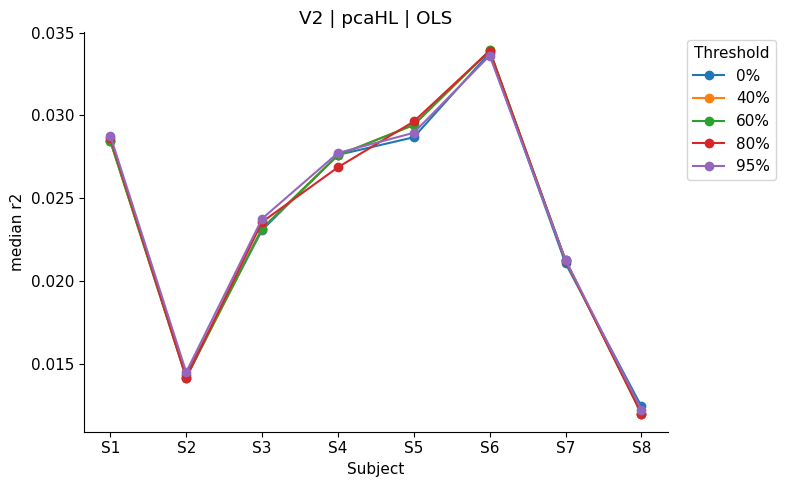

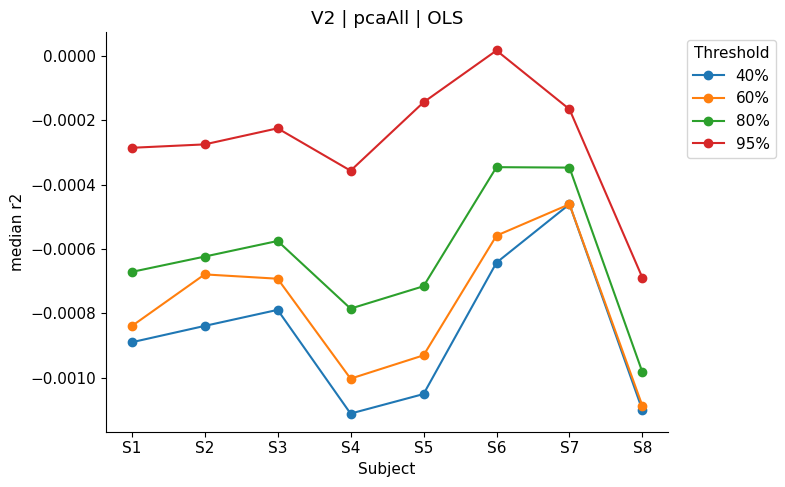

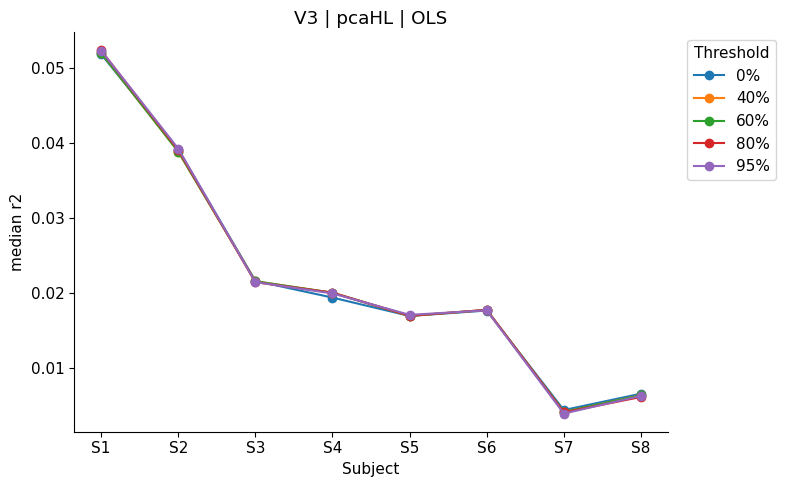

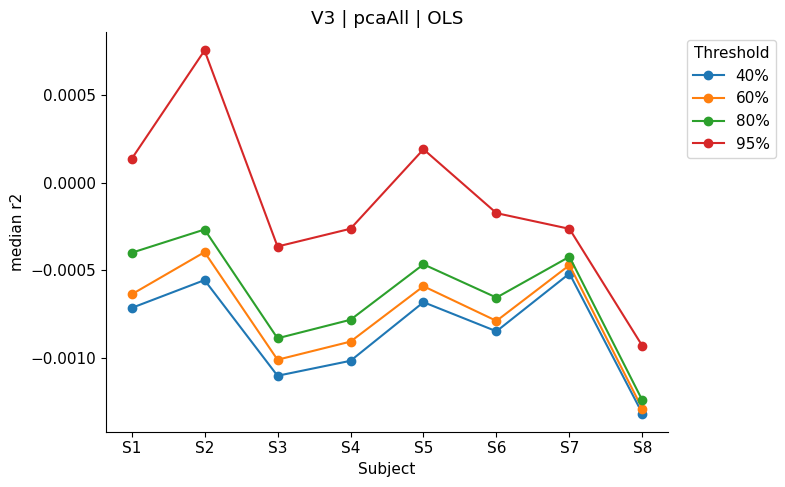

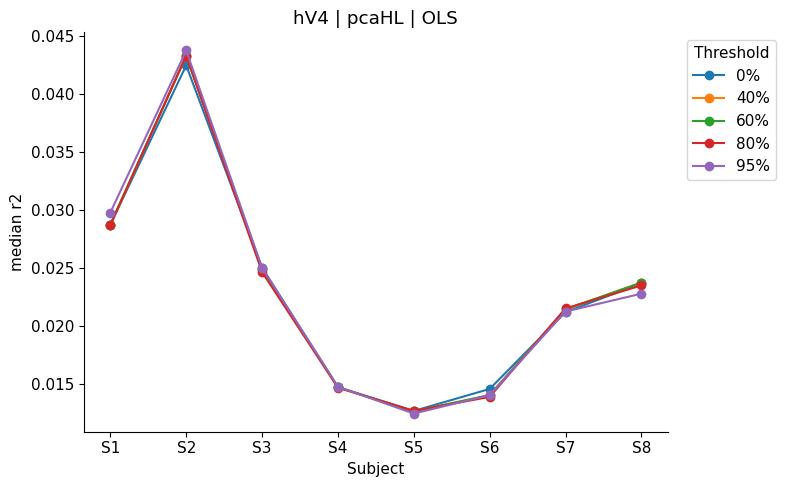

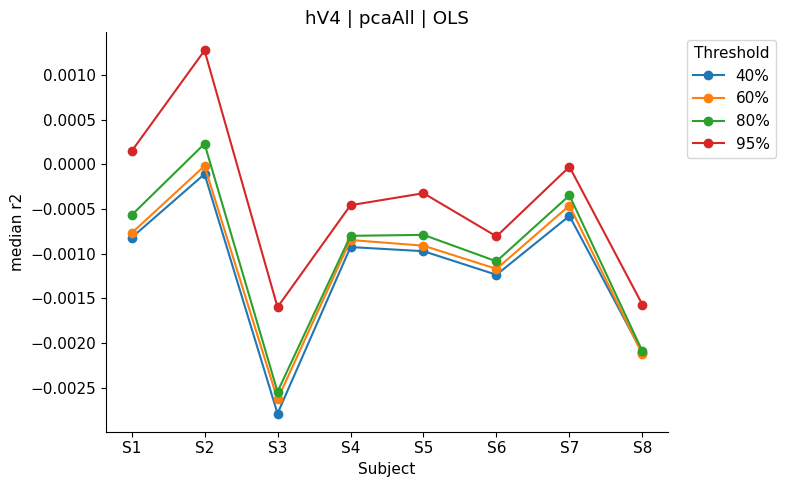

In [88]:
def plot_subject_profiles(
    fit_summary: pd.DataFrame,
    roi: str,
    pca_type: str,
    metric: str = "median_r2",
    ridge: bool = False,
) -> None:
    data = fit_summary[
        (fit_summary["roi"] == roi) &
        (fit_summary["pca_type"] == pca_type) &
        (fit_summary["ridge"] == ridge)
    ].copy()

    table = (
        data.pivot_table(
            index="subject",
            columns="threshold",
            values=metric,
            aggfunc="mean",
        )
        .sort_index()
    )

    if table.empty:
        print("No matching data.")
        return

    fig, ax = plt.subplots(figsize=(8, 5))

    x = np.arange(len(table.index))
    for threshold in table.columns:
        ax.plot(x, table[threshold], marker="o", label=f"{threshold}%")

    ax.set_xticks(x)
    ax.set_xticklabels([f"S{int(s)}" for s in table.index])
    ax.set_xlabel("Subject")
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_title(f"{roi} | {pca_type} | {'Ridge' if ridge else 'OLS'}")
    ax.legend(title="Threshold", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


for roi in ROIS:
    for pca_type in PCA_TYPES:
        plot_subject_profiles(fit_df, roi=roi, pca_type=pca_type)

## 11. Compare cortical regions

The ROI comparison tests whether the preferred PCA configuration is stable across the visual hierarchy. This is important because `pcaHL` preserves the 49 low-level features while compressing only the higher-order statistics, whereas `pcaAll` compresses all texture features together.

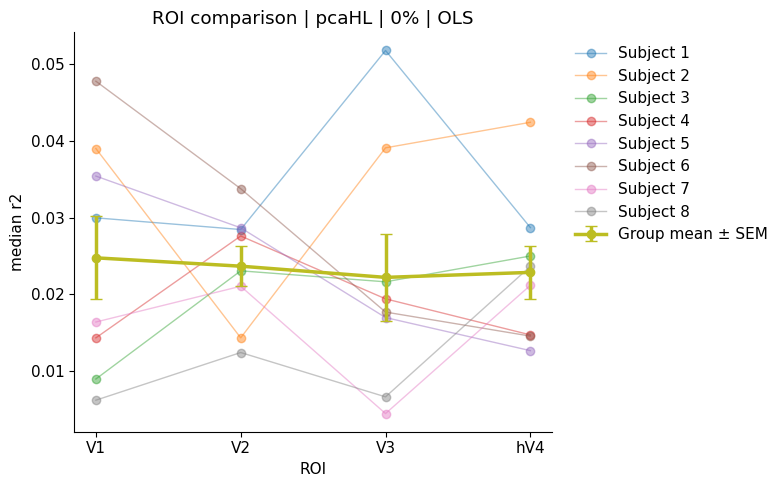

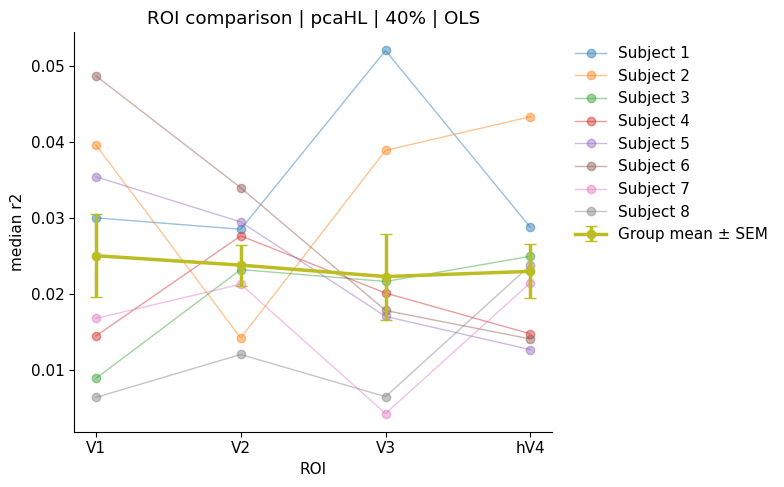

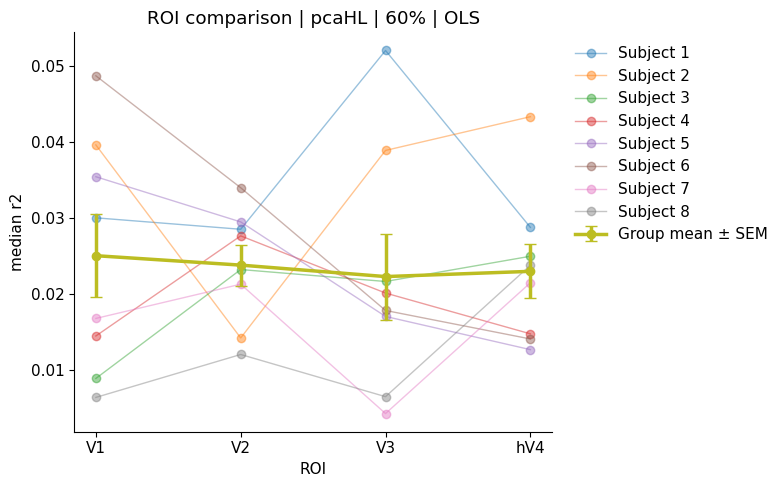

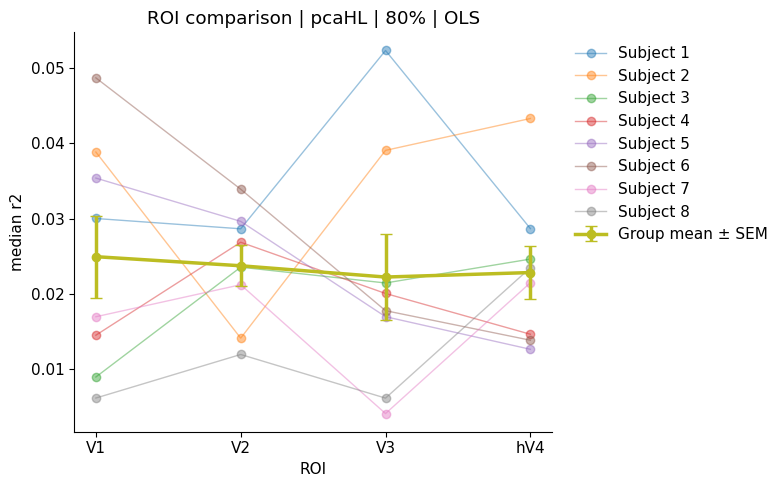

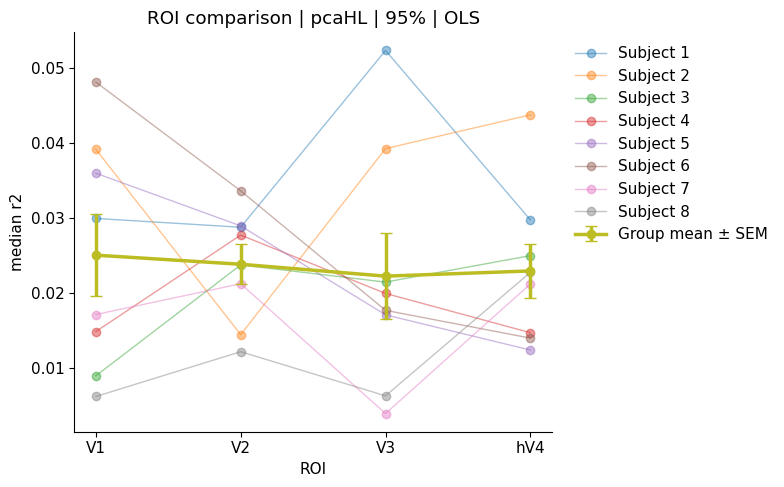

No matching data.


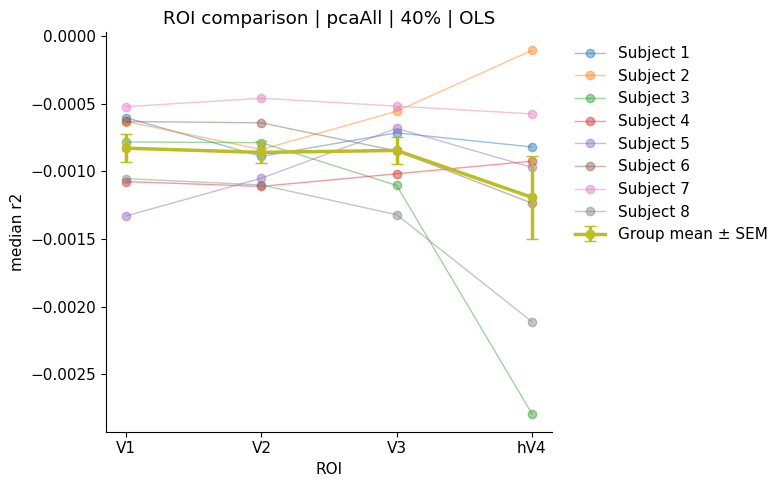

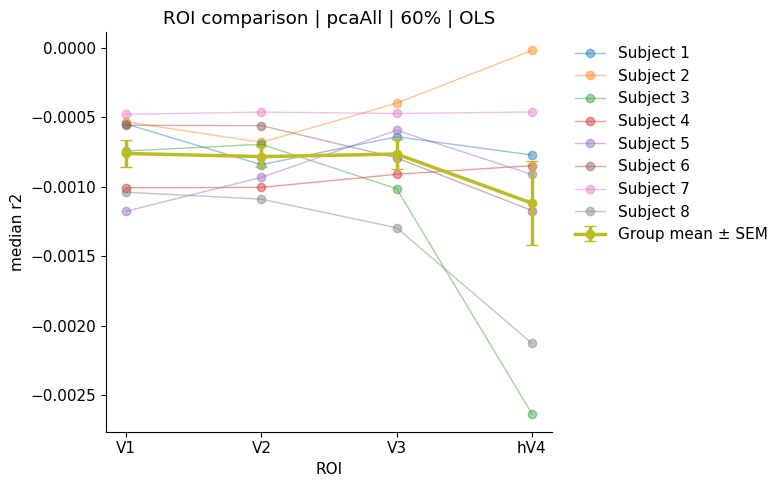

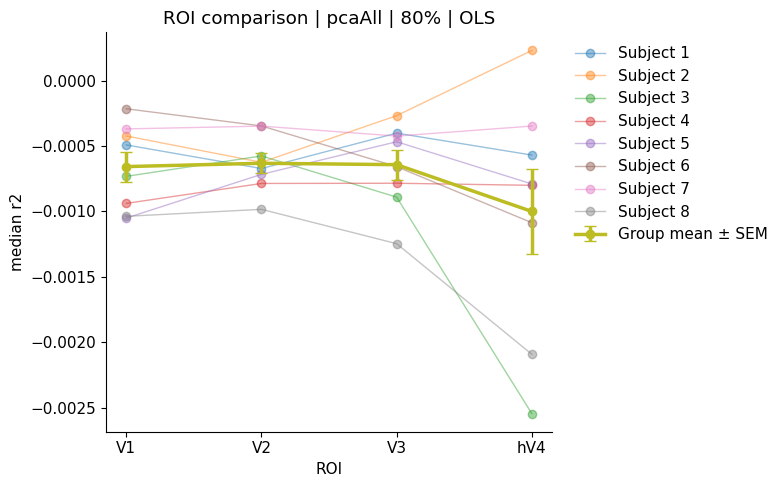

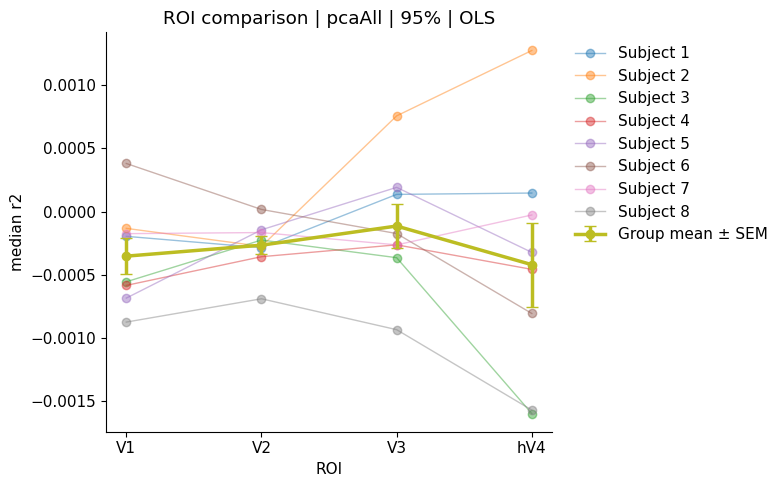

In [90]:
def plot_roi_comparison(
    fit_summary: pd.DataFrame,
    pca_type: str,
    threshold: int,
    metric: str = "median_r2",
    ridge: bool = False,
) -> None:
    data = fit_summary[
        (fit_summary["pca_type"] == pca_type) &
        (fit_summary["threshold"] == threshold) &
        (fit_summary["ridge"] == ridge)
    ].copy()

    subject_roi = (
        data.groupby(["subject", "roi"], as_index=False)[metric]
        .mean()
    )

    if subject_roi.empty:
        print("No matching data.")
        return

    fig, ax = plt.subplots(figsize=(8, 5))
    x_positions = {roi: i for i, roi in enumerate(ROI_ORDER)}

    for subject, sub in subject_roi.groupby("subject"):
        sub = sub.set_index("roi").reindex(ROI_ORDER).reset_index()
        ax.plot(
            [x_positions[r] for r in sub["roi"]],
            sub[metric],
            marker="o",
            alpha=0.45,
            linewidth=1,
            label=f"Subject {subject}",
        )

    group = (
        subject_roi.groupby("roi")[metric]
        .agg(["mean", "sem"])
        .reindex(ROI_ORDER)
    )

    ax.errorbar(
        np.arange(len(ROI_ORDER)),
        group["mean"],
        yerr=group["sem"],
        marker="o",
        linewidth=2.5,
        capsize=4,
        label="Group mean ± SEM",
    )
    ax.set_xticks(np.arange(len(ROI_ORDER)))
    ax.set_xticklabels(ROI_ORDER)
    ax.set_xlabel("ROI")
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_title(
        f"ROI comparison | {pca_type} | {threshold}% | "
        f"{'Ridge' if ridge else 'OLS'}"
    )
    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False,
    )
    plt.tight_layout()
    plt.show()


for pca_type in PCA_TYPES:
    for threshold in THRESHOLDS:
        plot_roi_comparison(
            fit_df,
            pca_type=pca_type,
            threshold=threshold,
            metric="median_r2",
            ridge=False,
        )

# both pca types on same plot

In [91]:
def plot_roi_comparison_both_pca(
    fit_summary: pd.DataFrame,
    threshold: int,
    metric: str = "median_r2",
    ridge: bool = False,
) -> None:

    data = fit_summary[
        (fit_summary["pca_type"].isin(["pcaHL", "pcaAll"])) &
        (fit_summary["threshold"] == threshold) &
        (fit_summary["ridge"] == ridge)
    ].copy()

    subject_roi = (
        data.groupby(
            ["subject", "roi", "pca_type"],
            as_index=False,
        )[metric]
        .mean()
    )

    if subject_roi.empty:
        print(f"No matching data for threshold {threshold}%.")
        return

    available_types = set(subject_roi["pca_type"].unique())

    if not {"pcaHL", "pcaAll"}.issubset(available_types):
        print(
            f"Skipping threshold {threshold}%: "
            f"both PCA types are not available."
        )
        return

    fig, ax = plt.subplots(figsize=(11, 5.5))

    x = np.arange(len(ROI_ORDER))

    # Keep the same color for the same subject across both PCA types
    subjects = sorted(subject_roi["subject"].unique())
    colors = plt.cm.tab10(np.linspace(0, 1, len(subjects)))
    subject_colors = dict(zip(subjects, colors))

    line_styles = {
        "pcaHL": "-",
        "pcaAll": "--",
    }

    # Subject-level curves
    for subject in subjects:
        for pca_type in ["pcaHL", "pcaAll"]:

            sub = subject_roi[
                (subject_roi["subject"] == subject) &
                (subject_roi["pca_type"] == pca_type)
            ]

            sub = (
                sub.set_index("roi")
                .reindex(ROI_ORDER)
                .reset_index()
            )

            ax.plot(
                x,
                sub[metric],
                marker="o",
                linestyle=line_styles[pca_type],
                color=subject_colors[subject],
                alpha=0.45,
                linewidth=1,
                label=(
                    f"Subject {subject}"
                    if pca_type == "pcaHL"
                    else None
                ),
            )

    # Group mean and SEM separately for each PCA type
    for pca_type in ["pcaHL", "pcaAll"]:

        group = (
            subject_roi[
                subject_roi["pca_type"] == pca_type
            ]
            .groupby("roi")[metric]
            .agg(["mean", "sem"])
            .reindex(ROI_ORDER)
        )

        ax.errorbar(
            x,
            group["mean"],
            yerr=group["sem"],
            marker="o",
            linestyle=line_styles[pca_type],
            linewidth=2.5,
            capsize=4,
            label=f"{pca_type} group mean ± SEM",
        )

    ax.set_xticks(x)
    ax.set_xticklabels(ROI_ORDER)
    ax.set_xlabel("ROI")
    ax.set_ylabel(metric.replace("_", " "))

    ax.set_title(
        f"ROI comparison: pcaHL vs pcaAll | "
        f"{threshold}% | {'Ridge' if ridge else 'OLS'}"
    )

    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False,
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

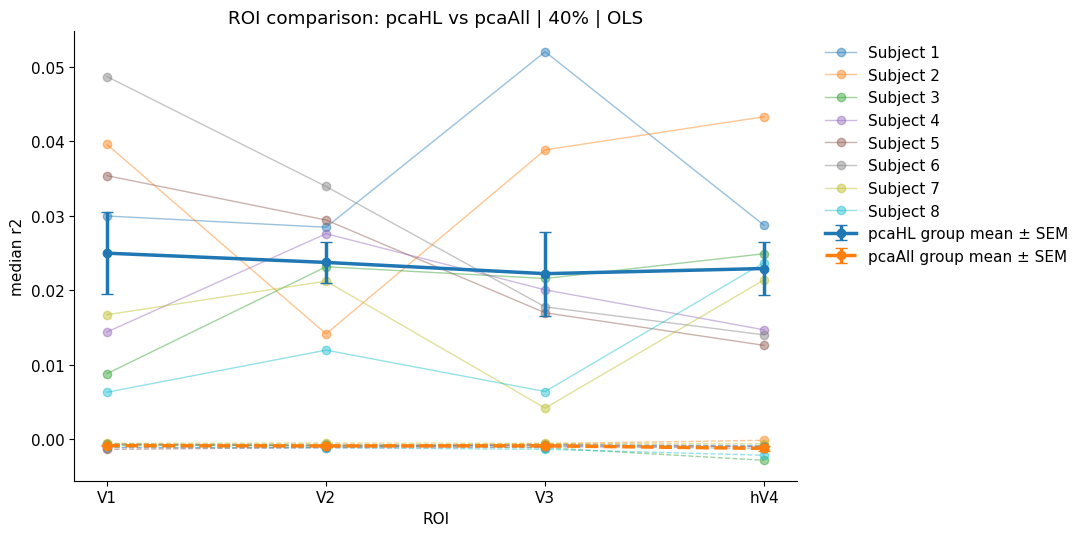

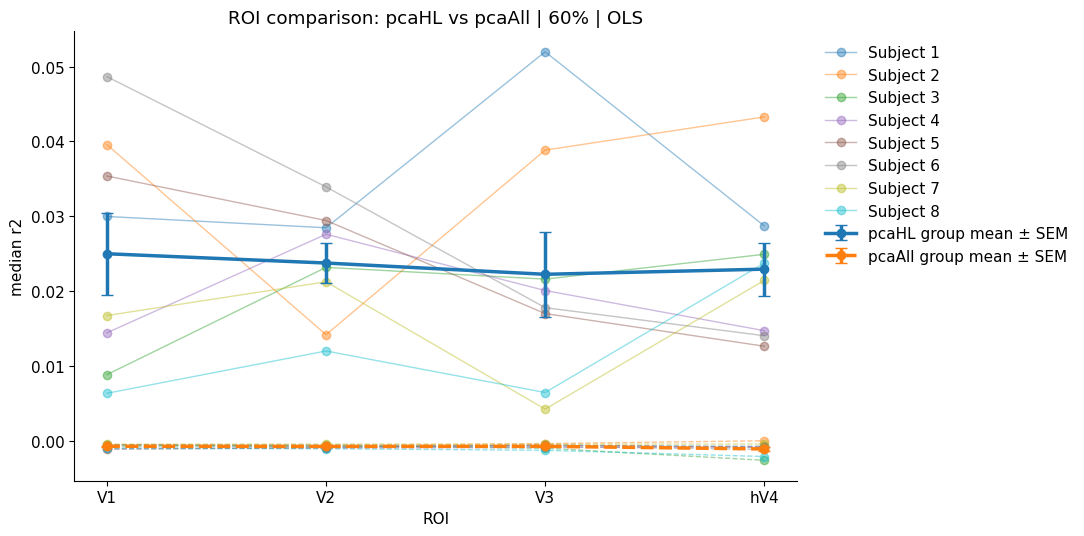

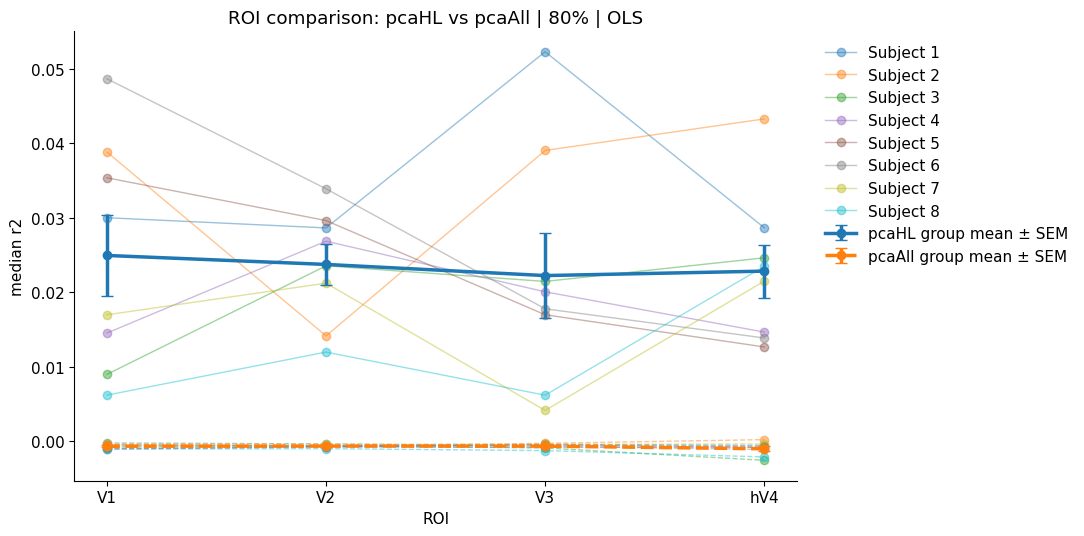

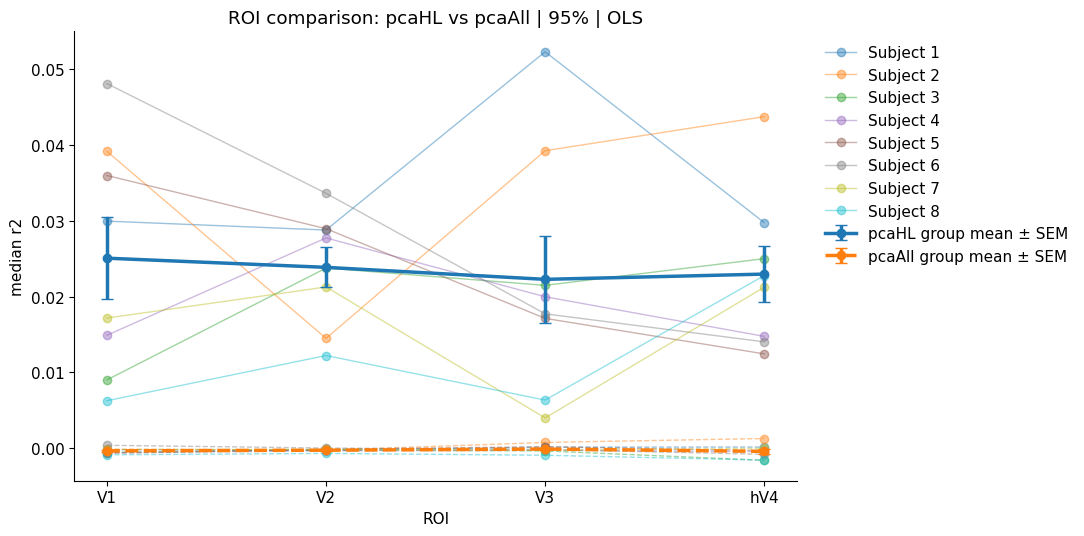

In [92]:
shared_thresholds = sorted(
    set(
        fit_df.loc[
            fit_df["pca_type"] == "pcaHL",
            "threshold",
        ]
    )
    &
    set(
        fit_df.loc[
            fit_df["pca_type"] == "pcaAll",
            "threshold",
        ]
    )
)

for threshold in shared_thresholds:
    plot_roi_comparison_both_pca(
        fit_df,
        threshold=threshold,
        metric="median_r2",
        ridge=False,
    )

## 12. Ridge versus OLS

This section is run only when both ridge and OLS results are available for matched configurations. A positive difference indicates better performance for ridge regression.

In [ ]:
def paired_regression_table(
    fit_summary: pd.DataFrame,
    metric: str = "median_r",
) -> pd.DataFrame:
    paired = (
        fit_summary.pivot_table(
            index=["subject", "roi", "pca_type", "threshold"],
            columns="ridge",
            values=metric,
            aggfunc="mean",
        )
        .reset_index()
    )

    if not {False, True}.issubset(paired.columns):
        return pd.DataFrame()

    paired = paired.dropna(subset=[False, True]).copy()
    paired = paired.rename(columns={False: "OLS", True: "Ridge"})
    paired["Ridge_minus_OLS"] = paired["Ridge"] - paired["OLS"]

    return paired


paired_regression = paired_regression_table(fit_df)

if paired_regression.empty:
    print("Matched ridge and OLS results were not found.")
else:
    display(paired_regression.head())
    display(
        paired_regression.groupby(["roi", "pca_type", "threshold"])
        ["Ridge_minus_OLS"]
        .agg(["count", "mean", "median", "std"])
        .reset_index()
    )

## 13. Paired statistical comparisons

The inferential unit is the subject. Therefore, tests are performed on matched subject-level summaries.

The Wilcoxon signed-rank test is used as the default because there are only eight subjects and normality cannot be assumed reliably. The table includes the uncorrected p-value and a Benjamini–Hochberg false-discovery-rate correction across the tested configurations.

In [ ]:
def benjamini_hochberg(p_values: Iterable[float]) -> np.ndarray:
    """Benjamini-Hochberg FDR correction without external dependencies."""
    p = np.asarray(list(p_values), dtype=float)
    adjusted = np.full_like(p, np.nan)

    finite = np.isfinite(p)
    finite_p = p[finite]

    if finite_p.size == 0:
        return adjusted

    order = np.argsort(finite_p)
    ranked = finite_p[order]
    m = len(ranked)

    corrected = ranked * m / np.arange(1, m + 1)
    corrected = np.minimum.accumulate(corrected[::-1])[::-1]
    corrected = np.clip(corrected, 0, 1)

    original_order = np.empty_like(order)
    original_order[order] = np.arange(m)

    adjusted[finite] = corrected[original_order]
    return adjusted


def test_pca_type_differences(
    paired: pd.DataFrame,
) -> pd.DataFrame:
    rows = []

    if stats is None or paired.empty:
        return pd.DataFrame()

    for (roi, threshold), group in paired.groupby(["roi", "threshold"]):
        differences = group["pcaHL_minus_pcaAll"].dropna().to_numpy()

        if len(differences) < 3 or np.allclose(differences, 0):
            statistic = np.nan
            p_value = np.nan
        else:
            statistic, p_value = stats.wilcoxon(differences)

        rows.append({
            "roi": roi,
            "threshold": threshold,
            "n_subjects": len(differences),
            "mean_difference": np.mean(differences) if len(differences) else np.nan,
            "median_difference": np.median(differences) if len(differences) else np.nan,
            "wilcoxon_statistic": statistic,
            "p_uncorrected": p_value,
        })

    results = pd.DataFrame(rows)

    if len(results):
        results["p_fdr"] = benjamini_hochberg(results["p_uncorrected"])

    return results.sort_values(["roi", "threshold"])


pca_stats = test_pca_type_differences(paired_pca)

if len(pca_stats):
    display(pca_stats)
else:
    print("The paired statistical comparison could not be calculated.")

,roi,threshold,n_subjects,mean_difference,median_difference,wilcoxon_statistic,p_uncorrected,p_fdr
0,V1,40,4,0.1145,0.1351,0.0000,0.1250,0.1333
1,V1,60,8,0.1401,0.1420,0.0000,0.0078,0.0104
2,V1,80,8,0.1366,0.1383,0.0000,0.0078,0.0104
3,V1,95,8,0.1296,0.1326,0.0000,0.0078,0.0104
4,V2,40,4,0.0274,-0.0033,5.0000,1.0000,1.0000
5,V2,60,8,0.1394,0.1466,0.0000,0.0078,0.0104
6,V2,80,8,0.1358,0.1433,0.0000,0.0078,0.0104
7,V2,95,8,0.1261,0.1330,0.0000,0.0078,0.0104
8,V3,40,4,0.1282,0.1511,0.0000,0.1250,0.1333
9,V3,60,8,0.1248,0.1240,0.0000,0.0078,0.0104


## 14. PCA dimensionality analysis

Model accuracy must be interpreted together with model size. The PCA scripts save summary CSV files containing the number of retained components for each pRF and threshold.

The following loader searches for those CSV files and converts their wide threshold columns into a tidy table.

In [93]:
def discover_pca_summary_files(root: Path) -> list[Path]:
    if not root.exists():
        return []

    patterns = [
        "*summary.csv",
        "*PCA*summary*.csv",
    ]

    files = set()
    for pattern in patterns:
        files.update(root.rglob(pattern))

    return sorted(files)


def load_pca_summary_tables(root: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    files = discover_pca_summary_files(root)
    frames = []
    report = []

    for path in files:
        try:
            frame = pd.read_csv(path)
            frame["source_file"] = str(path)

            if "pca_type" not in frame:
                path_text = str(path)
                if re.search(r"pca[_-]?hl", path_text, re.IGNORECASE):
                    frame["pca_type"] = "pcaHL"
                elif re.search(r"pca[_-]?all", path_text, re.IGNORECASE):
                    frame["pca_type"] = "pcaAll"
                else:
                    frame["pca_type"] = None

            if "subject" not in frame:
                match = re.search(r"(?:^|[/_])S0?([1-8])(?:[/_]|$)", str(path))
                frame["subject"] = int(match.group(1)) if match else np.nan

            frames.append(frame)
            report.append({
                "source_file": str(path),
                "status": "loaded",
                "n_rows": len(frame),
                "error": "",
            })

        except Exception as exc:
            report.append({
                "source_file": str(path),
                "status": "failed",
                "n_rows": 0,
                "error": repr(exc),
            })

    if not frames:
        return pd.DataFrame(), pd.DataFrame(report)

    return pd.concat(frames, ignore_index=True), pd.DataFrame(report)


def tidy_component_counts(summary: pd.DataFrame) -> pd.DataFrame:
    """Convert n_components_40, n_components_60, ... to long format."""
    component_columns = [
        column for column in summary.columns
        if re.fullmatch(r"n_components_\d+", column)
    ]

    if not component_columns:
        return pd.DataFrame()

    id_columns = [
        column for column in summary.columns
        if column not in component_columns
    ]

    long = summary.melt(
        id_vars=id_columns,
        value_vars=component_columns,
        var_name="threshold_label",
        value_name="n_components",
    )

    long["threshold"] = (
        long["threshold_label"]
        .str.extract(r"(\d+)", expand=False)
        .astype(int)
    )

    return long


pca_summary_raw, pca_load_report = load_pca_summary_tables(PCA_ROOT)
pca_components = tidy_component_counts(pca_summary_raw)

print("PCA summary files loaded:", (pca_load_report["status"] == "loaded").sum() if len(pca_load_report) else 0)

if len(pca_load_report):
    display(pca_load_report)

if len(pca_components):
    display(pca_components.head())
else:
    print("No compatible PCA summary CSV files were found.")

PCA summary files loaded: 9


,source_file,status,n_rows,error
0,/content/drive/MyDrive/V2_drift/features/pyram...,loaded,1456,
1,/content/drive/MyDrive/V2_drift/features/pyram...,loaded,1456,
2,/content/drive/MyDrive/V2_drift/features/pyram...,loaded,1456,
3,/content/drive/MyDrive/V2_drift/features/pyram...,loaded,1456,
4,/content/drive/MyDrive/V2_drift/features/pyram...,loaded,1456,
5,/content/drive/MyDrive/V2_drift/features/pyram...,loaded,1456,
6,/content/drive/MyDrive/V2_drift/features/pyram...,loaded,1456,
7,/content/drive/MyDrive/V2_drift/features/pyram...,loaded,1456,
8,/content/drive/MyDrive/V2_drift/features/pyram...,loaded,1456,


,subject,image_set,pca_type,pca_block,prf,n_original_features,max_pc_to_retain,n_valid_pcs,pc1_variance_explained,total_saved_variance_explained,source_file,threshold_label,n_components,threshold
0,4,S4,pcaAll,all_features,0,641,641,641,67.5624,100.0000,/content/drive/MyDrive/V2_drift/features/pyram...,n_components_40,1.0000,40
1,4,S4,pcaAll,all_features,1,641,641,641,67.5624,100.0000,/content/drive/MyDrive/V2_drift/features/pyram...,n_components_40,1.0000,40
2,4,S4,pcaAll,all_features,2,641,641,641,67.5624,100.0000,/content/drive/MyDrive/V2_drift/features/pyram...,n_components_40,1.0000,40
3,4,S4,pcaAll,all_features,3,641,641,641,67.5624,100.0000,/content/drive/MyDrive/V2_drift/features/pyram...,n_components_40,1.0000,40
4,4,S4,pcaAll,all_features,4,641,641,641,67.5624,100.0000,/content/drive/MyDrive/V2_drift/features/pyram...,n_components_40,1.0000,40


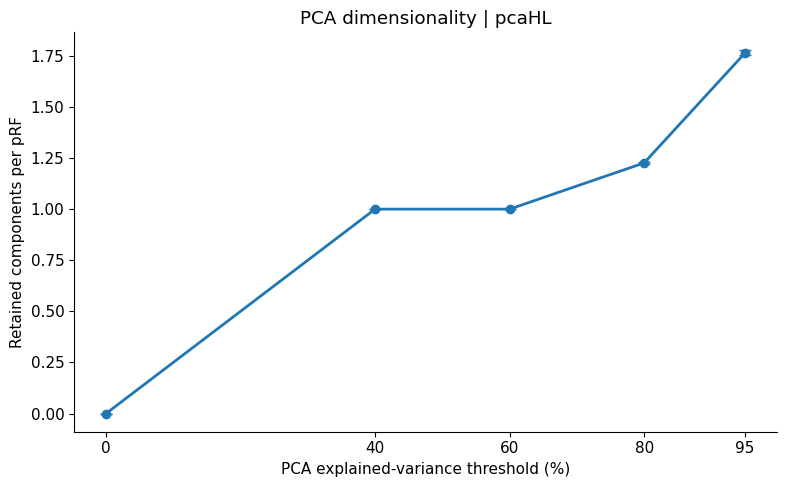

,threshold,mean,median,std,count,sem
0,0,0.0000,0.0000,0.0000,5824,0.0000
1,40,1.0000,1.0000,0.0000,5824,0.0000
2,60,1.0000,1.0000,0.0000,5824,0.0000
3,80,1.2261,1.0000,0.4364,5824,0.0057
4,95,1.7639,1.0000,0.9218,5824,0.0121


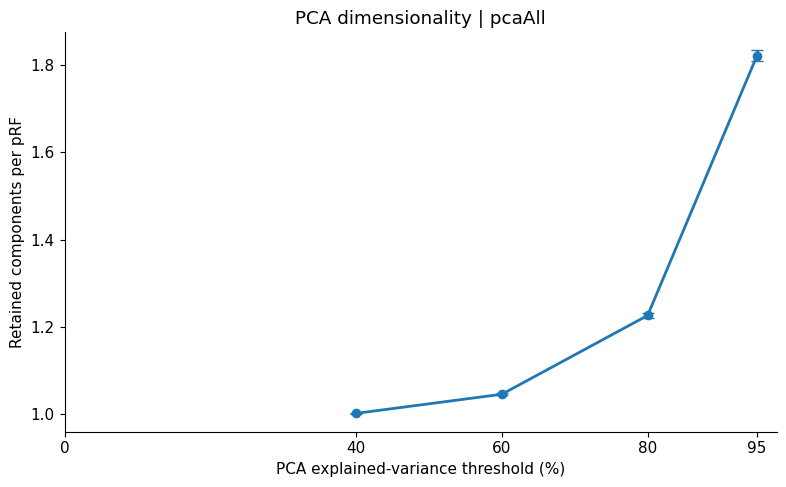

,threshold,mean,median,std,count,sem
0,0,NaN,NaN,NaN,0,NaN
1,40,1.0016,1.0000,0.0406,7280,0.0005
2,60,1.0455,1.0000,0.2083,7280,0.0024
3,80,1.2261,1.0000,0.4644,7280,0.0054
4,95,1.8214,1.0000,1.0309,7280,0.0121


In [94]:
def plot_component_counts(
    component_data: pd.DataFrame,
    pca_type: str | None = None,
) -> None:
    data = component_data.copy()

    if pca_type is not None and "pca_type" in data:
        data = data[data["pca_type"] == pca_type]

    if data.empty:
        print("No component-count data.")
        return

    summary = (
        data.groupby("threshold")["n_components"]
        .agg(["mean", "median", "std", "count"])
        .reset_index()
        .sort_values("threshold")
    )
    summary["sem"] = summary["std"] / np.sqrt(summary["count"])

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.errorbar(
        summary["threshold"],
        summary["mean"],
        yerr=summary["sem"],
        marker="o",
        capsize=4,
        linewidth=2,
    )
    ax.set_xlabel("PCA explained-variance threshold (%)")
    ax.set_ylabel("Retained components per pRF")
    ax.set_title(
        "PCA dimensionality"
        + (f" | {pca_type}" if pca_type is not None else "")
    )
    ax.set_xticks(summary["threshold"])
    plt.tight_layout()
    plt.show()

    display(summary)


if len(pca_components):
    for pca_type in PCA_TYPES:
        plot_component_counts(pca_components, pca_type=pca_type)

## 15. Performance–complexity trade-off

The preferred configuration should combine strong prediction performance with a compact feature representation.

This section merges model performance with the mean number of retained PCA components. For `pcaHL`, remember that the final model also includes the 49 uncompressed low-level features. Therefore, the total dimensionality is calculated as:

- `pcaHL`: 49 low-level features + retained high-level PCs;
- `pcaAll`: retained PCs only.

,pca_type,threshold,mean_subject_performance,sem_subject_performance,n_subject_roi_fits,mean_retained_pcs,estimated_total_features
0,pcaAll,40,0.0304,0.0012,32,1.0016,1.0016
1,pcaAll,60,0.0322,0.0012,32,1.0455,1.0455
2,pcaAll,80,0.0365,0.0014,32,1.2261,1.2261
3,pcaAll,95,0.0461,0.0018,32,1.8214,1.8214
4,pcaHL,0,0.1660,0.0066,32,0.0000,49.0000
5,pcaHL,40,0.1663,0.0066,32,1.0000,50.0000
6,pcaHL,60,0.1663,0.0066,32,1.0000,50.0000
7,pcaHL,80,0.1665,0.0066,32,1.2261,50.2261
8,pcaHL,95,0.1665,0.0066,32,1.7639,50.7639


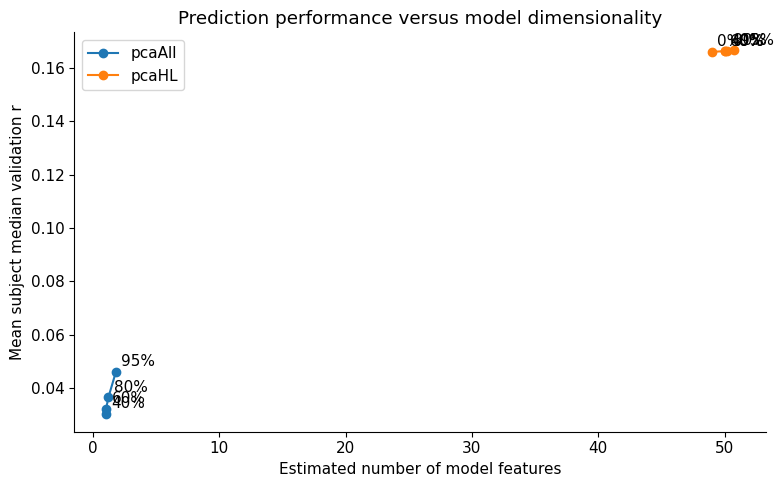

In [95]:
def build_performance_complexity_table(
    fit_summary: pd.DataFrame,
    component_data: pd.DataFrame,
    metric: str = "median_r2",
    ridge: bool = False,
) -> pd.DataFrame:
    performance = (
        fit_summary[fit_summary["ridge"] == ridge]
        .groupby(["pca_type", "threshold"])[metric]
        .agg(["mean", "sem", "count"])
        .reset_index()
        .rename(columns={
            "mean": "mean_subject_performance",
            "sem": "sem_subject_performance",
            "count": "n_subject_roi_fits",
        })
    )

    components = (
        component_data.groupby(["pca_type", "threshold"])["n_components"]
        .mean()
        .rename("mean_retained_pcs")
        .reset_index()
    )

    merged = performance.merge(
        components,
        on=["pca_type", "threshold"],
        how="left",
    )

    merged["estimated_total_features"] = np.where(
        merged["pca_type"] == "pcaHL",
        49 + merged["mean_retained_pcs"],
        merged["mean_retained_pcs"],
    )

    return merged


if len(pca_components):
    tradeoff_df = build_performance_complexity_table(
        fit_df,
        pca_components,
        metric="median_r",
        ridge=False,
    )

    display(tradeoff_df)

    fig, ax = plt.subplots(figsize=(8, 5))

    for pca_type, sub in tradeoff_df.groupby("pca_type"):
        ax.plot(
            sub["estimated_total_features"],
            sub["mean_subject_performance"],
            marker="o",
            label=pca_type,
        )

        for _, row in sub.iterrows():
            ax.annotate(
                f"{int(row['threshold'])}%",
                (
                    row["estimated_total_features"],
                    row["mean_subject_performance"],
                ),
                xytext=(4, 4),
                textcoords="offset points",
            )

    ax.set_xlabel("Estimated number of model features")
    ax.set_ylabel("Mean subject median validation r")
    ax.set_title("Prediction performance versus model dimensionality")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    tradeoff_df = pd.DataFrame()
    print("Component-count summaries are required for this comparison.")

## 16. Rank candidate configurations

The ranking below is descriptive rather than automatic proof of the best model. It first averages performance across ROIs within each subject, and then summarizes across subjects.

This gives each subject equal influence and prevents an ROI with more voxels from dominating the decision.

In [96]:
def rank_configurations(
    fit_summary: pd.DataFrame,
    metric: str = "median_r2",
    ridge: bool | None = None,
) -> pd.DataFrame:
    data = fit_summary.copy()

    if ridge is not None:
        data = data[data["ridge"] == ridge]

    subject_configuration = (
        data.groupby(
            ["subject", "pca_type", "threshold", "ridge"],
            as_index=False,
        )[metric]
        .mean()
    )

    ranking = (
        subject_configuration.groupby(
            ["pca_type", "threshold", "ridge"],
            as_index=False,
        )[metric]
        .agg(["count", "mean", "median", "std", "sem"])
        .reset_index()
        .rename(columns={
            "count": "n_subjects",
            "mean": "mean_across_subjects",
            "median": "median_across_subjects",
            "std": "std_across_subjects",
            "sem": "sem_across_subjects",
        })
        .sort_values(
            ["mean_across_subjects", "median_across_subjects"],
            ascending=False,
        )
        .reset_index(drop=True)
    )

    ranking["rank"] = np.arange(1, len(ranking) + 1)
    return ranking


ranking_df = rank_configurations(
    fit_df,
    metric="median_r2",
    ridge=None,
)

display(ranking_df)

,index,pca_type,threshold,ridge,n_subjects,mean_across_subjects,median_across_subjects,std_across_subjects,sem_across_subjects,rank
0,8,pcaHL,95,False,8,0.0235,0.0217,0.0084,0.0030,1
1,5,pcaHL,40,False,8,0.0235,0.0216,0.0083,0.0029,2
2,6,pcaHL,60,False,8,0.0235,0.0216,0.0083,0.0029,3
3,7,pcaHL,80,False,8,0.0235,0.0217,0.0083,0.0029,4
4,4,pcaHL,0,False,8,0.0234,0.0216,0.0083,0.0029,5
5,3,pcaAll,95,False,8,-0.0003,-0.0002,0.0004,0.0002,6
6,2,pcaAll,80,False,8,-0.0007,-0.0007,0.0004,0.0001,7
7,1,pcaAll,60,False,8,-0.0009,-0.0008,0.0003,0.0001,8
8,0,pcaAll,40,False,8,-0.0009,-0.0009,0.0003,0.0001,9


## 17. Recommended selection rule

The final PCA choice should satisfy all of the following:

1. **Prediction accuracy:** high validation Pearson correlation and validation R².
2. **Consistency:** the advantage should appear across subjects and should not depend on one participant.
3. **Regional stability:** the configuration should perform adequately in V1, V2, V3, and hV4.
4. **Parsimony:** when two configurations perform similarly, prefer the one with fewer retained features.
5. **Analysis compatibility:** the selected configuration must be available for every subject and ROI required for the later representational-drift analysis.

The cell below prints a preliminary recommendation based on mean subject-level validation correlation. This recommendation should still be checked against the paired plots, statistical results, dimensionality, and coverage table.

In [97]:
def preliminary_recommendation(ranking: pd.DataFrame) -> dict[str, Any]:
    if ranking.empty:
        return {"status": "No complete configurations were available."}

    best = ranking.iloc[0]

    return {
        "pca_type": best["pca_type"],
        "threshold": int(best["threshold"]),
        "regression": "Ridge" if bool(best["ridge"]) else "OLS",
        "n_subjects": int(best["n_subjects"]),
        "mean_subject_median_r": float(best["mean_across_subjects"]),
        "median_subject_median_r": float(best["median_across_subjects"]),
        "note": (
            "This is a performance-only preliminary ranking. "
            "Confirm coverage, paired differences, and feature dimensionality "
            "before fixing the final configuration."
        ),
    }


recommendation = preliminary_recommendation(ranking_df)
print(json.dumps(recommendation, indent=2))

{
  "pca_type": "pcaHL",
  "threshold": 95,
  "regression": "OLS",
  "n_subjects": 8,
  "mean_subject_median_r": 0.02353666718408931,
  "median_subject_median_r": 0.021716717281378806,
  "note": "This is a performance-only preliminary ranking. Confirm coverage, paired differences, and feature dimensionality before fixing the final configuration."
}


## 18. Save analysis outputs

The tidy voxel table is large, so it is saved separately from the smaller summary tables. CSV files are easy to inspect, while Parquet is more efficient for reloading the full voxel-level dataset.

In [ ]:
# Smaller summary outputs
load_report.to_csv(OUTPUT_DIR / "fit_loading_report.csv", index=False)
coverage.to_csv(OUTPUT_DIR / "configuration_coverage.csv", index=False)
fit_df.to_csv(OUTPUT_DIR / "fit_level_summary.csv", index=False)
config_df.to_csv(OUTPUT_DIR / "configuration_summary.csv", index=False)
ranking_df.to_csv(OUTPUT_DIR / "configuration_ranking.csv", index=False)

if len(paired_pca):
    paired_pca.to_csv(OUTPUT_DIR / "paired_pca_type_comparisons.csv", index=False)

if len(pca_stats):
    pca_stats.to_csv(OUTPUT_DIR / "paired_pca_type_statistics.csv", index=False)

if len(pca_summary_raw):
    pca_summary_raw.to_csv(OUTPUT_DIR / "pca_summary_combined.csv", index=False)

if len(pca_components):
    pca_components.to_csv(OUTPUT_DIR / "pca_component_counts_long.csv", index=False)

if len(tradeoff_df):
    tradeoff_df.to_csv(OUTPUT_DIR / "performance_complexity_tradeoff.csv", index=False)

# Prefer Parquet for the large voxel table; fall back to compressed CSV.
try:
    voxel_df.to_parquet(
        OUTPUT_DIR / "voxel_level_results.parquet",
        index=False,
    )
    voxel_output = OUTPUT_DIR / "voxel_level_results.parquet"
except Exception:
    voxel_df.to_csv(
        OUTPUT_DIR / "voxel_level_results.csv.gz",
        index=False,
        compression="gzip",
    )
    voxel_output = OUTPUT_DIR / "voxel_level_results.csv.gz"

with open(OUTPUT_DIR / "preliminary_recommendation.json", "w") as file:
    json.dump(recommendation, file, indent=2)

print("Saved analysis outputs to:", OUTPUT_DIR)
print("Voxel-level output:", voxel_output)

### Distribution of voxel-level validation performance

This histogram compares the distribution of validation \(R^2\) values across voxels for `pcaAll` and `pcaHL`.

The comparison is shown for one subject, one ROI, and one explained-variance threshold at a time.

Each histogram contains the voxel-level validation \(R^2\) values for one PCA strategy. The vertical line at zero separates voxels with positive out-of-sample prediction performance from voxels for which the model performs worse than predicting the validation-set mean.

Only values within the displayed x-axis range are plotted. Voxels outside this range are hidden from the histogram but are not necessarily absent from the original voxel-level dataframe.

This figure shows whether differences between the PCA strategies reflect:

- a broad shift in performance across many voxels,
- changes limited to the upper-performing voxels,
- or differences caused mainly by extreme negative values.

In [98]:
def plot_r2_distribution_comparison(
    voxel_data: pd.DataFrame,
    subject: int,
    roi: str,
    threshold: int,
    metric: str = "val_r2",
    pca_types: tuple[str, ...] = ("pcaAll", "pcaHL"),
    bins: int = 80,
    xlim: tuple[float, float] = (-1.0, 0.6),
) -> None:

    data = voxel_data[
        (voxel_data["subject"] == subject)
        & (voxel_data["roi"] == roi)
        & (voxel_data["threshold"] == threshold)
        & (voxel_data["pca_type"].isin(pca_types))
    ].copy()

    if data.empty:
        print("No matching voxel-level data.")
        return

    fig, ax = plt.subplots(figsize=(10, 5))

    for pca_type in pca_types:

        values_all = (
            data.loc[data["pca_type"] == pca_type, metric]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
            .to_numpy()
        )

        values_plot = values_all[
            (values_all >= xlim[0])
            & (values_all <= xlim[1])
        ]

        ax.hist(
            values_plot,
            bins=bins,
            range=xlim,
            alpha=0.45,
            label=f"{roi} – {pca_type}",
        )

    ax.axvline(0, linewidth=1)
    ax.set_xlim(*xlim)
    ax.set_xlabel(METRIC_LABELS.get(metric, metric))
    ax.set_ylabel("Number of voxels")
    ax.set_title(
        f"S{subject:02d} {METRIC_LABELS.get(metric, metric)} | "
        f"{roi}, PCA {threshold}%"
    )
    ax.legend()

    plt.tight_layout()
    plt.show()

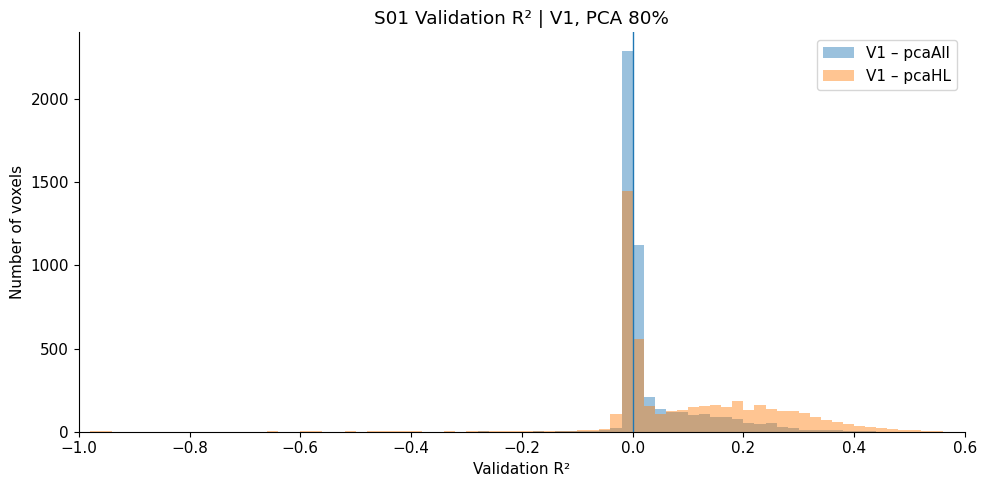

In [ ]:
plot_r2_distribution_comparison(
    voxel_df,
    subject=1,
    roi="V1",
    threshold=80,
)

### PCA configuration performance across visual regions

This figure compares the two PCA strategies separately within V1, V2, V3, and hV4.

For each subject, repeated results are first averaged within each ROI, PCA strategy, and explained-variance threshold. The plotted value is then calculated across subjects.

Each point represents the mean subject-level performance for one PCA configuration. Error bars show the standard error of the mean across subjects.

The x-axis indicates the percentage of PCA variance retained. The lines compare:

- `pcaAll`: PCA applied to all texture-model features together.
- `pcaHL`: low-level features retained without PCA and PCA applied only to high-level features.

This plot tests whether the preferred PCA strategy and variance threshold are consistent across the visual hierarchy or whether model compression has different effects in different cortical regions.

In [99]:
def plot_pca_configuration_by_roi(
    fit_summary: pd.DataFrame,
    metric: str = "median_r2",
    ridge: bool = False,
    nc_filter: str | None = None,
) -> None:

    data = fit_summary.copy()

    data = data[data["ridge"] == ridge]

    if nc_filter is not None and "NC_filter" in data.columns:
        data = data[data["NC_filter"] == nc_filter]

    if data.empty:
        print("No matching fit-level data.")
        return

    # One value per subject × ROI × PCA configuration
    subject_summary = (
        data.groupby(
            ["subject", "roi", "pca_type", "threshold"],
            as_index=False,
        )[metric]
        .mean()
    )

    group_summary = (
        subject_summary.groupby(
            ["roi", "pca_type", "threshold"],
            as_index=False,
        )[metric]
        .agg(
            mean="mean",
            sem="sem",
        )
    )

    fig, axes = plt.subplots(
        1,
        len(ROI_ORDER),
        figsize=(16, 4.5),
        sharey=True,
    )

    for ax, roi in zip(axes, ROI_ORDER):

        roi_data = group_summary[
            group_summary["roi"] == roi
        ]

        for pca_type in PCA_ORDER:

            sub = (
                roi_data[roi_data["pca_type"] == pca_type]
                .sort_values("threshold")
            )

            if sub.empty:
                continue

            ax.errorbar(
                sub["threshold"],
                sub["mean"],
                yerr=sub["sem"],
                marker="o",
                linewidth=2,
                capsize=3,
                label=pca_type,
            )

        ax.axhline(0, linestyle="--", linewidth=1)
        ax.set_title(roi, fontweight="bold")
        ax.set_xlabel("PCA variance threshold (%)")
        ax.set_xticks(
            sorted(roi_data["threshold"].dropna().unique())
        )

    axes[0].set_ylabel(
        METRIC_LABELS.get(
            metric.replace("median_", "val_"),
            metric.replace("_", " "),
        )
    )

    axes[-1].legend(title="PCA type")

    title = "Median model fit across PCA configurations"
    if nc_filter is not None:
        title += f" | {nc_filter}"

    fig.suptitle(title, fontweight="bold", y=1.03)

    plt.tight_layout()
    plt.show()

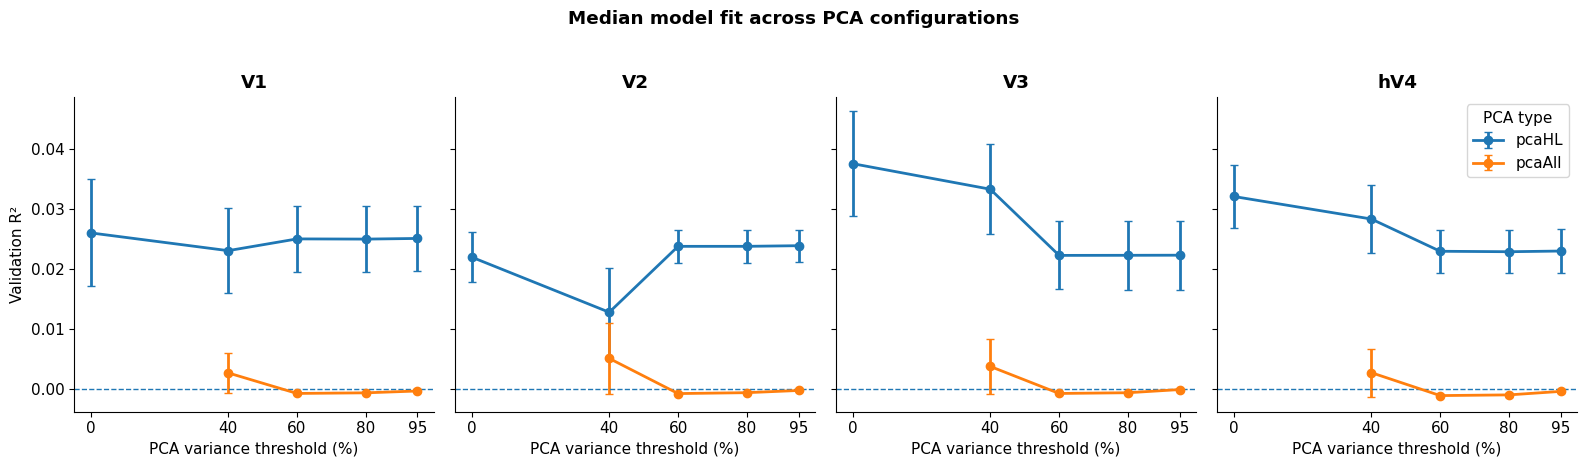

In [ ]:
plot_pca_configuration_by_roi(
    fit_df,
    metric="median_r2",
    ridge=False,
)

### Overall ranking of PCA configurations

This analysis compares the overall performance of the tested PCA configurations across subjects and visual regions.

Each configuration is defined by:

- PCA strategy: `pcaAll` or `pcaHL`
- Explained-variance threshold used to retain principal components

To avoid giving disproportionate weight to subjects or regions with more saved rows, repeated results are first averaged within each subject, ROI, and PCA configuration.

The bar height represents the mean selected performance metric across the resulting subject-by-ROI values. Error bars show the standard error of the mean.

Configurations are ordered from the highest to the lowest average performance. This plot provides a global summary of model performance, but it does not show whether the preferred configuration differs between visual regions.

In [100]:
def plot_overall_pca_ranking(
    fit_summary: pd.DataFrame,
    metric: str = "median_r2",
    ridge: bool = False,
    nc_filter: str | None = None,
) -> pd.DataFrame:

    data = fit_summary.copy()
    data = data[data["ridge"] == ridge]

    if nc_filter is not None and "NC_filter" in data.columns:
        data = data[data["NC_filter"] == nc_filter]

    # Average repeated rows within subject × ROI first
    subject_roi = (
        data.groupby(
            [
                "subject",
                "roi",
                "pca_type",
                "threshold",
            ],
            as_index=False,
        )[metric]
        .mean()
    )

    ranking = (
        subject_roi.groupby(
            ["pca_type", "threshold"],
            as_index=False,
        )[metric]
        .agg(
            mean="mean",
            sem="sem",
            n_values="count",
        )
    )

    ranking["configuration"] = (
        ranking["pca_type"]
        + "_"
        + ranking["threshold"].astype(int).astype(str)
    )

    ranking = ranking.sort_values(
        "mean",
        ascending=False,
    ).reset_index(drop=True)

    fig, ax = plt.subplots(
        figsize=(max(9, len(ranking) * 0.65), 5)
    )

    x = np.arange(len(ranking))

    ax.bar(
        x,
        ranking["mean"],
        yerr=ranking["sem"],
        capsize=4,
    )

    ax.axhline(0, linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(
        ranking["configuration"],
        rotation=45,
        ha="right",
    )
    ax.set_ylabel(f"Mean {metric.replace('_', ' ')}")
    ax.set_title(
        "Overall ranking of PCA configurations",
        fontweight="bold",
    )

    plt.tight_layout()
    plt.show()

    return ranking

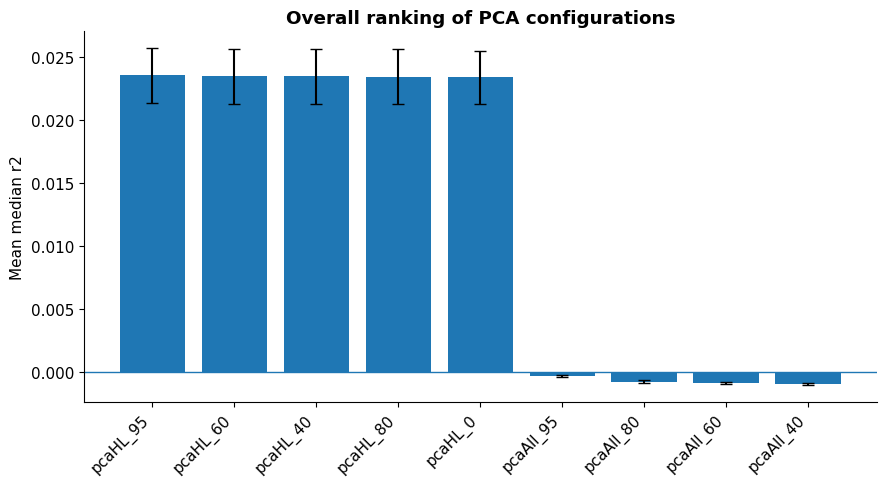

,pca_type,threshold,mean,sem,n_values,configuration
0,pcaHL,95,0.0235,0.0022,32,pcaHL_95
1,pcaHL,60,0.0235,0.0022,32,pcaHL_60
2,pcaHL,40,0.0235,0.0022,32,pcaHL_40
3,pcaHL,80,0.0235,0.0022,32,pcaHL_80
4,pcaHL,0,0.0234,0.0021,32,pcaHL_0
5,pcaAll,95,-0.0003,0.0001,32,pcaAll_95
6,pcaAll,80,-0.0007,0.0001,32,pcaAll_80
7,pcaAll,60,-0.0009,0.0001,32,pcaAll_60
8,pcaAll,40,-0.0009,0.0001,32,pcaAll_40


In [101]:
ranking_df = plot_overall_pca_ranking(
    fit_df,
    metric="median_r2",
    ridge=False,
)

display(ranking_df)

In [104]:
voxel_df_with_prf = add_prf_r2_to_voxel_table(
    voxel_df,
    PRF_ROOT,
)

### Encoding-model performance as a function of pRF model fit

This figure examines the relationship between pRF model quality and validation performance for the two PCA strategies.

Each voxel is represented by two validation $R^2$ values:

- `pcaAll`: PCA is applied jointly to all texture-model features.
- `pcaHL`: Low-level features are retained in their original form, while PCA is applied only to the high-level feature set.

The x-axis shows the NSD pRF $R^2$, which measures how well the voxel's spatial receptive field is estimated. The y-axis shows the validation $R^2$ of the texture encoding model.

Only voxels with valid pRF $R^2$ values and valid results for both PCA strategies are included. Voxels with validation $R^2$ below the selected minimum threshold are excluded.

The figure title reports the median difference between the strategies:

$$
\Delta R^2 = R^2_{\mathrm{pcaHL}} - R^2_{\mathrm{pcaAll}}
$$

The reported Spearman correlation is calculated between pRF $R^2$ and $\Delta R^2$. It therefore tests whether pRF model quality is related to the relative advantage of `pcaHL` over `pcaAll`.

In [105]:
def plot_validation_r2_vs_prf_r2(
    voxel_data: pd.DataFrame,
    subject: int,
    roi: str,
    threshold: int,
    prf_metric: str = "prf_r2",
    validation_metric: str = "val_r2",
    min_validation_r2: float = -1.0,
    xlim: tuple[float, float] = (0, 1),
    ylim: tuple[float, float] = (-1, 0.65),
) -> None:

    required = {
        "subject",
        "roi",
        "threshold",
        "pca_type",
        "voxel_index",
        prf_metric,
        validation_metric,
    }

    missing = required.difference(voxel_data.columns)

    if missing:
        print("Missing columns:", sorted(missing))
        return

    data = voxel_data[
        (voxel_data["subject"] == subject)
        & (voxel_data["roi"] == roi)
        & (voxel_data["threshold"] == threshold)
        & (voxel_data["pca_type"].isin(["pcaAll", "pcaHL"]))
    ].copy()

    data = data.replace([np.inf, -np.inf], np.nan)

    data = data.dropna(
        subset=[
            "voxel_index",
            prf_metric,
            validation_metric,
        ]
    )

    if data.empty:
        print("No matching data.")
        return

    # One validation R² value per voxel and PCA strategy
    paired = data.pivot_table(
        index="voxel_index",
        columns="pca_type",
        values=validation_metric,
        aggfunc="mean",
    )

    # pRF R² should be identical across PCA strategies
    prf_by_voxel = (
        data.groupby("voxel_index")[prf_metric]
        .first()
    )

    paired = paired.join(
        prf_by_voxel.rename(prf_metric)
    )

    paired = paired.dropna(
        subset=["pcaAll", "pcaHL", prf_metric]
    )

    # Match the filtering used in the earlier analysis
    paired = paired[
        (paired["pcaAll"] > min_validation_r2)
        & (paired["pcaHL"] > min_validation_r2)
        & (paired[prf_metric] >= xlim[0])
        & (paired[prf_metric] <= xlim[1])
    ].copy()

    if paired.empty:
        print("No valid paired voxels after filtering.")
        return

    paired["delta_r2"] = (
        paired["pcaHL"] - paired["pcaAll"]
    )

    if stats is not None:
        rho, p_value = stats.spearmanr(
            paired[prf_metric],
            paired["delta_r2"],
            nan_policy="omit",
        )
    else:
        rho, p_value = np.nan, np.nan

    median_delta = paired["delta_r2"].median()

    fig, ax = plt.subplots(figsize=(8, 6))

    for pca_type in ["pcaAll", "pcaHL"]:
        ax.scatter(
            paired[prf_metric],
            paired[pca_type],
            s=10,
            alpha=0.35,
            label=pca_type,
        )

    ax.axhline(0, linewidth=1)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    ax.set_xlabel("pRF R²")
    ax.set_ylabel("Validation encoding R²")

    if not np.isfinite(p_value):
        p_text = "NA"
    elif p_value < 0.001:
        p_text = "< 0.001"
    else:
        p_text = f"= {p_value:.3f}"

    ax.set_title(
        f"S{subject:02d} {roi} | PCA {threshold}%\n"
        f"median ΔR² = {median_delta:.4f}, "
        f"rho = {rho:.3f}, p {p_text}, "
        f"n = {len(paired):,}"
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

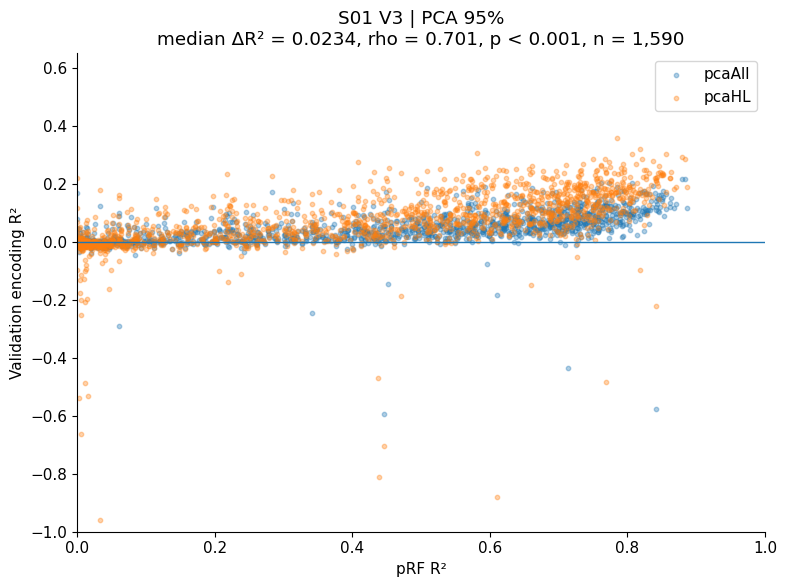

In [106]:
plot_validation_r2_vs_prf_r2(
    voxel_df_with_prf,
    subject=1,
    roi="V3",
    threshold=95,
)

### Difference between PCA strategies as a function of pRF model fit

This analysis tests whether the relative advantage of the two PCA strategies depends on the quality of the voxel's population receptive field estimate.

For each voxel, the difference in validation performance is calculated as:

$$
\Delta R^2 = R^2_{\mathrm{pcaHL}} - R^2_{\mathrm{pcaAll}}
$$

Positive values indicate that `pcaHL` performs better, whereas negative values indicate that `pcaAll` performs better.

Each point represents one voxel. The solid line shows the median $\Delta R^2$ within bins of pRF $R^2$. Bins containing fewer than the minimum required number of voxels are not displayed.

The reported Spearman correlation tests whether the difference between the PCA strategies changes systematically as pRF model fit increases. The correlation and median $\Delta R^2$ are calculated using all valid paired voxels, including points outside the displayed y-axis range.

In [107]:
def plot_delta_r2_by_prf_r2(
    voxel_data: pd.DataFrame,
    subject: int,
    roi: str,
    threshold: int,
    prf_metric: str = "prf_r2",
    validation_metric: str = "val_r2",
    min_validation_r2: float = -1.0,
    n_bins: int = 25,
    min_voxels_per_bin: int = 10,
    xlim: tuple[float, float] = (0, 1),
    ylim: tuple[float, float] | None = (-0.01, 0.03),
) -> pd.DataFrame:

    required = {
        "subject",
        "roi",
        "threshold",
        "pca_type",
        "voxel_index",
        prf_metric,
        validation_metric,
    }

    missing = required.difference(voxel_data.columns)

    if missing:
        print("Missing columns:", sorted(missing))
        return pd.DataFrame()

    data = voxel_data[
        (voxel_data["subject"] == subject)
        & (voxel_data["roi"] == roi)
        & (voxel_data["threshold"] == threshold)
        & (voxel_data["pca_type"].isin(["pcaAll", "pcaHL"]))
    ].copy()

    data = data.replace([np.inf, -np.inf], np.nan)

    data = data.dropna(
        subset=[
            "voxel_index",
            prf_metric,
            validation_metric,
        ]
    )

    if data.empty:
        print("No matching data.")
        return pd.DataFrame()

    # One validation R² value per voxel and PCA strategy
    paired = data.pivot_table(
        index="voxel_index",
        columns="pca_type",
        values=validation_metric,
        aggfunc="mean",
    )

    # pRF R² is identical across PCA strategies
    prf_by_voxel = (
        data.groupby("voxel_index")[prf_metric]
        .first()
    )

    paired = paired.join(
        prf_by_voxel.rename(prf_metric)
    )

    paired = paired.dropna(
        subset=["pcaAll", "pcaHL", prf_metric]
    )

    # Match the filtering used in your previous script
    paired = paired[
        (paired["pcaAll"] > min_validation_r2)
        & (paired["pcaHL"] > min_validation_r2)
        & paired[prf_metric].between(
            xlim[0],
            xlim[1],
            inclusive="both",
        )
    ].copy()

    if paired.empty:
        print("No paired voxels available after filtering.")
        return pd.DataFrame()

    paired["delta_r2"] = (
        paired["pcaHL"] - paired["pcaAll"]
    )

    # Statistics should use all valid paired voxels,
    # not only the points visible inside ylim.
    if stats is not None:
        rho, p_value = stats.spearmanr(
            paired[prf_metric],
            paired["delta_r2"],
            nan_policy="omit",
        )
    else:
        rho, p_value = np.nan, np.nan

    median_delta = paired["delta_r2"].median()

    # Create fixed pRF R² bins
    bin_edges = np.linspace(
        xlim[0],
        xlim[1],
        n_bins + 1,
    )

    paired["prf_bin"] = pd.cut(
        paired[prf_metric],
        bins=bin_edges,
        include_lowest=True,
    )

    binned = (
        paired.groupby(
            "prf_bin",
            observed=True,
        )
        .agg(
            bin_center=(prf_metric, "median"),
            median_delta_r2=("delta_r2", "median"),
            n_voxels=("delta_r2", "size"),
        )
        .reset_index(drop=True)
    )

    # Do not draw bins with too few voxels
    binned.loc[
        binned["n_voxels"] < min_voxels_per_bin,
        "median_delta_r2",
    ] = np.nan

    # Only hide points outside the requested display range.
    # They remain included in rho and median ΔR².
    plot_data = paired.copy()

    if ylim is not None:
        plot_data = plot_data[
            plot_data["delta_r2"].between(
                ylim[0],
                ylim[1],
                inclusive="both",
            )
        ]

    fig, ax = plt.subplots(figsize=(7, 6))

    ax.scatter(
        plot_data[prf_metric],
        plot_data["delta_r2"],
        s=8,
        alpha=0.20,
        label="Individual voxels",
    )

    ax.plot(
        binned["bin_center"],
        binned["median_delta_r2"],
        marker="o",
        linewidth=2.5,
        label="Median (pcaHL − pcaAll)",
    )

    ax.axhline(0, linewidth=1)
    ax.set_xlim(*xlim)

    if ylim is not None:
        ax.set_ylim(*ylim)

    ax.set_xlabel("pRF R²")
    ax.set_ylabel("pcaHL R² − pcaAll R²")

    if not np.isfinite(p_value):
        p_text = "NA"
    elif p_value < 0.001:
        p_text = "< 0.001"
    else:
        p_text = f"= {p_value:.3f}"

    ax.set_title(
        f"S{subject:02d} {roi} | PCA {threshold}%\n"
        f"median ΔR² = {median_delta:.4f}, "
        f"rho = {rho:.3f}, p {p_text}, "
        f"n = {len(paired):,}"
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

    return binned

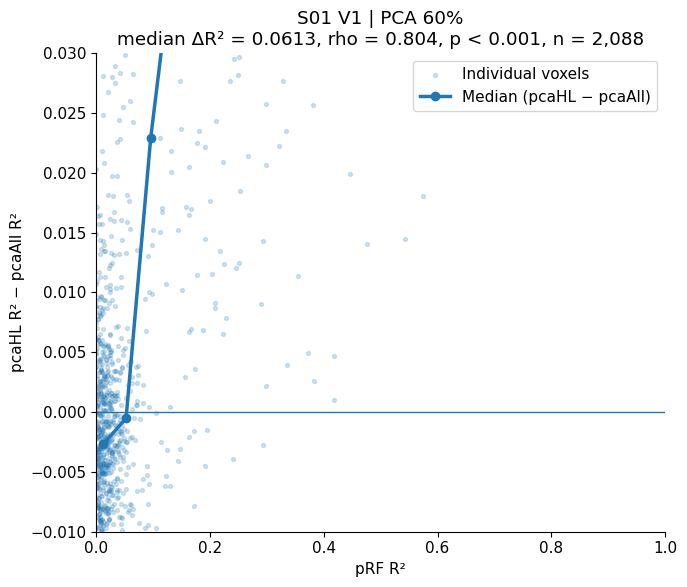

In [108]:
binned_delta_df = plot_delta_r2_by_prf_r2(
    voxel_df_with_prf,
    subject=1,
    roi="V1",
    threshold=60,
    n_bins=25,
    min_validation_r2=-1.0,
    xlim=(0, 1),
    ylim=(-0.01, 0.03),
)

# inspect r2 in sp model

In [109]:
import os
import pickle
import numpy as np
from google.colab import drive

# ============================================================
# MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive", force_remount=True)


# ============================================================
# FULL FILE PATH
# ============================================================
REGRESS_FILE = (
    "/content/drive/MyDrive/V1_Drift/"
    "repDrift_expand/"
    "regressSessCombineROI_sub8.pkl"
)


# ============================================================
# CHECK THAT THE FILE EXISTS
# ============================================================
if not os.path.exists(REGRESS_FILE):
    raise FileNotFoundError(
        f"Could not find the combined steerable-pyramid file:\n{REGRESS_FILE}"
    )

print("Loading:")
print(REGRESS_FILE)


# ============================================================
# LOAD FILE
# ============================================================
with open(REGRESS_FILE, "rb") as f:
    perm = pickle.load(f)

print("\nFile loaded successfully.")
print("Object type:", type(perm))


# ============================================================
# HELPER FOR DESCRIBING VARIABLES
# ============================================================
def describe_value(name, value, indent=""):
    if isinstance(value, np.ndarray):
        print(
            f"{indent}{name:35s} "
            f"type=np.ndarray, "
            f"shape={value.shape}, "
            f"dtype={value.dtype}"
        )

    elif isinstance(value, list):
        print(
            f"{indent}{name:35s} "
            f"type=list, "
            f"length={len(value)}"
        )

        if len(value) > 0:
            first = value[0]

            if isinstance(first, np.ndarray):
                print(
                    f"{indent}    first element: "
                    f"shape={first.shape}, "
                    f"dtype={first.dtype}"
                )
            else:
                print(
                    f"{indent}    first element type: "
                    f"{type(first)}"
                )

    elif isinstance(value, dict):
        print(
            f"{indent}{name:35s} "
            f"type=dict, "
            f"keys={list(value.keys())}"
        )

    else:
        print(
            f"{indent}{name:35s} "
            f"type={type(value)}, "
            f"value={value}"
        )


# ============================================================
# PRINT ALL TOP-LEVEL KEYS
# ============================================================
print("\n" + "=" * 80)
print("ALL TOP-LEVEL KEYS")
print("=" * 80)

if isinstance(perm, dict):
    for key, value in perm.items():
        describe_value(key, value)
else:
    raise TypeError(
        "Expected the pickle to contain a dictionary, "
        f"but found {type(perm)}"
    )


# ============================================================
# PRINT ONLY R2-RELATED KEYS
# ============================================================
print("\n" + "=" * 80)
print("R2-RELATED KEYS")
print("=" * 80)

r2_keys = [
    key for key in perm.keys()
    if "r2" in key.lower()
]

if len(r2_keys) == 0:
    print("No top-level key containing 'r2' was found.")
else:
    for key in r2_keys:
        describe_value(key, perm[key])


# ============================================================
# PRINT PEARSON-RELATED KEYS
# ============================================================
print("\n" + "=" * 80)
print("PEARSON-RELATED KEYS")
print("=" * 80)

pearson_keys = [
    key for key in perm.keys()
    if "pearson" in key.lower()
]

if len(pearson_keys) == 0:
    print("No top-level key containing 'pearson' was found.")
else:
    for key in pearson_keys:
        describe_value(key, perm[key])


# ============================================================
# INSPECT KNOWN CROSS-SESSION VARIABLES
# ============================================================
print("\n" + "=" * 80)
print("KNOWN CROSS-SESSION VARIABLES")
print("=" * 80)

known_keys = [
    "subjects",
    "subSessions",
    "r2oriSplit",
    "r2oriPerm",
    "pearsonRori",
    "pearsonOriPerm",
]

for key in known_keys:
    if key in perm:
        describe_value(key, perm[key])
    else:
        print(f"{key:35s} NOT FOUND")


# ============================================================
# INSPECT ROI ELEMENT SHAPES
# ============================================================
print("\n" + "=" * 80)
print("ROI ELEMENT SHAPES FOR R2-RELATED VARIABLES")
print("=" * 80)

roi_labels = {
    0: "V1",
    1: "V2",
    2: "V3",
    3: "hV4",
}

for key in r2_keys:
    value = perm[key]

    if isinstance(value, list):
        print(f"\n{key}:")

        for roi_idx, roi_value in enumerate(value):
            roi_name = roi_labels.get(
                roi_idx,
                f"ROI index {roi_idx}"
            )

            roi_array = np.asarray(roi_value)

            print(
                f"  {roi_name:5s}: "
                f"shape={roi_array.shape}, "
                f"dtype={roi_array.dtype}"
            )

    elif isinstance(value, np.ndarray):
        print(
            f"\n{key}: array shape={value.shape}"
        )

Mounted at /content/drive
Loading:
/content/drive/MyDrive/V1_Drift/repDrift_expand/regressSessCombineROI_sub8.pkl

File loaded successfully.
Object type: <class 'dict'>

ALL TOP-LEVEL KEYS
allRoiPrf                           type=list, length=4
    first element type: <class 'dict'>
roiNsdCorr                          type=list, length=4
    first element: shape=(31, 1074, 30), dtype=float32
roiNsdOriCorr                       type=list, length=4
    first element: shape=(31, 1074, 30), dtype=float32
roiNsdOriR2                         type=list, length=4
    first element: shape=(31, 1074, 30), dtype=float32
roiNsdR2                            type=list, length=4
    first element: shape=(31, 1074, 30), dtype=float32
roiNsdOriRss                        type=list, length=4
    first element: shape=(31, 1074, 30), dtype=float64
roiNsdRss                           type=list, length=4
    first element: shape=(31, 1074, 30), dtype=float64
numregions                          type=<class 'i

In [110]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# SETTINGS
# ============================================================

ROOT = (
    "/content/drive/MyDrive/V1_Drift/"
    "repDrift_expand"
)

SUBJECTS = range(1, 9)
ROI_LABELS = ["V1", "V2", "V3", "hV4"]

rows = []

# ============================================================
# LOAD ALL SUBJECTS
# ============================================================

for subject in SUBJECTS:

    regress_file = os.path.join(
        ROOT,
        f"regressSessCombineROI_sub{subject}.pkl"
    )

    if not os.path.exists(regress_file):
        print(f"Missing subject {subject}: {regress_file}")
        continue

    print(f"Loading subject {subject}")

    with open(regress_file, "rb") as f:
        regress = pickle.load(f)

    r2_within_all = regress["roiNsdOriR2within"]
    corr_all = regress["roiNsdOriCorr"]

    for roi_idx, roi_name in enumerate(ROI_LABELS):

        # ====================================================
        # R² WITHIN
        #
        # Shape: 31 × voxels
        # Rows 0–29: individual sessions
        # Row 30: mean across the 30 sessions
        # ====================================================

        roi_r2_within = np.asarray(
            r2_within_all[roi_idx],
            dtype=float
        )

        if roi_r2_within.ndim != 2:
            raise ValueError(
                f"Unexpected R² shape for S{subject} {roi_name}: "
                f"{roi_r2_within.shape}"
            )

        # One mean-within-session R² value per voxel
        voxel_r2_within = roi_r2_within[-1, :]

        # Check that the last row is the mean of rows 0–29
        calculated_r2_mean = np.nanmean(
            roi_r2_within[:-1, :],
            axis=0
        )

        max_r2_difference = np.nanmax(
            np.abs(voxel_r2_within - calculated_r2_mean)
        )

        print(
            f"S{subject} {roi_name}: "
            f"last-row R² check = {max_r2_difference:.8f}"
        )

        # ====================================================
        # PEARSON WITHIN
        #
        # Shape: 31 × voxels × 30 tested sessions
        #
        # For each session, take:
        # model fitted to session i, tested on session i
        # ====================================================

        roi_corr = np.asarray(
            corr_all[roi_idx],
            dtype=float
        )

        if roi_corr.ndim != 3:
            raise ValueError(
                f"Unexpected correlation shape for "
                f"S{subject} {roi_name}: {roi_corr.shape}"
            )

        n_sessions = roi_corr.shape[2]

        if roi_corr.shape[0] < n_sessions:
            raise ValueError(
                f"Not enough fitting rows for S{subject} {roi_name}: "
                f"{roi_corr.shape}"
            )

        pearson_within_sessions = np.stack(
            [
                roi_corr[session, :, session]
                for session in range(n_sessions)
            ],
            axis=0
        )

        # Shape: 30 sessions × voxels
        # One mean within-session Pearson r per voxel
        voxel_pearson_within = np.nanmean(
            pearson_within_sessions,
            axis=0
        )

        # ====================================================
        # CHECK VOXEL ALIGNMENT
        # ====================================================

        if voxel_r2_within.shape != voxel_pearson_within.shape:
            raise ValueError(
                f"Voxel mismatch for S{subject} {roi_name}: "
                f"R²={voxel_r2_within.shape}, "
                f"Pearson={voxel_pearson_within.shape}"
            )

        # ====================================================
        # SAVE VOXEL-LEVEL VALUES
        # ====================================================

        for voxel_idx in range(len(voxel_r2_within)):
            rows.append(
                {
                    "subject": subject,
                    "roi": roi_name,
                    "voxel": voxel_idx,
                    "within_r2": voxel_r2_within[voxel_idx],
                    "within_pearson": voxel_pearson_within[voxel_idx],
                }
            )

# ============================================================
# BUILD VOXEL-LEVEL DATAFRAME
# ============================================================

sp_fit_df = pd.DataFrame(rows)

print("\nVoxel-level dataframe shape:", sp_fit_df.shape)
print(sp_fit_df.head())

Loading subject 1
S1 V1: last-row R² check = 0.00000009
S1 V2: last-row R² check = 0.00000005
S1 V3: last-row R² check = 0.00000004
S1 hV4: last-row R² check = 0.00000004
Loading subject 2


/tmp/ipykernel_907/3268675024.py:121: RuntimeWarning: Mean of empty slice
  voxel_pearson_within = np.nanmean(


S2 V1: last-row R² check = 0.00000008
S2 V2: last-row R² check = 0.00000004
S2 V3: last-row R² check = 0.00000005
S2 hV4: last-row R² check = 0.00000004
Loading subject 3
S3 V1: last-row R² check = 0.00000007
S3 V2: last-row R² check = 0.00000005
S3 V3: last-row R² check = 0.00000003
S3 hV4: last-row R² check = 0.00000003
Loading subject 4
S4 V1: last-row R² check = 0.00000006
S4 V2: last-row R² check = 0.00000006
S4 V3: last-row R² check = 0.00000003
S4 hV4: last-row R² check = 0.00000002
Loading subject 5
S5 V1: last-row R² check = 0.00000005
S5 V2: last-row R² check = 0.00000001
S5 V3: last-row R² check = 0.00000003
S5 hV4: last-row R² check = 0.00000003
Loading subject 6
S6 V1: last-row R² check = 0.00000006
S6 V2: last-row R² check = 0.00000001
S6 V3: last-row R² check = 0.00000002
S6 hV4: last-row R² check = 0.00000001
Loading subject 7
S7 V1: last-row R² check = 0.00000005
S7 V2: last-row R² check = 0.00000005
S7 V3: last-row R² check = 0.00000003
S7 hV4: last-row R² check = 0.0

In [ ]:
subject_roi_summary = (
    sp_fit_df
    .groupby(["subject", "roi"], as_index=False)
    .agg(
        n_voxels=("voxel", "count"),
        median_r2=("within_r2", "median"),
        median_pearson=("within_pearson", "median"),
        mean_r2=("within_r2", "mean"),
        mean_pearson=("within_pearson", "mean"),
    )
)

subject_roi_summary["roi"] = pd.Categorical(
    subject_roi_summary["roi"],
    categories=ROI_LABELS,
    ordered=True
)

subject_roi_summary = subject_roi_summary.sort_values(
    ["subject", "roi"]
).reset_index(drop=True)

print("\nSubject × ROI summary:")
print(subject_roi_summary)


Subject × ROI summary:
    subject  roi  n_voxels  median_r2  median_pearson   mean_r2  mean_pearson
0         1   V1      1350   0.125020        0.350991  0.133674      0.347380
1         1   V2      1433   0.078304        0.276440  0.090852      0.284055
2         1   V3      1187   0.068423        0.258692  0.076399      0.263790
3         1  hV4       687   0.043991        0.207064  0.054877      0.223897
4         2   V1      1102   0.117437        0.338200  0.138508      0.343052
5         2   V2      1075   0.059285        0.236437  0.078946      0.260812
6         2   V3      1097   0.062085        0.244736  0.077285      0.260479
7         2  hV4       483   0.061263        0.244409  0.074523      0.258661
8         3   V1      1254   0.099846        0.309291  0.108430      0.307117
9         3   V2      1141   0.069389        0.257902  0.079443      0.265789
10        3   V3       928   0.054866        0.230517  0.058912      0.232640
11        3  hV4       426   0.044709   

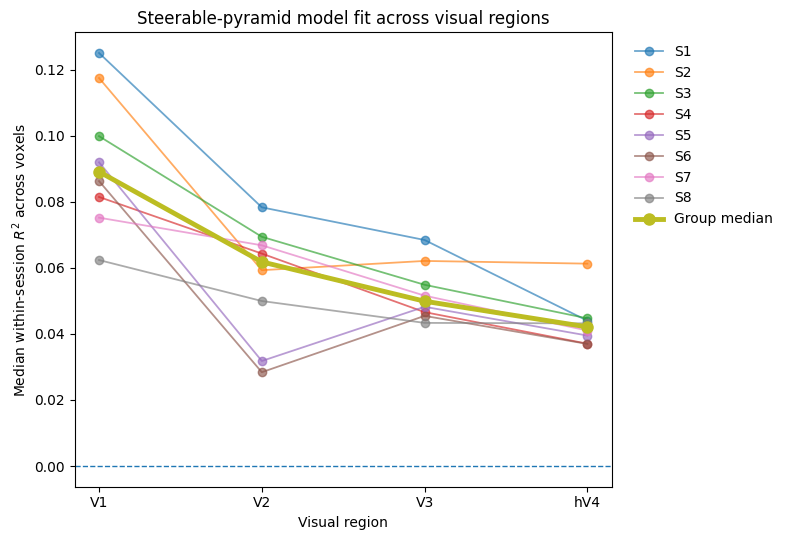

In [ ]:
def plot_subjects_across_rois(
    summary_df,
    value_column,
    ylabel,
    title,
    roi_order=("V1", "V2", "V3", "hV4"),
):
    plt.figure(figsize=(8, 5.5))

    x = np.arange(len(roi_order))

    # Individual subjects
    for subject in sorted(summary_df["subject"].unique()):

        subject_data = (
            summary_df[summary_df["subject"] == subject]
            .set_index("roi")
            .reindex(roi_order)
        )

        y = subject_data[value_column].to_numpy(dtype=float)

        plt.plot(
            x,
            y,
            marker="o",
            linewidth=1.3,
            alpha=0.65,
            label=f"S{subject}",
        )

    # Group median across subjects
    group_median = (
        summary_df
        .groupby("roi", observed=False)[value_column]
        .median()
        .reindex(roi_order)
    )

    plt.plot(
        x,
        group_median.to_numpy(dtype=float),
        marker="o",
        linewidth=3.5,
        markersize=8,
        label="Group median",
    )

    plt.xticks(x, roi_order)
    plt.axhline(0, linestyle="--", linewidth=1)

    plt.xlabel("Visual region")
    plt.ylabel(ylabel)
    plt.title(title)

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False,
    )

    plt.tight_layout()
    plt.show()


plot_subjects_across_rois(
    summary_df=subject_roi_summary,
    value_column="median_r2",
    ylabel="Median within-session $R^2$ across voxels",
    title="Steerable-pyramid model fit across visual regions",
)

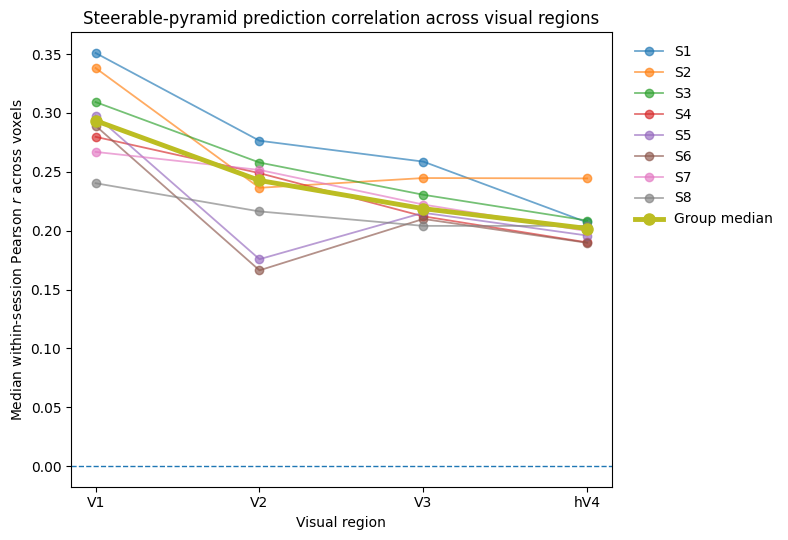

In [ ]:
plot_subjects_across_rois(
    summary_df=subject_roi_summary,
    value_column="median_pearson",
    ylabel="Median within-session Pearson $r$ across voxels",
    title="Steerable-pyramid prediction correlation across visual regions",
)

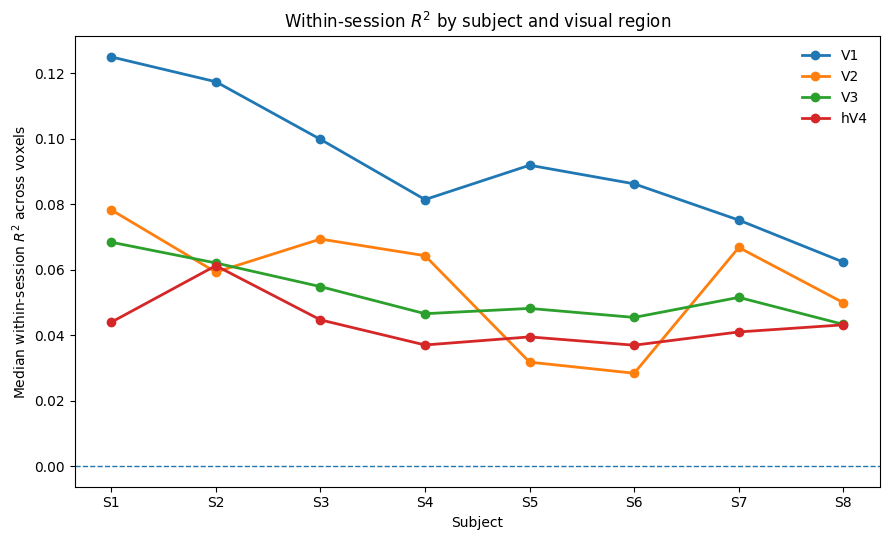

In [ ]:
def plot_rois_across_subjects(
    summary_df,
    value_column,
    ylabel,
    title,
    roi_order=("V1", "V2", "V3", "hV4"),
):
    plt.figure(figsize=(9, 5.5))

    subjects = sorted(summary_df["subject"].unique())
    x = np.arange(len(subjects))

    for roi in roi_order:

        roi_data = (
            summary_df[summary_df["roi"] == roi]
            .set_index("subject")
            .reindex(subjects)
        )

        y = roi_data[value_column].to_numpy(dtype=float)

        plt.plot(
            x,
            y,
            marker="o",
            linewidth=2,
            label=roi,
        )

    plt.xticks(
        x,
        [f"S{subject}" for subject in subjects]
    )

    plt.axhline(0, linestyle="--", linewidth=1)

    plt.xlabel("Subject")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(frameon=False)

    plt.tight_layout()
    plt.show()


plot_rois_across_subjects(
    summary_df=subject_roi_summary,
    value_column="median_r2",
    ylabel="Median within-session $R^2$ across voxels",
    title="Within-session $R^2$ by subject and visual region",
)

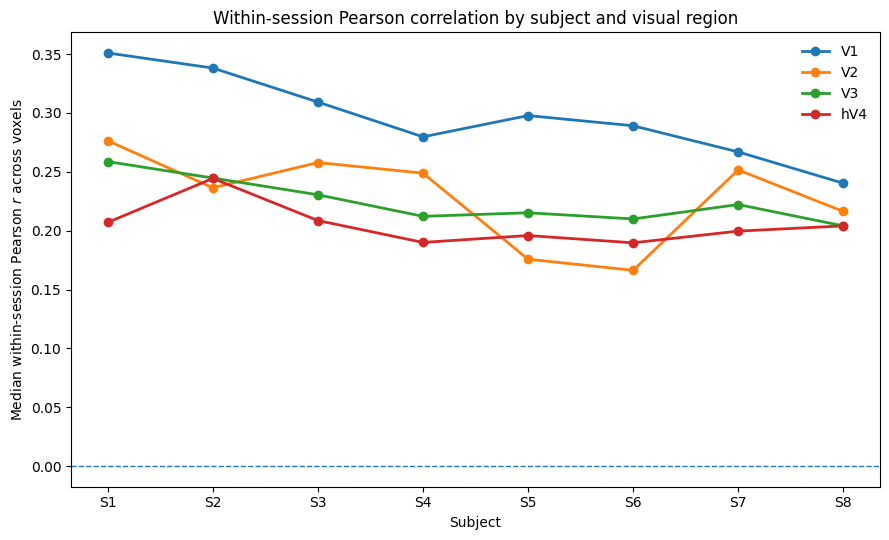

In [ ]:
plot_rois_across_subjects(
    summary_df=subject_roi_summary,
    value_column="median_pearson",
    ylabel="Median within-session Pearson $r$ across voxels",
    title="Within-session Pearson correlation by subject and visual region",
)